In [149]:
import numpy as np
from dataclasses import dataclass
import time
import argparse
import importlib
import matplotlib.pyplot as plt

In [150]:
# ============================================================
# MISC
# ============================================================
def hat(x):
    """Skew-symmetric matrix such that hat(x) @ y = x cross y"""
    x1, x2, x3 = x
    return np.array([[0.0, -x3,  x2], [x3,  0.0, -x1], [-x2, x1,  0.0]])

def orthonormalize(R):
    """Project a numerically drifted matrix onto SO(3)."""
    U, _, Vt = np.linalg.svd(R)
    Rproj = U @ Vt

    if np.linalg.det(Rproj) < 0.0: U[:, -1] *= -1.0; Rproj = U @ Vt
    return Rproj

def rotation_x(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]], dtype=float)

def rotation_y(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]], dtype=float)

def rotation_z(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]], dtype=float)

In [151]:
import math
import numpy as np
from typing import List, Dict
import xml.etree.ElementTree as ET
import mujoco
from xml.dom import minidom
# =====================================
# OpenCR Mujoco UNIVERSITY OF TORONTO
# =====================================

# Helper function to normalize inputs
ACTUATOR_NAMES = [
    "act_seg_0_t0", "act_seg_0_t1", "act_seg_0_t2",  # Segment 0
    "act_seg_1_t0", "act_seg_1_t1", "act_seg_1_t2"   # Segment 1
]

def rotation_to_quat(R):
    """Convert a proper rotation matrix to MuJoCo quaternion [w,x,y,z]."""
    if R.shape != (3, 3) or not np.allclose(R.T @ R, np.eye(3), atol=1e-8) or not np.isclose(np.linalg.det(R), 1.0, atol=1e-8):
        raise ValueError("base_rotation must be a proper rotation matrix in SO(3)")
    tr = np.trace(R)
    if tr > 0:
        s = 2.0 * np.sqrt(tr + 1.0)
        q = [0.25*s, (R[2,1]-R[1,2])/s, (R[0,2]-R[2,0])/s, (R[1,0]-R[0,1])/s]
    elif R[0,0] > R[1,1] and R[0,0] > R[2,2]:
        s = 2.0 * np.sqrt(1.0 + R[0,0] - R[1,1] - R[2,2])
        q = [(R[2,1]-R[1,2])/s, 0.25*s, (R[0,1]+R[1,0])/s, (R[0,2]+R[2,0])/s]
    elif R[1,1] > R[2,2]:
        s = 2.0 * np.sqrt(1.0 + R[1,1] - R[0,0] - R[2,2])
        q = [(R[0,2]-R[2,0])/s, (R[0,1]+R[1,0])/s, 0.25*s, (R[1,2]+R[2,1])/s]
    else:
        s = 2.0 * np.sqrt(1.0 + R[2,2] - R[0,0] - R[1,1])
        q = [(R[1,0]-R[0,1])/s, (R[0,2]+R[2,0])/s, (R[1,2]+R[2,1])/s, 0.25*s]
    return np.asarray(q) / np.linalg.norm(q)

def generate_tdcr_xml_from_config(config: Dict, output_filename: str = "generated_tdcr.xml"):
    """Generate a MuJoCo TDCR XML from the robot configuration."""

    # Base pose: base-local coordinates mapped into the world frame
    base_position = np.asarray(config.get("base_position", [0, 0, 0]), dtype=float)
    base_rotation = np.asarray(config.get("base_rotation", np.eye(3)), dtype=float)
    if base_position.shape != (3,):
        raise ValueError("base_position must have shape (3,)")
    base_quat = rotation_to_quat(base_rotation)

    # 1. READ CONFIGURATION
    num_segments = int(config["num_segments"])
    links_per_segment_cfg = config["links_per_segment"]
    segment_lengths_cfg = config["segment_lengths"]

    links_per_segment = [int(links_per_segment_cfg[str(i + 1)]) for i in range(num_segments)]
    segment_lengths = [float(segment_lengths_cfg[str(i + 1)]) for i in range(num_segments)]

    if len(links_per_segment) != num_segments:
        raise ValueError("links_per_segment does not match num_segments")
    if len(segment_lengths) != num_segments:
        raise ValueError("segment_lengths does not match num_segments")

    material = config["material_properties"]
    E = float(material["youngs_modulus"])
    nu = float(material["poisson_ratio"])
    density = float(material["density"])
    outer_radius = float(material["outer_radius"])
    inner_radius = float(material.get("inner_radius", 0.0))
    
    actuation_details = config["actuation_details"]
    tendon_segments = actuation_details["segments"]
    num_tendons_per_seg = []
    tendon_radii = []

    for s in range(num_segments):
        tendon_data = tendon_segments[s]
        num_tendons_per_seg.append(int(tendon_data["number_of_tendons"]))
        tendon_radii.append(float(tendon_data["distance_to_backbone"]))

    segment_angle_offsets = config.get("segment_angle_offsets", [0.0] * num_segments)
    if len(segment_angle_offsets) != num_segments:
        raise ValueError("segment_angle_offsets must have one value per segment")
    segment_angle_offsets = [float(x) for x in segment_angle_offsets]

    joints_per_link = int(config.get("joints_per_link", 3))
    enable_x = joints_per_link >= 1
    enable_y = joints_per_link >= 2
    enable_z = joints_per_link >= 3

    # 2. MATERIAL / SECTION CALCULATIONS
    G = E / (2.0 * (1.0 + nu))
    Ixx = math.pi / 4.0 * (outer_radius**4 - inner_radius**4)
    Iyy = Ixx
    J = math.pi / 2.0 * (outer_radius**4 - inner_radius**4)

    # 3. CALCULATE SEGMENT / LINK PROPERTIES
    segment_properties = []
    total_length = 0.0
    total_links = 0

    for s in range(num_segments):
        Ls = segment_lengths[s]
        Ns = links_per_segment[s]
        li = Ls / Ns
        kx = E * Ixx / li
        ky = E * Iyy / li
        kz = G * J / li
        link_volume = math.pi * (outer_radius**2 - inner_radius**2) * li
        link_mass = density * link_volume

        segment_properties.append({
            "length": Ls,
            "num_links": Ns,
            "link_length": li,
            "kx": kx,
            "ky": ky,
            "kz": kz,
            "link_mass": link_mass
        })
        total_length += Ls
        total_links += Ns

    # 4. MUJOCO ROOT
    mujoco = ET.Element("mujoco")
    ET.SubElement(mujoco, "compiler", angle="radian", autolimits="true")
    gravity = np.asarray(config["gravity"], dtype=float)
    ET.SubElement(mujoco, "option", gravity=" ".join(map(str, gravity)), noslip_iterations="1")
    #ET.SubElement(mujoco, "option", gravity=gravity, noslip_iterations="1")

    # 5. ASSETS
    asset = ET.SubElement(mujoco, "asset")
    ET.SubElement(asset, "texture", type="skybox", builtin="gradient", rgb1="1 1 1", rgb2=".6 .8 1", width="256", height="256")

    # 6. DEFAULTS
    default = ET.SubElement(mujoco, "default")
    ET.SubElement(default, "geom", contype="0", conaffinity="0", condim="1", friction="1.0 0.005 0.0001")
    collision_default = ET.SubElement(default, "default", {"class": "tdcr_collision"})
    ET.SubElement(collision_default, "geom", contype="1", conaffinity="1", condim="3", friction="1.0 0.005 0.0001", solimp="0.8 0.95 0.001")

    # 7. JOINT DEFAULTS
    for s in range(num_segments):
        props = segment_properties[s]
        kx, ky, kz = props["kx"], props["ky"], props["kz"]
        damping_str = str(config.get("joint_damping", 0.001))

        ET.SubElement(default, "default", {"class": f"segment_{s}_x_joint"}).append(
            ET.Element("joint", {"type": "hinge", "axis": "0 0 1", "stiffness": str(kz), "damping": damping_str, "limited": "false"})
        )
        ET.SubElement(default, "default", {"class": f"segment_{s}_y_joint"}).append(
            ET.Element("joint", {"type": "hinge", "axis": "0 1 0", "stiffness": str(ky), "damping": damping_str, "limited": "false"})
        )
        ET.SubElement(default, "default", {"class": f"segment_{s}_z_joint"}).append(
            ET.Element("joint", {"type": "hinge", "axis": "1 0 0", "stiffness": str(kx), "damping": damping_str, "limited": "false"})
        )

    # 8. WORLDBODY
    worldbody = ET.SubElement(mujoco, "worldbody")
    #mocap_base = ET.SubElement(worldbody, "body", {"name": "mocap_base", "pos": "0 0 0", "mocap": "true"})
    mocap_base = ET.SubElement(worldbody, "body", {
        "name": "mocap_base",
        "pos": " ".join(f"{x:.12g}" for x in base_position),
        "quat": " ".join(f"{x:.12g}" for x in base_quat),
        "mocap": "true"
    })

    # 9. HELPER: TENDON XY POSITION
    def get_tendon_xy(tendon_index: int, number_of_tendons: int, radius: float, angle_offset: float):
        angle = angle_offset + 2.0 * math.pi * tendon_index / number_of_tendons
        return radius * math.cos(angle), radius * math.sin(angle)

    # 10. LINK INDEX MAP
    segment_link_ranges = []
    current_link = 1
    for s in range(num_segments):
        start_link = current_link
        end_link = current_link + links_per_segment[s] - 1
        segment_link_ranges.append((start_link, end_link))
        current_link = end_link + 1

    # 11. BASE LINK
    first_li = segment_properties[0]["link_length"]
    base_link = ET.SubElement(mocap_base, "body", {"name": "link_0", "pos": "0 0 0"})
    base_mass = density * (math.pi * (outer_radius**2 - inner_radius**2) * (first_li / 2.0))

    ET.SubElement(base_link, "geom", {
        "fromto": f"0 0 0 0 0 {first_li/2:.9f}",
        "size": f"{outer_radius:.9f}",
        "type": "cylinder",
        "rgba": "0.274 0.274 0.274 1.000",
        "mass": f"{base_mass:.12g}",
        "name": "geom_0",
        "class": "tdcr_collision"
    })

    for s in range(num_segments):
        radius, offset, nt = tendon_radii[s], segment_angle_offsets[s], num_tendons_per_seg[s]
        for t in range(nt):
            tx, ty = get_tendon_xy(t, nt, radius, offset)
            ET.SubElement(base_link, "site", {"name": f"l_0_s{s}_s1_t{t}", "pos": f"{tx:.9f} {ty:.9f} 0", "rgba": "0 0 0 0"})
            ET.SubElement(base_link, "site", {"name": f"l_0_s{s}_s2_t{t}", "pos": f"{tx:.9f} {ty:.9f} {first_li/2:.9f}", "rgba": "0 0 0 0"})

    # 12. BUILD KINEMATIC TREE
    parent_body = base_link
    global_link_idx = 1

    for s in range(num_segments):
        props = segment_properties[s]
        li, link_mass = props["link_length"], props["link_mass"]
        start_link, end_link = segment_link_ranges[s]
        nt, radius, offset = num_tendons_per_seg[s], tendon_radii[s], segment_angle_offsets[s]

        for l_in_seg in range(links_per_segment[s]):
            z_pos = li / 2.0 if global_link_idx == 1 else li
            body = ET.SubElement(parent_body, "body", {"name": f"link_{global_link_idx}", "pos": f"0 0 {z_pos:.9f}"})

            is_final_link = (global_link_idx == total_links)
            geom_length = li / 2.0 if is_final_link else li
            geom_mass = link_mass / 2.0 if is_final_link else link_mass
            rgba = "0.274 0.274 0.274 1.000" if s % 2 == 0 else "0.574 0.574 0.574 1.000"

            ET.SubElement(body, "geom", {
                "fromto": f"0 0 0 0 0 {geom_length:.9f}",
                "size": f"{outer_radius:.9f}",
                "type": "cylinder",
                "rgba": rgba,
                "mass": f"{geom_mass:.12g}",
                "name": f"geom_{global_link_idx}",
                "class": "tdcr_collision"
            })

            if enable_x:
                ET.SubElement(body, "joint", {"class": f"segment_{s}_x_joint", "name": f"joint_{global_link_idx}_x"})
            if enable_y:
                ET.SubElement(body, "joint", {"class": f"segment_{s}_y_joint", "name": f"joint_{global_link_idx}_y"})
            if enable_z:
                ET.SubElement(body, "joint", {"class": f"segment_{s}_z_joint", "name": f"joint_{global_link_idx}_z"})

            for t in range(nt):
                tx, ty = get_tendon_xy(t, nt, radius, offset)
                if not is_final_link:
                    ET.SubElement(body, "site", {"name": f"l_{global_link_idx}_s{s}_s1_t{t}", "pos": f"{tx:.9f} {ty:.9f} {li/2:.9f}", "rgba": "0 0 0 0"})
                ET.SubElement(body, "site", {"name": f"l_{global_link_idx}_s{s}_s2_t{t}", "pos": f"{tx:.9f} {ty:.9f} {geom_length:.9f}", "rgba": "0 0 0 0"})

            parent_body = body
            global_link_idx += 1

    
    # 13. END EFFECTOR + OPTIONAL TIP PAYLOAD
    final_li = segment_properties[-1]["link_length"]
    ee_body = ET.SubElement(parent_body, "body", {
        "name": "EE_pos",
        "pos": f"0 0 {final_li/2:.9f}"
    })
    ET.SubElement(ee_body, "site", {
        "name": "force_site_tip",
        "pos": "0 0 0",
        "size": "0.003",
        "rgba": "1 0 0 0.8",
        "type": "sphere"
    })

    # Optional payload is attached directly at the free-tip origin.
    payload_cfg = config.get("tip_payload", {})
    if payload_cfg.get("enabled", False):
        payload_mass = float(payload_cfg.get("mass", 0.0))
        payload_radius = float(payload_cfg.get("radius", 0.003))
        if payload_mass <= 0 or payload_radius <= 0:
            raise ValueError("Tip payload mass and radius must be positive.")

        payload_body = ET.SubElement(ee_body, "body", {
            "name": "tip_payload",
            "pos": "0 0 0"
        })
        ET.SubElement(payload_body, "geom", {
            "name": "tip_payload_geom",
            "type": "sphere",
            "size": f"{payload_radius:.9g}",
            "mass": f"{payload_mass:.9g}",
            "rgba": "1 0.2 0.1 1",
            "contype": "0",
            "conaffinity": "0"
        })
        print(f"Tip payload enabled: {payload_mass:.6g} kg")
    else:
        print("Tip payload disabled.")


    # 14. TENDONS
    tendon_elem = ET.SubElement(mujoco, "tendon")
    colors = ["1 0 0 1", "0 1 0 1", "0 0 1 1", "1 0.5 0 1", "0.5 1 0 1", "0 0.5 1 1"]

    for s in range(num_segments):
        start_link, end_link = segment_link_ranges[s]
        nt = num_tendons_per_seg[s]

        for t in range(nt):
            tendon_name = f"seg_{s}_tendon_{t}"
            color = colors[(s * nt + t) % len(colors)]
            spatial = ET.SubElement(tendon_elem, "spatial", {"name": tendon_name, "width": "0.001", "rgba": color})

            ET.SubElement(spatial, "site", {"site": f"l_0_s{s}_s1_t{t}"})
            ET.SubElement(spatial, "site", {"site": f"l_0_s{s}_s2_t{t}"})

            for l_idx in range(start_link, end_link + 1):
                if l_idx != total_links:
                    ET.SubElement(spatial, "site", {"site": f"l_{l_idx}_s{s}_s1_t{t}"})
                ET.SubElement(spatial, "site", {"site": f"l_{l_idx}_s{s}_s2_t{t}"})

    # 15. ACTUATORS
    actuator_elem = ET.SubElement(mujoco, "actuator")
    actuator_props = config.get("actuator_properties", {})
    force_limited = actuator_props.get("tendon_forcelimited", "true")
    force_range = actuator_props.get("tendon_forcerange", "-1500 0")
    pretension = float(actuator_props.get("tendon_pretension", 0.0))

    for s in range(num_segments):
        for t in range(num_tendons_per_seg[s]):
            tendon_name = f"seg_{s}_tendon_{t}"
            actuator_name = f"seg_{s}_ten_{t}"
            ET.SubElement(actuator_elem, "motor", {
                "name": actuator_name,
                "tendon": tendon_name,
                "gear": "1",
                "forcelimited": str(force_limited).lower(),
                "forcerange": force_range
            })

    # 16. KEYFRAME
    ctrl_values = [-pretension for s in range(num_segments) for _ in range(num_tendons_per_seg[s])]
    keyframe = ET.SubElement(mujoco, "keyframe")
    ET.SubElement(keyframe, "key", {"name": "pretension", "ctrl": " ".join(f"{x:g}" for x in ctrl_values)})

    # 17. SELF-COLLISION EXCLUSIONS
    contact = ET.SubElement(mujoco, "contact")
    if config.get("disable_self_collision", True):
        link_names = [f"link_{i}" for i in range(0, total_links + 1)]
        for i in range(len(link_names)):
            for j in range(i + 1, len(link_names)):
                ET.SubElement(contact, "exclude", {"body1": link_names[i], "body2": link_names[j]})

    # 18. XML FORMAT
    xml_bytes = ET.tostring(mujoco, encoding="utf-8")
    xml_str = minidom.parseString(xml_bytes).toprettyxml(indent="    ")
    xml_str = "\n".join(line for line in xml_str.splitlines() if line.strip())

    with open(output_filename, "w", encoding="utf-8") as f:
        f.write(xml_str)

    # 19. PRINT CALCULATED PARAMETERS
    print("\n" + "=" * 70)
    print("TDCR MuJoCo XML GENERATED")
    print("=" * 70)
    print(f"Output       : {output_filename}")
    print(f"Segments     : {num_segments}")
    print(f"Total links  : {total_links}")
    print(f"Total length : {total_length:.6f} m")
    print(f"E            : {E:.6e} Pa")
    print(f"nu           : {nu:.6f}")
    print(f"G            : {G:.6e} Pa")
    print(f"Radius       : {outer_radius:.6f} m")
    print(f"Ixx = Iyy    : {Ixx:.6e} m^4")
    print(f"J            : {J:.6e} m^4")
    print("gravity      : ",gravity ,"m/sec^2")

    print("\nSEGMENT PARAMETERS")
    print("-" * 70)
    for s, props in enumerate(segment_properties):
        print(f"Segment {s + 1}")
        print(f"  Ls        = {props['length']:.6f} m")
        print(f"  N         = {props['num_links']}")
        print(f"  li        = {props['link_length']:.6f} m")
        print(f"  kx        = {props['kx']:.12g} N*m/rad")
        print(f"  ky        = {props['ky']:.12g} N*m/rad")
        print(f"  kz        = {props['kz']:.12g} N*m/rad")
        print(f"  link mass = {props['link_mass']:.12g} kg")
    print("=" * 70)
    
# ---------------------------------------------------------------------------
# 2. MuJoCo Helpers
# ---------------------------------------------------------------------------
def load_model(xml_path):
    model = mujoco.MjModel.from_xml_path(str(xml_path))
    data = mujoco.MjData(model)

    model.opt.integrator = mujoco.mjtIntegrator.mjINT_IMPLICITFAST
    model.opt.timestep = 5e-4
    model.opt.gravity[:] = 0.0

    mujoco.mj_forward(model, data)

    #print(f"MuJoCo Model Loaded: nq={model.nq}, nv={model.nv}, nu={model.nu}, ntendon={model.ntendon}")
    #print("Actuators:", [model.actuator(i).name for i in range(model.nu)])
    return model, data

def extract_dynamics_matrices(model, data):
    """Extract MuJoCo dynamics at the current qpos and qvel."""
    nv, nu = model.nv, model.nu
    mujoco.mj_forward(model, data)

    # M(q): full generalized mass matrix
    M = np.zeros((nv, nv))
    mujoco.mj_fullM(model, M, data.qM)

    # MuJoCo bias forces: Coriolis, centrifugal and gravity terms
    h_bias = data.qfrc_bias.copy()

    # Passive generalized forces: spring, damping and other passive effects
    tau_passive = data.qfrc_passive.copy()

    # Actuator generalized forces at the current control input
    tau_actuator = data.qfrc_actuator.copy()

    # Identify the local actuator-to-generalized-force map for positive
    # tendon tensions, using the existing convention ctrl = -tension.
    ctrl0 = data.ctrl.copy()
    data.ctrl[:] = 0.0
    mujoco.mj_forward(model, data)
    tau0 = data.qfrc_actuator.copy()
    B_T = np.zeros((nv, nu))
    for j in range(nu):
        data.ctrl[:] = 0.0
        data.ctrl[j] = -1.0
        mujoco.mj_forward(model, data)
        B_T[:, j] = data.qfrc_actuator - tau0
    data.ctrl[:] = ctrl0
    mujoco.mj_forward(model, data)

    # Nominal joint stiffness and damping matrices in generalized coordinates.
    # This assumes hinge joints, as generated by your current model.
    K = np.zeros((nv, nv))
    D = np.zeros((nv, nv))
    for j in range(model.njnt):
        if model.jnt_type[j] == mujoco.mjtJoint.mjJNT_HINGE:
            d = model.jnt_dofadr[j]
            K[d, d] = model.jnt_stiffness[j]
            D[d, d] = model.dof_damping[d]

    # Store the current passive-force contribution separately.
    return {
        "M": M,
        "h_bias": h_bias,
        "tau_passive": tau_passive,
        "K": K,
        "D": D,
        "B_T": B_T,
        "tau_actuator": tau_actuator,
        "qpos": data.qpos.copy(),
        "qvel": data.qvel.copy(),
        "qacc": data.qacc.copy()
    }

def get_actuator_ids(model):
    ids = []
    # Reads only the actuators defined in the loaded XML file dynamically
    for i in range(model.nu):
        ids.append(i)
    return ids

def apply_tensions(model, data, tensions, act_ids):
    data.ctrl[:] = 0.0
    for i, act_id in enumerate(act_ids):
        data.ctrl[act_id] = -float(tensions[i])


def extract_joint_angles(model, data):
    angles = np.zeros(model.njnt)
    for j in range(model.njnt):
        angles[j] = data.qpos[model.jnt_qposadr[j]]
    return angles


def tendon_lengths(model, data):
    return np.asarray(data.ten_length[:model.ntendon], dtype=float).copy()

# ---------------------------------------------------------------------------
# 3. Interactive Keyboard Controller
# ---------------------------------------------------------------------------
class FlexibleTendonController:
    def __init__(self, num_actuators, step=0.2, maximum=10.0,tension_funcs=None):
        self.num_actuators = num_actuators
        self.tension = np.zeros(num_actuators, dtype=float)
        self.step = step
        self.maximum = maximum
        self.paused = False
        self.quit = False
        self.tension_funcs = tension_funcs

    def key_callback(self, key):
        # Segment 0 (T1, T2, T3)
        if key == ord("1") and self.num_actuators > 0:
            self.tension[0] = min(self.maximum, self.tension[0] + self.step)
        elif key == ord("q") and self.num_actuators > 0:
            self.tension[0] = max(0.0, self.tension[0] - self.step)

        elif key == ord("2") and self.num_actuators > 1:
            self.tension[1] = min(self.maximum, self.tension[1] + self.step)
        elif key == ord("w") and self.num_actuators > 1:
            self.tension[1] = max(0.0, self.tension[1] - self.step)

        elif key == ord("3") and self.num_actuators > 2:
            self.tension[2] = min(self.maximum, self.tension[2] + self.step)
        elif key == ord("e") and self.num_actuators > 2:
            self.tension[2] = max(0.0, self.tension[2] - self.step)

        # Segment 1 (T4, T5, T6 - processed only if model has >3 actuators)
        elif key == ord("4") and self.num_actuators > 3:
            self.tension[3] = min(self.maximum, self.tension[3] + self.step)
        elif key == ord("a") and self.num_actuators > 3:
            self.tension[3] = max(0.0, self.tension[3] - self.step)

        elif key == ord("5") and self.num_actuators > 4:
            self.tension[4] = min(self.maximum, self.tension[4] + self.step)
        elif key == ord("s") and self.num_actuators > 4:
            self.tension[4] = max(0.0, self.tension[4] - self.step)

        elif key == ord("6") and self.num_actuators > 5:
            self.tension[5] = min(self.maximum, self.tension[5] + self.step)
        elif key == ord("d") and self.num_actuators > 5:
            self.tension[5] = max(0.0, self.tension[5] - self.step)

        # Global Controls
        elif key == ord("r"):
            self.tension[:] = 0.0
        elif key == ord(" "):
            self.paused = not self.paused
        elif key == 27:  # ESC
            self.quit = True

    def print_status(self):
      # Segment 0 (Always present)
      s0_str = f"Seg0: [{self.tension[0]:4.1f}, {self.tension[1]:4.1f}, {self.tension[2]:4.1f}] N"
      
      # Segment 1 (Only format if the model has more than 3 actuators)
      if self.num_actuators > 3:
          s1_str = f" | Seg1: [{self.tension[3]:4.1f}, {self.tension[4]:4.1f}, {self.tension[5]:4.1f}] N"
      else:
          s1_str = ""
          
      print(f"\r{s0_str}{s1_str}", end="", flush=True)

    def update_tensions(self, current_time: float):
        """Evaluates time-varying tension functions if provided."""
        if self.tension_funcs is not None and not self.paused:
            for idx, func in enumerate(self.tension_funcs):
                if idx < self.num_actuators and callable(func):
                    # Evaluate dynamic profile and clip within bounds
                    val = float(func(current_time))
                    
                    self.tension[idx] = np.clip(val, 0, self.maximum)
                    #print(self.tension[idx])

def forward_dynamics_interactive(model, data, viewer, controller, act_ids, t_final=60.0, save_dt=0.005):
    nsteps = int(round(t_final / model.opt.timestep))
    save_every = max(1, int(round(save_dt / model.opt.timestep)))

    times, tips, lengths, tensions = [], [], [], []
    qpos_hist, qvel_hist, qacc_hist = [], [], []
    joint_angle_hist, joint_torque_hist, states_hist = [], [], []

    # 1. Pre-fetch End-Effector ID (Site first, fallback to Body)
    ee_site_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_SITE, "force_site_tip")
    ee_body_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "EE_pos")

    # 2. Pre-fetch and sort all link body IDs
    link_body_ids = []
    for i in range(model.nbody):
        body_name = mujoco.mj_id2name(model, mujoco.mjtObj.mjOBJ_BODY, i)
        if body_name and body_name.startswith("link_"):
            link_body_ids.append(i)

    # Sort numerically (link_0, link_1, ..., link_N)
    link_body_ids.sort(
        key=lambda b_id: int(mujoco.mj_id2name(model, mujoco.mjtObj.mjOBJ_BODY, b_id).split("_")[1])
    )

    step_count = 0

    while viewer.is_running() and data.time < t_final:
        if controller.quit:
            break

        if not controller.paused:
            # Update time-dependent dynamic tension profiles & apply
            controller.update_tensions(data.time)

            for idx, act_id in enumerate(act_ids):
                if idx < controller.num_actuators:
                    data.ctrl[act_id] = -controller.tension[idx]

            # Step MuJoCo Physics
            mujoco.mj_step(model, data)

            # Save data matching save_dt resolution
            if step_count % save_every == 0:
                # Track End-Effector Tip Position
                if ee_site_id != -1:
                    tip_pos = data.site_xpos[ee_site_id].copy()
                elif ee_body_id != -1:
                    tip_pos = data.xpos[ee_body_id].copy()
                else:
                    # Fallback to the last link position if tip isn't named
                    tip_pos = data.xpos[link_body_ids[-1]].copy() if link_body_ids else np.zeros(3)

                times.append(data.time)
                tips.append(tip_pos)
                tensions.append(controller.tension.copy())

                # Optional helpers
                if "tendon_lengths" in globals():
                    lengths.append(tendon_lengths(model, data))
                if "extract_joint_angles" in globals():
                    joint_angle_hist.append(extract_joint_angles(model, data))

                qpos_hist.append(data.qpos.copy())
                qvel_hist.append(data.qvel.copy())
                qacc_hist.append(data.qacc.copy())
                joint_torque_hist.append(data.qfrc_actuator.copy())

                # Extract backbone curve: Links + End-Effector Tip as final point
                link_positions = [data.xpos[b_id].copy() for b_id in link_body_ids]
                link_positions.append(tip_pos)  # Adds tip for tracking
                states_hist.append(np.array(link_positions))

            step_count += 1

        viewer.sync()

    # Format output dictionary (states shape: [TimeSteps, NumLinks + 1, 3])
    return {
        "time": np.asarray(times),
        "tip": np.asarray(tips),
        "tendon_length": np.asarray(lengths),
        "tension": np.asarray(tensions),
        "qpos": np.asarray(qpos_hist),
        "qvel": np.asarray(qvel_hist),
        "qacc": np.asarray(qacc_hist),
        "joint_angles": np.asarray(joint_angle_hist),
        "joint_torques": np.asarray(joint_torque_hist),
        "states": np.asarray(states_hist),
    }

In [152]:
L = 0.18
E = 1.1e9#
mu = 0.39
G = E/2/(1+mu)
radius = 0.0015
A=np.pi*radius**2
density = 1050.0
m = density * A * L
gravity2=np.array([0.0, 0.0, 0.0])
g = True
if g:
    gravity = np.array([0.0, 0.0, -9.81])
else:
    gravity = np.array([0.0, 0.0, 0.0])
I=np.pi*(radius**4/4)
N = 9
ds = L / N
# TIME
dt = 0.05
t_final = 3
time_array = np.arange(0.0, t_final + dt, dt)

# GENERAL TENDON ROUTING (Three straight tendons at 120 degrees)
tendon_radius = 0.008
n_tendons = 3

# Setup Tendons for current loading condition
A1 = 0.0
A2 = 2.0 * np.pi / 3.0
A3 = 4.0 * np.pi / 3.0

# Run all cases, or change this list for a subset.
#selected_cases = list(load_cases.keys())
"""
    1: "T1 Linear Ramp",
    2: "T2 Linear Ramp",
    3: "T3 Linear Ramp",
    4: "T1 & T2 Linear Ramp",
    5: "T2 & T3 Linear Ramp",
    6: "T1 & T3 Linear Ramp",
    7: "T1 Inc / T2 Dec Ramp",
    8: "T2 Inc / T3 Dec Ramp",
    9: "T3 Inc / T1 Dec Ramp",
    10: "Step Load (T1)",
    11: "Parabolic Ramp (T1)",
    12: "Sinusoidal Loading (T1)",
    13: "Multi Step Load (T1 & T2)",
    14: "Multi Sinusoidal (T1 & T2)",
    15: "Multi COS-SIN Actuation",
    16: "Multi Vary Step (Sequential)",
}"""

selected_cases = [1,2,3]# np.linspace(1,15,15)#[2,18,12,15]#, 6, 12, 15, 18],

# Dict to store trajectory comparison results across load cases
all_case_results = {}
kirchhoff_results = {}
cosserat_results = {}
tip_mass = 0.0000001
tip_ext_force = tip_mass*gravity

# ============================================================
# MOUNTING CONFIGURATION
# ============================================================
mounting = "bottom_up"  # "bottom_up", "top_down", "left_right", "right_left"

mounts = {
    "bottom_up": (np.array([0.0, 0.0, 0.0]), np.eye(3)),
    "top_down": (np.array([0.0, 0.0, L]), rotation_z(np.pi) @ rotation_y(np.pi)),
    "left_right": (np.array([-L/2, 0.0, 0.0]), rotation_y(np.pi / 2)),
    "right_left": (np.array([L/2, 0.0, 0.0]), rotation_y(-np.pi / 2)),
}
base_position, base_rotation = mounts[mounting]

# CONFIGURATION
config = {
    "description": "My TDCR robot",
    "num_segments": 1,
    "links_per_segment": {"1": 6*N},
    "segment_lengths": {"1": L},
    "total_links": N,
    "total_length": L,
    "radius": radius,
    "mass": m,
    # -------------------------------------------------------
    # 3 rotational DOF per link
    # --------------------------------------------------------
    "joints_per_link": 3,
    "joint_config_mode": "material",
    # --------------------------------------------------------
    # Material
    # --------------------------------------------------------
    "material_properties": {
        "density": density,
        "youngs_modulus": E,
        "poisson_ratio": mu,
        "inner_radius": 0.0,
        "outer_radius": radius
    },
    # --------------------------------------------------------
    # Tendon actuation
    # --------------------------------------------------------
    "actuation_mode": "parallel_tendons",
    "actuator_type": "motor",
    "actuation_details": {
        "segments": [{
                "number_of_tendons": n_tendons,
                "distance_to_backbone": tendon_radius
            }]
    },
    # --------------------------------------------------------
    # Segment tendon angular offsets
    # --------------------------------------------------------
    "segment_angle_offsets": [0.0],
    # --------------------------------------------------------
    # Tendon actuator properties
    # --------------------------------------------------------
    "actuator_properties": {
        "tendon_actuator_type": "motor",
        "tendon_forcelimited": "true",
        "tendon_forcerange": "-1000 0",
        "tendon_pretension": 0.0,
        "tendon_constraint_factor": 1.0,
    },
    # --------------------------------------------------------
    # Joint damping
    # --------------------------------------------------------
    "joint_damping": 0.05,
    # --------------------------------------------------------
    # MuJoCo
    # --------------------------------------------------------
    
    "gravity": [0, 0, -9.81] if g else [0, 0, 0],
    "disable_self_collision": True,
    "plane": False,
    "link_shape": "cylinder",
    "base_position":base_position,
    "base_rotation":base_rotation
}
#print(g)
XML_PATH = r"C:\Manoj\Mtech_project\V2\1seg_tdcr.xml"
# Test with a 50 g payload
config["tip_payload"] = {"enabled": False, "mass": tip_mass, "radius": 0.005}
# Test the original robot
#config["tip_payload"]["enabled"] = False      # single-segment model (the old 2seg path had nu=6 actuators, we only use 3)
generate_tdcr_xml_from_config(config, output_filename=XML_PATH)

# PRBM moment arms = tendon positions in the cross-section (was only defined in a stale cell before)
tendon_angles = np.array([A1, A2, A3])
positions = tendon_radius * np.column_stack([np.cos(tendon_angles), np.sin(tendon_angles)])
EI = E * I
 

Tip payload disabled.

TDCR MuJoCo XML GENERATED
Output       : C:\Manoj\Mtech_project\V2\1seg_tdcr.xml
Segments     : 1
Total links  : 54
Total length : 0.180000 m
E            : 1.100000e+09 Pa
nu           : 0.390000
G            : 3.956835e+08 Pa
Radius       : 0.001500 m
Ixx = Iyy    : 3.976078e-12 m^4
J            : 7.952156e-12 m^4
gravity      :  [ 0.    0.   -9.81] m/sec^2

SEGMENT PARAMETERS
----------------------------------------------------------------------
Segment 1
  Ls        = 0.180000 m
  N         = 54
  li        = 0.003333 m
  kx        = 1.31210580673 N*m/rad
  ky        = 1.31210580673 N*m/rad
  kz        = 0.943961012033 N*m/rad
  link mass = 2.4740042147e-05 kg


In [153]:
# ============================================================
# LOAD CASE DEFINITIONS (Refined & Expanded)
# A case is only a set of prescribed tendon tension functions.
# Cases do not depend on one another.
# ============================================================
kirchhoff_results = {}
cosserat_results = {}
amp = 5

load_cases = {
    # --- 1. Single Tendon Linear Cases ---
    1: [
        lambda t: (amp / t_final) * t,
        lambda t: 0.0,
        lambda t: 0.0,
    ],
    2: [
        lambda t: 0.0,
        lambda t: (amp / t_final) * t,
        lambda t: 0.0,
    ],
    3: [
        lambda t: 0.0,
        lambda t: 0.0,
        lambda t: (amp / t_final) * t,
    ],
    
    # --- 2. Simultaneous Two-Tendon Linear Combinations ---
    4: [
        lambda t: (amp / t_final) * t,
        lambda t: (amp / t_final) * t,
        lambda t: 0.0,
    ],
    5: [
        lambda t: 0.0,
        lambda t: (amp / t_final) * t,
        lambda t: (amp / t_final) * t,
    ],
    6: [
        lambda t: (amp / t_final) * t,
        lambda t: 0.0,
        lambda t: (amp / t_final) * t,
    ],
    
    # --- 3. Opposing Two-Tendon Linear Combinations (One Inc, One Dec) ---
    7: [
        lambda t: (amp / t_final) * t,
        lambda t: (amp * (t_final - t)) / t_final,
        lambda t: 0.0,
    ],
    8: [
        lambda t: 0.0,
        lambda t: (amp / t_final) * t,
        lambda t: (amp * (t_final - t)) / t_final,
    ],
    9: [
        lambda t: (amp * (t_final - t)) / t_final,
        lambda t: 0.0,
        lambda t: (amp / t_final) * t,
    ],
    
    # --- 4. Retained Baseline & Non-Linear Benchmark Cases ---
    10: [
        lambda t: amp if t > t_final / 2 else 0.0,
        lambda t: 0.0,
        lambda t: 0.0,
    ],
    11: [
        lambda t: (amp / t_final**2) * t**2,
        lambda t: 0.0,
        lambda t: 0.0,
    ],
    12: [
        lambda t: amp * np.abs(np.sin(np.pi * t)),
        lambda t: 0.0,
        lambda t: 0.0,
    ],
    13: [
        lambda t: amp if t > t_final / 2 else 0.0,
        lambda t: amp if t > t_final / 2 else 0.0,
        lambda t: 0.0,
    ],
    14: [
        lambda t: amp * np.abs(np.sin(np.pi * t)),
        lambda t: amp * np.abs(np.sin(np.pi * t)),
        lambda t: 0.0,
    ],
    15: [
        lambda t: amp * np.abs(np.cos(np.pi * t)),
        lambda t: amp * np.abs(np.sin(np.pi * t)),
        lambda t: 0.0,
    ],
    16: [
        lambda t: amp if t < t_final / 3 else 0.0,
        lambda t: amp if (t_final / 3) < t < (2.0 * t_final / 3) else 0.0,
        lambda t: amp if t > (2.0 * t_final / 3) else 0.0,
    ],
}

case_names = {
    1: "T1 Linear Ramp",
    2: "T2 Linear Ramp",
    3: "T3 Linear Ramp",
    4: "T1 & T2 Linear Ramp",
    5: "T2 & T3 Linear Ramp",
    6: "T1 & T3 Linear Ramp",
    7: "T1 Inc / T2 Dec Ramp",
    8: "T2 Inc / T3 Dec Ramp",
    9: "T3 Inc / T1 Dec Ramp",
    10: "Step Load (T1)",
    11: "Parabolic Ramp (T1)",
    12: "Sinusoidal Loading (T1)",
    13: "Multi Step Load (T1 & T2)",
    14: "Multi Sinusoidal (T1 & T2)",
    15: "Multi COS-SIN Actuation",
    16: "Multi Vary Step (Sequential)",
}

In [154]:
"""
Dynamic Cosserat / Kirchhoff tendon-driven rod -- optimised CPU implementation.

Mathematics is IDENTICAL to the original Cosserat_Kirchhoff_solvers.py
(spatial shooting + BDF1/BDF2 in time, RK4 in space).  Only the evaluation
strategy changed:

  1. Previous-time-step fields (u, v, q, omega at s, and their BDF constants)
     are computed ONCE per time step on the RK4 stage grid (nodes + midpoints)
     instead of at every stage of every shooting iteration.
  2. Diagonal stiffness / inertia matrices are applied as element-wise vectors.
  3. Tendon tensions are evaluated once per solve; tendons with T_i == 0
     contribute exactly zero and are skipped.
  4. hat(p)^2 = p p^T - |p|^2 I   (cheaper D matrix).
  5. The unused step-doubling error estimate in the dynamic solve is off by
     default (check_error_dynamic=True restores it).
  6. Cheap scalar cross products instead of np.cross / hat() @ vector.
"""
import numpy as np
from scipy.optimize import root
from dataclasses import dataclass
from typing import Callable

# ============================================================
# BASIC OPERATIONS
# ============================================================
def hat(x):
    """Skew-symmetric matrix such that hat(x) @ y = x cross y"""
    x1, x2, x3 = x.tolist() if hasattr(x, "tolist") else x
    return np.array([[0.0, -x3, x2], [x3, 0.0, -x1], [-x2, x1, 0.0]])


def cross(a, b):
    """Fast 3-vector cross product (np.cross has large call overhead).
    Works on Python floats (via tolist) which is faster than NumPy scalars."""
    a1, a2, a3 = a.tolist()
    b1, b2, b3 = b.tolist()
    return np.array([a2 * b3 - a3 * b2, a3 * b1 - a1 * b3, a1 * b2 - a2 * b1])


def orthonormalize(R):
    """Project a numerically drifted matrix onto SO(3)."""
    U, _, Vt = np.linalg.svd(R)
    Rproj = U @ Vt
    if np.linalg.det(Rproj) < 0.0:
        U[:, -1] *= -1.0
        Rproj = U @ Vt
    return Rproj


def orthonormalize_batch(R):
    """Batched SO(3) projection, R has shape (k,3,3)."""
    U, _, Vt = np.linalg.svd(R)
    Rp = U @ Vt
    sign = np.sign(np.linalg.det(Rp))
    sign[sign == 0.0] = 1.0
    U[:, :, -1] *= sign[:, None]
    return U @ Vt

# =================================================================
@dataclass
class Tendon:
    """
    General tendon routing.
    rho(s) tendon position in local backbone frame
    rho_s(s) spatial derivative of rho
    rho_ss(s) second spatial derivative of rho
    tension(t) time-varying tendon tension
    """
    rho: Callable
    rho_s: Callable
    rho_ss: Callable
    tension: Callable
    name: str = "tendon"

    # ============================================================
    # TENDON ROUTING FUNCTIONS 
    # ============================================================
    
    @staticmethod
    def make_general_tendon(rho, rho_s, rho_ss, tension_function, name="tendon"):
        return Tendon(rho=rho, rho_s=rho_s, rho_ss=rho_ss,
                      tension=tension_function, name=name)

    @staticmethod
    def make_helical_tendon(L, radius, turns, tension_function, phase=0.0, name="helical"):
        """
        General helical tendon routing.
            rho(s) = [r cos(phi), r sin(phi), 0]
            phi(s) = 2*pi*turns*s/L + phase
        """
        phi_s = (2.0 * np.pi * turns) / L
        
        def rho(s):
            phi = (2.0 * np.pi * turns * s / L) + phase
            return np.array([radius * np.cos(phi), radius * np.sin(phi), 0.0])
        
        def rho_s(s):
            phi = (2.0 * np.pi * turns * s / L) + phase
            return np.array([-radius * np.sin(phi) * phi_s, radius * np.cos(phi) * phi_s, 0.0])

        def rho_ss(s):
            phi = (2.0 * np.pi * turns * s / L) + phase
            return np.array([-radius * np.cos(phi) * phi_s**2, -radius * np.sin(phi) * phi_s**2, 0.0])

        return Tendon(rho=rho, rho_s=rho_s, rho_ss=rho_ss, tension=tension_function, name=name)

    @staticmethod
    def make_straight_tendon(radius, angle, tension_function, name="straight"):
        """Straight tendon at constant offset. Angle is in radians."""
        rho_const = np.array([radius * np.cos(angle), radius * np.sin(angle), 0.0])
        
        def rho(s): 
            return rho_const.copy()
            
        def rho_s(s): 
            return np.zeros(3)
            
        def rho_ss(s): 
            return np.zeros(3)
            
        return Tendon(rho=rho, rho_s=rho_s, rho_ss=rho_ss, tension=tension_function, name=name)
# ============================================================
# ROD MODEL
# ============================================================
class DynamicCosserat_Kirchhoff:
        
    def __init__(self, L=0.20, E=1e7, G=5e6, radius=0.005, density=1000.0,
                u_star=None, v_star=None, crt=False,
                base_position=None, base_rotation=None):
        self.L, self.E, self.G = L, E, G
        self.radius, self.density, self.crt = radius, density, crt
        self.base_position = np.zeros(3) if base_position is None else np.asarray(base_position, dtype=float)
        self.base_rotation = np.eye(3) if base_rotation is None else np.asarray(base_rotation, dtype=float)
        # Validate the fixed-base pose.
        if self.base_position.shape != (3,) or self.base_rotation.shape != (3, 3):
            raise ValueError("base_position must be (3,), base_rotation must be (3,3)")
        if not np.allclose(self.base_rotation.T @ self.base_rotation, np.eye(3), atol=1e-8) or not np.isclose(np.linalg.det(self.base_rotation), 1.0, atol=1e-8):
            raise ValueError("base_rotation must be a proper rotation matrix in SO(3)")  

        self.u_star = np.zeros(3) if u_star is None else np.asarray(u_star, dtype=float)
        self.v_star = np.array([0.0, 0.0, 1.0]) if v_star is None else np.asarray(v_star, dtype=float)

        self.A = np.pi * radius**2
        self.Ix = np.pi * radius**4 / 4.0
        self.Iy = self.Ix
        self.Jpolar = self.Ix + self.Iy

        self.mu = density * self.A
        self.J = np.diag([self.Ix, self.Iy, self.Jpolar])
        self.rhoJ = density * self.J

        self.Kse = np.diag([G * self.A, G * self.A, E * self.A])
        self.Kbt = np.diag([E * self.Ix, E * self.Iy, G * self.Jpolar])
        self.Kse_inv = np.diag([1.0 / (G * self.A), 1.0 / (G * self.A), 1.0 / (E * self.A)])
        self.Kbt_inv = np.diag([1.0 / (E * self.Ix), 1.0 / (E * self.Iy), 1.0 / (G * self.Jpolar)])

        # diagonal vectors (all four matrices above are diagonal)
        self.kse_inv_d = np.diag(self.Kse_inv).copy()
        self.kbt_inv_d = np.diag(self.Kbt_inv).copy()
        self.rhoJ_d = np.diag(self.rhoJ).copy()

        self.v_star_s = np.zeros(3)
        self.u_star_s = np.zeros(3)

    @staticmethod
    def pack_state(p, R, n, m, q, omega):
        out = np.empty(24)
        out[0:3] = p
        out[3:12] = R.reshape(9)
        out[12:15] = n
        out[15:18] = m
        out[18:21] = q
        out[21:24] = omega
        return out

    @staticmethod
    def unpack_state(Y):
        return Y[0:3], Y[3:12].reshape(3, 3), Y[12:15], Y[15:18], Y[18:21], Y[21:24]

    def strain_from_wrench(self, R, n, m):
        n_body = R.T @ n
        m_body = R.T @ m
        v = (self.v_star + self.kse_inv_d * n_body) if self.crt else self.v_star
        u = self.u_star + self.kbt_inv_d * m_body
        return v, u, n_body, m_body

    def strain_batch(self, R, n, m):
        """Vectorised strains. R:(k,3,3) n,m:(k,3) -> u:(k,3), v:(k,3)."""
        n_body = np.einsum("kji,kj->ki", R, n)
        m_body = np.einsum("kji,kj->ki", R, m)
        u = self.u_star + self.kbt_inv_d * m_body
        v = (self.v_star + self.kse_inv_d * n_body) if self.crt \
            else np.broadcast_to(self.v_star, u.shape).copy()
        return u, v


# ============================================================
# PREVIOUS-STEP FIELD CACHE
# ============================================================
class _PrevFields:
    """
    Linear-in-s interpolation of the two previous time-step solutions,
    evaluated once on the RK4 stage grid (nodes + midpoints), together with the
    BDF constant parts so that, for any current-step quantity x(s):

        x_t = c * x + const(s)
        BDF1 : c = 1/dt,      const = -x_prev/dt
        BDF2 : c = 3/(2 dt),  const = (-4 x_prev + x_prev_prev)/(2 dt)
    """

    def __init__(self, rod, s_grid, Y_prev, Y_prev_prev, order, dt):
        self.rod = rod
        self.s_grid = np.asarray(s_grid)
        self.Yp = Y_prev
        self.Ypp = Y_prev_prev
        self.order = order
        self.dt = dt
        self.c = (1.0 / dt) if order == 1 else (3.0 / (2.0 * dt))

        N = len(self.s_grid)
        self.n_tab = 2 * N - 1
        self.s0 = self.s_grid[0]
        self.h2 = (self.s_grid[-1] - self.s_grid[0]) / (2.0 * (N - 1))
        s_tab = self.s0 + self.h2 * np.arange(self.n_tab)
        self.tab = self._compute(s_tab)

    def _interp(self, Y, s):
        sg = self.s_grid
        i = np.clip(np.searchsorted(sg, s, side="right") - 1, 0, len(sg) - 2)
        w = np.clip((s - sg[i]) / (sg[i + 1] - sg[i]), 0.0, 1.0)[:, None]
        return Y[i] * (1.0 - w) + Y[i + 1] * w

    def _compute(self, s):
        rod, dt = self.rod, self.dt
        Yp = self._interp(self.Yp, s)
        u_p, v_p = rod.strain_batch(Yp[:, 3:12].reshape(-1, 3, 3), Yp[:, 12:15], Yp[:, 15:18])
        if self.order == 1:
            cu = -u_p / dt
            cv = -v_p / dt
            cq = -Yp[:, 18:21] / dt
            cw = -Yp[:, 21:24] / dt
        else:
            Ypp = self._interp(self.Ypp, s)
            u_pp, v_pp = rod.strain_batch(Ypp[:, 3:12].reshape(-1, 3, 3), Ypp[:, 12:15], Ypp[:, 15:18])
            k = 1.0 / (2.0 * dt)
            cu = (-4.0 * u_p + u_pp) * k
            cv = (-4.0 * v_p + v_pp) * k
            cq = (-4.0 * Yp[:, 18:21] + Ypp[:, 18:21]) * k
            cw = (-4.0 * Yp[:, 21:24] + Ypp[:, 21:24]) * k
        return cu, cv, cq, cw

    def lookup(self, s):
        k = (s - self.s0) / self.h2
        ki = int(round(k))
        if abs(k - ki) < 1e-7 and 0 <= ki < self.n_tab:
            cu, cv, cq, cw = self.tab
            return cu[ki], cv[ki], cq[ki], cw[ki]
        cu, cv, cq, cw = self._compute(np.array([s]))     # off-grid fallback
        return cu[0], cv[0], cq[0], cw[0]


# ============================================================
# SOLVER
# ============================================================
class DynamicCosseratSolver:
    def __init__(self, rod, tendons, dt, gravity=None, tip_force=None, tip_moment=None,
                 rtol=1e-6, atol=1e-6, max_step=None):
        self.rod = rod
        self.tendons = tendons
        self.N_tendons = len(tendons)
        self.dt = dt

        self.gravity = np.zeros(3) if gravity is None else np.asarray(gravity, dtype=float)
        self.fe = rod.mu * self.gravity
        self.le = np.zeros(3)

        self.tip_force = (lambda t: np.zeros(3)) if tip_force is None else (
            tip_force if callable(tip_force) else (lambda t, v=np.asarray(tip_force, dtype=float): v))
        self.tip_moment = (lambda t: np.zeros(3)) if tip_moment is None else (
            tip_moment if callable(tip_moment) else (lambda t, v=np.asarray(tip_moment, dtype=float): v))

        self.rtol = rtol
        self.atol = atol
        self.max_step = max_step
        self.last_base_guess = np.zeros(6)
        # Straight tendons have constant rho, rho_s = rho_ss = 0: evaluate once.
        self._const_geom = all(getattr(td, "constant", False) for td in tendons)
        if self._const_geom:
            self._rho0 = np.array([td.rho(0.0) for td in tendons], dtype=float)
            self._zero3 = np.zeros(3)
        self.shoot_ftol = 1e-4        # [N, N m] acceptance threshold on the tip residual

    # ---------------------------------------------------------
    @staticmethod
    def bdf_derivative(current, previous, previous_previous, dt, order):
        if order == 1:
            return (current - previous) / dt
        return (3.0 * current - 4.0 * previous + previous_previous) / (2.0 * dt)

    @staticmethod
    def eval_interp_state(s_grid, Y_grid, s_val):
        """Linear interpolation of all columns along s (vectorised)."""
        i = int(np.clip(np.searchsorted(s_grid, s_val, side="right") - 1, 0, len(s_grid) - 2))
        w = min(max((s_val - s_grid[i]) / (s_grid[i + 1] - s_grid[i]), 0.0), 1.0)
        return Y_grid[i] * (1.0 - w) + Y_grid[i + 1] * w

    def _tensions(self, t):
        return np.array([td.tension(t) for td in self.tendons], dtype=float)

    # ---------------------------------------------------------
    # Spatial error estimate (step doubling)
    # ---------------------------------------------------------
    def _estimate_spatial_error(self, ode_fn, Y0, s_full):
        Y_fine = self.runge_kutta4(ode_fn, s_full, Y0)
        s_coarse = s_full[::2]
        if s_coarse[-1] != s_full[-1]:
            s_coarse = np.append(s_coarse, s_full[-1])
        Y_coarse = self.runge_kutta4(ode_fn, s_coarse, Y0)
        return Y_fine, np.abs(Y_fine[-1] - Y_coarse[-1]) / 15.0

    def _check_error_tolerance(self, tip_err, Y_tip, context=""):
        tol = self.atol + self.rtol * np.abs(Y_tip)
        exceeded = tip_err > tol
        if np.any(exceeded):
            worst = np.max(tip_err / np.maximum(tol, 1e-300))
            print(f"WARNING: estimated spatial discretization error exceeds tolerance "
                  f"({context}) -- worst component {worst:.2f}x over tol "
                  f"(max abs error {np.max(tip_err):.3e}). Consider increasing num_points.")
            return False
        return True

    # ---------------------------------------------------------
    # Tendon distributed-load coefficients  (T = tension vector at time t)
    #
    # Algebra used (all identities, nothing approximated):
    #   hat(p)^2 = p p^T - |p|^2 I   =>   D P = (p (p^T P) - |p|^2 P)/|p|^3
    #   R hat(rho) = hat(R rho) R     =>   R(-hat(rho) Kbt^-1 R^T) = -hat(arm) (R Kbt^-1 R^T)
    # ---------------------------------------------------------
    def _tendon_geometry(self, s, i):
        if self._const_geom:
            return self._rho0[i], self._zero3, self._zero3
        td = self.tendons[i]
        return td.rho(s), td.rho_s(s), td.rho_ss(s)

    def tendon_direct_coefficients(self, s, R, n, m, T):
        rod = self.rod
        f0 = np.zeros(3); l0 = np.zeros(3)
        Fn = np.zeros((3, 3)); Fm = np.zeros((3, 3))
        Ln = np.zeros((3, 3)); Lm = np.zeros((3, 3))
        if not np.any(T):
            return f0, Fn, Fm, l0, Ln, Lm

        n_body = R.T @ n
        m_body = R.T @ m
        crt = rod.crt
        v = (rod.v_star + rod.kse_inv_d * n_body) if crt else rod.v_star
        u = rod.u_star + rod.kbt_inv_d * m_body

        u_s_cnst = rod.u_star_s - rod.kbt_inv_d * cross(u, m_body)
        v_s_cnst = (rod.v_star_s - rod.kse_inv_d * cross(u, n_body)) if crt else None
        Wb = (R * rod.kbt_inv_d) @ R.T                 # R Kbt^-1 R^T
        Wn = (R * rod.kse_inv_d) @ R.T if crt else None  # R Kse^-1 R^T

        for i in range(self.N_tendons):
            T_i = T[i]
            if T_i == 0.0:
                continue                               # contributes exactly zero
            rho, rho_s, rho_ss = self._tendon_geometry(s, i)

            g = cross(u, rho) + rho_s + v
            p = R @ g
            pn2 = float(p @ p)
            pn = pn2 ** 0.5
            if pn < 1e-10:
                raise RuntimeError(f"Tendon tangent singular at s={s:.6e}")
            c = -T_i / (pn2 * pn)                      # -T_i/|p|^3

            H0 = cross(u, g) - cross(rho, u_s_cnst)
            if not self._const_geom:
                H0 = H0 + cross(u, rho_s) + rho_ss
            if v_s_cnst is not None:
                H0 = H0 + v_s_cnst
            P0 = R @ H0

            arm = R @ rho
            hat_arm = hat(arm)
            Pm = -(hat_arm @ Wb)

            f_i0 = c * (p * float(p @ P0) - pn2 * P0)
            f_im = c * (np.outer(p, p @ Pm) - pn2 * Pm)

            f0 += f_i0
            Fm += f_im
            l0 += cross(arm, f_i0)
            Lm += hat_arm @ f_im
            if crt:
                f_in = c * (np.outer(p, p @ Wn) - pn2 * Wn)
                Fn += f_in
                Ln += hat_arm @ f_in

        return f0, Fn, Fm, l0, Ln, Lm

    def tendon_tip_wrench(self, R, n, m, T):
        F_tip = np.zeros(3)
        M_tip = np.zeros(3)
        v, u, _, _ = self.rod.strain_from_wrench(R, n, m)
        for i, tendon in enumerate(self.tendons):
            T_i = T[i]
            if T_i == 0.0:
                continue
            rho = tendon.rho(self.rod.L)
            rho_s = tendon.rho_s(self.rod.L)
            g = cross(u, rho) + rho_s + v
            g_norm = np.linalg.norm(g)
            if g_norm < 1e-10:
                raise RuntimeError("Tendon tangent singular at tip")
            F_i = -T_i * (R @ g) / g_norm
            F_tip += F_i
            M_tip += cross(R @ rho, F_i)
        return F_tip, M_tip

    # ---------------------------------------------------------
    # Fixed-step RK4 in s
    # ---------------------------------------------------------
    @staticmethod
    def runge_kutta4(ode_func, s_eval, Y0):
        N = len(s_eval)
        Y_res = np.empty((N, len(Y0)))
        Y_res[0] = Y0
        for i in range(N - 1):
            s0 = s_eval[i]
            h = s_eval[i + 1] - s0
            y = Y_res[i]
            k1 = ode_func(s0, y)
            k2 = ode_func(s0 + 0.5 * h, y + 0.5 * h * k1)
            k3 = ode_func(s0 + 0.5 * h, y + 0.5 * h * k2)
            k4 = ode_func(s0 + h, y + h * k3)
            Y_res[i + 1] = y + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
        return Y_res

    # ---------------------------------------------------------
    # Spatial ODEs
    # ---------------------------------------------------------
    def _solve_wrench_rate(self, s, R, n, m, T, rhs_n, rhs_m, dist_tendon, grav):
        if grav:
            #print("gravity ON")
            rhs_n = rhs_n - self.fe
            rhs_m = rhs_m - self.le
        if not dist_tendon:
            return rhs_n, rhs_m                         # K = I
        f0, Fn, Fm, l0, Ln, Lm = self.tendon_direct_coefficients(s, R, n, m, T)
        K = np.empty((6, 6))
        K[:3, :3] = Fn; K[:3, :3] += np.eye(3)
        K[:3, 3:] = Fm
        K[3:, :3] = Ln
        K[3:, 3:] = Lm; K[3:, 3:] += np.eye(3)
        rhs = np.concatenate([rhs_n - f0, rhs_m - l0])
        x = np.linalg.solve(K, rhs)
        return x[:3], x[3:]

    def static_spatial_ode(self, s, Y, T, dist_tendon=False, grav=False):
        rod = self.rod
        R = Y[3:12].reshape(3, 3)
        n = Y[12:15]
        m = Y[15:18]
        v, u, _, _ = rod.strain_from_wrench(R, n, m)
        p_s = R @ v
        R_s = R @ hat(u)
        rhs_m = -cross(p_s, n)
        n_s, m_s = self._solve_wrench_rate(s, R, n, m, T, np.zeros(3), rhs_m, dist_tendon, grav)
        out = np.empty(18)
        out[0:3] = p_s
        out[3:12] = R_s.reshape(9)
        out[12:15] = n_s
        out[15:18] = m_s
        return out

    def dynamic_spatial_ode(self, s, Y, T, prev, dist_tendon=False, grav=False):
        rod = self.rod
        R = Y[3:12].reshape(3, 3)
        n = Y[12:15]
        m = Y[15:18]
        q = Y[18:21]
        w = Y[21:24]
        v, u, _, _ = rod.strain_from_wrench(R, n, m)

        cu, cv, cq, cw = prev.lookup(s)
        c = prev.c
        u_t = c * u + cu
        v_t = (c * v + cv) if rod.crt else 0.0
        q_t = c * q + cq
        w_t = c * w + cw

        p_s = R @ v
        R_s = R @ hat(u)
        p_tt = R @ (q_t + cross(w, q))

        rhs_n = rod.mu * p_tt
        rhs_m = R @ (rod.rhoJ_d * w_t + cross(w, rod.rhoJ_d * w)) - cross(p_s, n)
        n_s, m_s = self._solve_wrench_rate(s, R, n, m, T, rhs_n, rhs_m, dist_tendon, grav)

        omega_s = u_t - cross(u, w)
        q_s = v_t - cross(u, q) + cross(w, v)

        out = np.empty(24)
        out[0:3] = p_s
        out[3:12] = R_s.reshape(9)
        out[12:15] = n_s
        out[15:18] = m_s
        out[18:21] = q_s
        out[21:24] = omega_s
        return out

    # ---------------------------------------------------------
    # Shooting
    # ---------------------------------------------------------
    def _shoot(self, ode_fn, Y0_fn, s_eval, T, t, pm, base_guess, alt_guesses=()):
        """
        Solve the 6-unknown boundary-value problem  r(z) = 0  by shooting.

        Primary: scipy 'hybr' from base_guess (as in the original code).
        The original code never looked at res.success.  Here a solve counts as
        converged only if  ||r|| < self.shoot_ftol ; otherwise the fallbacks
        are tried in order: hybr from each alt guess (e.g. linear
        extrapolation of the previous two steps), then Levenberg-Marquardt
        from the base guess.  The best (smallest-residual) result is returned.
        """
        PENALTY = np.full(6, 1e6)

        def residual(z):
            # A trial z far from the solution can drive the rod into a non-physical state
            # (overflow / singular wrench system).  Return a large finite residual instead of
            # raising, so the root finder backs off and the fallback guesses below can take over.
            try:
                Y_tip = self.runge_kutta4(ode_fn, s_eval, Y0_fn(z))[-1]
                R_tip = Y_tip[3:12].reshape(3, 3)
                n_tip, m_tip = Y_tip[12:15], Y_tip[15:18]
                if pm:
                    F_t = np.zeros(3)
                    _, M_t = self.tendon_tip_wrench(R_tip, n_tip, m_tip, T)
                else:
                    F_t, M_t = self.tendon_tip_wrench(R_tip, n_tip, m_tip, T)
                r = np.concatenate([n_tip - (F_t + self.tip_force(t).T),
                                    m_tip - (M_t + self.tip_moment(t))])
            except (np.linalg.LinAlgError, RuntimeError, FloatingPointError):
                return PENALTY
            return r if np.all(np.isfinite(r)) else PENALTY

        best = root(residual, base_guess, method="hybr", options={"xtol": 1e-6})
        if np.linalg.norm(best.fun) < self.shoot_ftol:
            return best
        attempts = [("hybr", g) for g in alt_guesses] + [("lm", base_guess)]
        for method, guess in attempts:
            try:
                res = root(residual, guess, method=method,
                           options={"xtol": 1e-6} if method == "hybr" else {"xtol": 1e-10, "ftol": 1e-10})
            except (RuntimeError, FloatingPointError):
                continue
            if np.linalg.norm(res.fun) < np.linalg.norm(best.fun):
                best = res
            if np.linalg.norm(best.fun) < self.shoot_ftol:
                break
        if np.linalg.norm(best.fun) >= self.shoot_ftol:
            print(f"WARNING: shooting did not converge at t={t:.4f} "
                  f"(|residual|={np.linalg.norm(best.fun):.2e}). Try a smaller dt / more num_points.")
        return best

    def solve_static(self, t, dt=False, g=False, pm=False, num_points=30,
                     base_guess=None, check_error=True):
        if base_guess is None:
            base_guess = np.zeros(6)
        s_eval = np.linspace(0.0, self.rod.L, num_points)
        T = self._tensions(t)
        ode_fn = lambda s, Y: self.static_spatial_ode(s, Y, T, dist_tendon=dt, grav=g)
        #eye9 = np.eye(3).reshape(9)
        #Y0_fn = lambda z: np.concatenate([[0.0, 0.0, 0.0], eye9, z])
        R0 = self.rod.base_rotation
        p0 = self.rod.base_position
        Y0_fn = lambda z: np.concatenate([p0, R0.reshape(9), z])

        res = self._shoot(ode_fn, Y0_fn, s_eval, T, t, pm, base_guess)
        Y0 = Y0_fn(res.x)
        if check_error:
            sol_y, tip_err = self._estimate_spatial_error(ode_fn, Y0, s_eval)
            self._check_error_tolerance(tip_err, sol_y[-1],
                                        context=f"static solve, t={t:.4f}, num_points={num_points}")
        else:
            sol_y = self.runge_kutta4(ode_fn, s_eval, Y0)
        self.last_base_guess = res.x.copy()
        return s_eval, sol_y, res

    def solve_dynamic(self, t, s_grid, Y_prev_grid, Y_prev_prev_grid, order,
                      dt=False, g=False, pm=False, num_points=30, base_guess=None,
                      check_error=False, alt_guesses=()):
        if base_guess is None:
            base_guess = self.last_base_guess.copy()
        s_eval = np.linspace(0.0, self.rod.L, num_points)
        T = self._tensions(t)
        prev = _PrevFields(self.rod, s_grid, Y_prev_grid, Y_prev_prev_grid, order, self.dt)
        ode_fn = lambda s, Y: self.dynamic_spatial_ode(s, Y, T, prev, dist_tendon=dt, grav=g)
        tail = np.zeros(6)
        #eye9 = np.eye(3).reshape(9)
        #Y0_fn = lambda z: np.concatenate([[0.0, 0.0, 0.0], eye9, z, tail])
        R0 = self.rod.base_rotation
        p0 = self.rod.base_position
        Y0_fn = lambda z: np.concatenate([p0, R0.reshape(9), z, tail])

        res = self._shoot(ode_fn, Y0_fn, s_eval, T, t, pm, base_guess, alt_guesses)
        Y0 = Y0_fn(res.x)
        if check_error:
            sol_y, tip_err = self._estimate_spatial_error(ode_fn, Y0, s_eval)
            self._check_error_tolerance(tip_err, sol_y[-1],
                                        context=f"dynamic solve, t={t:.4f}, BDF{order}")
        else:
            sol_y = self.runge_kutta4(ode_fn, s_eval, Y0)
        self.last_base_guess = res.x.copy()
        return s_eval, sol_y, res

    def project_rotations(self, Y):
        Yp = Y.copy()
        Yp[:, 3:12] = orthonormalize_batch(Yp[:, 3:12].reshape(-1, 3, 3)).reshape(-1, 9)
        return Yp

    # ---------------------------------------------------------
    # Time marching
    # ---------------------------------------------------------
    def simulate(self, time_array, num_points=30, print_progress=True, dt=False, g=False,
                 pm=False, check_error=True, check_error_dynamic=False):
        time_array = np.asarray(time_array, dtype=float)
        if print_progress:
            print("t = 0 : STATIC EQUILIBRIUM")

        s_grid, static_y, static_result = self.solve_static(
            t=time_array[0], num_points=num_points, dt=dt, g=g, pm=pm, check_error=check_error)
        Y0 = np.zeros((len(s_grid), 24))
        Y0[:, 0:18] = static_y
        Y0[:, 18:24] = 0.0  # Initially stationary: q = omega = 0

        states = [Y0.copy()]
        base_guess = self.last_base_guess.copy()
        z_hist = [base_guess.copy()]

        for k in range(1, len(time_array)):
            t = time_array[k]
            order = 1 if k == 1 else 2
            Y_prev_prev = Y0 if k == 1 else states[-2]
            if print_progress:
                print(f"Step {k}/{len(time_array)-1} (BDF{order}), t={t:.4f}")

            alt = [2.0 * z_hist[-1] - z_hist[-2]] if len(z_hist) > 1 else []
            alt.append(np.zeros(6))
            _, sol_y, _ = self.solve_dynamic(
                t=t, s_grid=s_grid, Y_prev_grid=states[-1], Y_prev_prev_grid=Y_prev_prev,
                order=order, num_points=num_points, base_guess=base_guess, dt=dt, g=g, pm=pm,
                check_error=check_error_dynamic, alt_guesses=alt)
            states.append(self.project_rotations(sol_y))
            base_guess = self.last_base_guess.copy()
            z_hist.append(base_guess.copy())

        #return {"time": time_array, "s": s_grid, "states": np.asarray(states),
        #        "static_result": static_result}
        # Convert time history into a NumPy array: (Nt, Ns, 24)
        states = np.asarray(states)

        # Tip position in the global/world frame: (Nt, 3)
        tip_world = states[:, -1, 0:3].copy()

        # Extract tip orientation and body-frame velocities
        R_tip = states[:, -1, 3:12].reshape(-1, 3, 3)
        q_tip = states[:, -1, 18:21]
        omega_tip = states[:, -1, 21:24]

        # World-frame tip velocity: v_tip = R_tip @ q_tip
        tip_velocity = np.einsum("tij,tj->ti", R_tip, q_tip)

        # Body-frame partial time derivative of q using the same BDF scheme
        q_t = np.zeros_like(q_tip)
        tip_acceleration = np.full_like(q_tip, np.nan)  # t=0 has no dynamic BDF derivative

        for k in range(1, len(time_array)):
            if k == 1:
                q_t[k] = (q_tip[k] - q_tip[k-1]) / self.dt  # BDF1
            else:
                q_t[k] = (3*q_tip[k] - 4*q_tip[k-1] + q_tip[k-2]) / (2*self.dt)  # BDF2

            # World-frame acceleration: a = R(q_t + omega x q)
            tip_acceleration[k] = R_tip[k] @ (q_t[k] + np.cross(omega_tip[k], q_tip[k]))

        # Tendon tension history: (Nt, N_tendons)
        tension_history = np.array([self._tensions(t) for t in time_array])

        return {
            "time": time_array,
            "s": s_grid,
            "states": states,
            "tip_velocity": tip_velocity,
            "tip_acceleration": tip_acceleration,
            "static_result": static_result,
            "tip": tip_world,
            "tip_world": tip_world,
            "x_tip": tip_world[:, 0],
            "y_tip": tip_world[:, 1],
            "z_tip": tip_world[:, 2],
            "tension": tension_history,
            "tendon_names": [td.name for td in self.tendons],
            "model": "DynamicCosserat",
            "gravity": g,
            "distributed_tendon": dt,
            "point_moment": pm
        }

In [155]:
# ============================================================
# KIRCHHOFF — INDEPENDENT SOLVER BLOCK
# ============================================================

for case_id in selected_cases:
    tension_func = load_cases[case_id]

    # Case-local tendon objects
    k_tendons = [
        Tendon.make_straight_tendon(tendon_radius, A1, tension_func[0], "Tendon 1"),
        Tendon.make_straight_tendon(tendon_radius, A2, tension_func[1], "Tendon 2"),
        Tendon.make_straight_tendon(tendon_radius, A3, tension_func[2], "Tendon 3"),
    ]

    # Fresh Kirchhoff model + solver for THIS case
    k_rod = DynamicCosserat_Kirchhoff(
        L=L, E=E, G=G, radius=radius, density=density, crt=False,
        base_position=base_position, base_rotation=base_rotation
    )
    
    k_solver = DynamicCosseratSolver(
        rod=k_rod,
        tendons=k_tendons,
        dt=dt,
        gravity=gravity2,
        tip_force=tip_ext_force,
        tip_moment=np.zeros(3),
        rtol=1e-6,
        atol=1e-6,
        max_step=ds,
    )

    # Preserve the original Kirchhoff point-moment and distributed-load runs
    k_pm = k_solver.simulate(
        time_array=time_array,
        num_points=N,
        print_progress=False,
        dt=False,
        g=not(g),
        pm=True,
    )

    k_dist = k_solver.simulate(
        time_array=time_array,
        num_points=N,
        print_progress=False,
        dt=True,
        g=not(g),
        pm=False,
    )

    kirchhoff_results[case_id] = {
        "name": case_names[case_id],
        "point_moment": k_pm,
        "distributed": k_dist,
        "tendons": k_tendons,
    }

print("Kirchhoff cases completed:", list(kirchhoff_results))

Kirchhoff cases completed: [1, 2, 3]


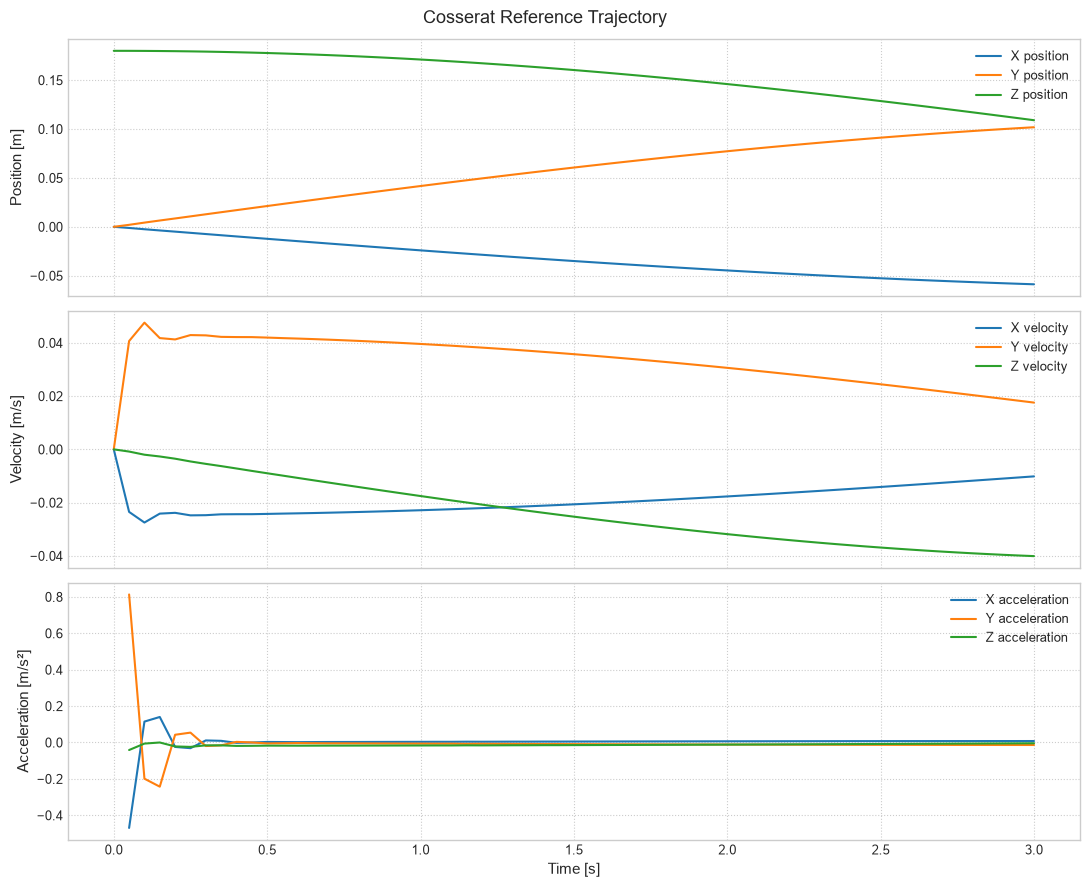

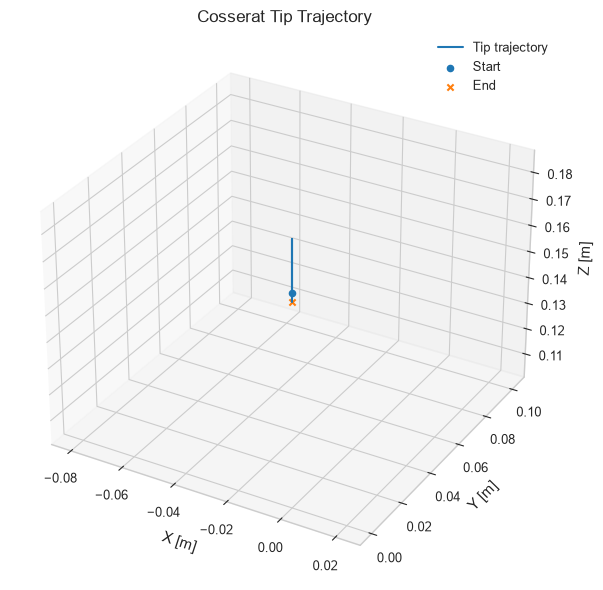

In [156]:
import numpy as np
import matplotlib.pyplot as plt

def plot_cosserat_reference(result, title="Cosserat Reference Trajectory"):
    t = result["time"]; p = result["tip"]; v = result["tip_velocity"]; a = result["tip_acceleration"]
    fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True); labels = ["X", "Y", "Z"]

    for i in range(3):
        ax[0].plot(t, p[:, i], label=f"{labels[i]} position")
        ax[1].plot(t, v[:, i], label=f"{labels[i]} velocity")
        ax[2].plot(t, a[:, i], label=f"{labels[i]} acceleration")
    ax[0].set_ylabel("Position [m]");ax[1].set_ylabel("Velocity [m/s]"); ax[2].set_ylabel("Acceleration [m/s²]"); ax[2].set_xlabel("Time [s]")

    for a_plot in ax: a_plot.grid(True, linestyle=":"); a_plot.legend()
    fig.suptitle(title)
    plt.tight_layout()
    # 3D tip trajectory
    fig = plt.figure(figsize=(8, 6))
    ax3 = fig.add_subplot(111, projection="3d"); ax3.plot(p[:, 0], p[:, 1], p[:, 2], label="Tip trajectory"); ax3.scatter(*p[0], marker="o", label="Start"); ax3.scatter(*p[-1], marker="x", label="End")
    ax3.set_xlabel("X [m]"); ax3.set_ylabel("Y [m]"); ax3.set_zlabel("Z [m]"); ax3.set_title("Cosserat Tip Trajectory"); ax3.legend(); plt.axis('equal'); plt.tight_layout(); plt.show()

plot_cosserat_reference(kirchhoff_results[2]["distributed"])

In [157]:
# ============================================================
# COSSERAT — INDEPENDENT SOLVER BLOCK
# ============================================================
for case_id in selected_cases:
    tension_func = load_cases[case_id]

    # Case-local tendon objects
    c_tendons = [
        Tendon.make_straight_tendon(tendon_radius, A1, tension_func[0], "Tendon 1"),
        Tendon.make_straight_tendon(tendon_radius, A2, tension_func[1], "Tendon 2"),
        Tendon.make_straight_tendon(tendon_radius, A3, tension_func[2], "Tendon 3"),
    ]

    # Fresh Cosserat model + solver for THIS case
    c_rod = DynamicCosserat_Kirchhoff(
        L=L, E=E, G=G, radius=radius, density=density, crt=True,
        base_position=base_position, base_rotation=base_rotation
    )

    c_solver = DynamicCosseratSolver(
        rod=c_rod,
        tendons=c_tendons,
        dt=dt,
        gravity=gravity2,
        tip_force=tip_ext_force,
        tip_moment=np.zeros(3),
        rtol=1e-6,
        atol=1e-6,
        max_step=ds,
    )

    # Preserve the original Cosserat point-moment and distributed-load runs
    c_pm = c_solver.simulate(
        time_array=time_array,
        num_points=N,
        print_progress=False,
        dt=False,
        g=not(g),
        pm=True,
    )

    c_dist = c_solver.simulate(
        time_array=time_array,
        num_points=N,
        print_progress=False,
        dt=True,
        g=not(g),
        pm=False,
    )

    cosserat_results[case_id] = {
        "name": case_names[case_id],
        "point_moment": c_pm,
        "distributed": c_dist,
        "tendons": c_tendons,
    }

print("Cosserat cases completed:", list(cosserat_results))

Cosserat cases completed: [1, 2, 3]


In [158]:
"""
MuJoCo (OpenCR) block: robust multi-case runner + validation against the rod solvers.

What was wrong in the notebook loop
-----------------------------------
    model, data = OCRM.load_model(xml)            # ONE MjData ...
    for case in cases:  ... forward_dynamics_interactive(model, data, viewer, ...)   # ... reused by every case
`forward_dynamics_interactive` runs `while data.time < t_final`.  After case 1, data.time == t_final, so
cases 2..12 returned EMPTY arrays (nothing to plot), and every case also started from the previous
case's final deflected shape.  In addition a viewer window was opened per case and synced after every
0.5 ms step (very slow).

Fix: a FRESH MjData per case (state = undeformed, t = 0), no viewer in the batch loop, a sample at t = 0
(like the other solvers), the same output dict as forward_dynamics_interactive, tensions clipped to
[0, maximum] and applied as ctrl = -tension.  An optional viewer replay of ONE case is provided.
"""
from __future__ import annotations
import contextlib
import io
import numpy as np
import mujoco
from scipy.optimize import lsq_linear

def _link_ids(model):
    import mujoco
    ids = []
    for i in range(model.nbody):
        nm = mujoco.mj_id2name(model, mujoco.mjtObj.mjOBJ_BODY, i)
        if nm and nm.startswith("link_"):
            ids.append((int(nm.split("_")[1]), i))
    return [i for _, i in sorted(ids)]


def run_mujoco_case(model, tension_funcs, t_final, save_dt=0.005, maximum=100.0, data=None):
    """One load case from rest. `model` is shared (read-only); a new MjData is created unless given."""
    import mujoco
    import OpenCR_mujoco as OCRM
    data = mujoco.MjData(model) if data is None else data
    mujoco.mj_resetData(model, data)
    mujoco.mj_forward(model, data)
    save_every = max(1, int(round(save_dt / model.opt.timestep)))
    ee_site = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_SITE, "force_site_tip")
    ee_body = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "EE_pos")
    links = _link_ids(model)
    act_ids = OCRM.get_actuator_ids(model)
    funcs = list(tension_funcs)
    tension = np.zeros(model.nu)
    keys = ("time", "tip", "tendon_length", "tension", "qpos", "qvel", "qacc", "joint_angles", "joint_torques", "states")
    H = {k: [] for k in keys}

    def record():
        if ee_site != -1: tip = data.site_xpos[ee_site].copy()
        elif ee_body != -1: tip = data.xpos[ee_body].copy()
        else: tip = data.xpos[links[-1]].copy()
        H["time"].append(data.time); H["tip"].append(tip); H["tension"].append(tension.copy())
        H["tendon_length"].append(OCRM.tendon_lengths(model, data))
        H["joint_angles"].append(OCRM.extract_joint_angles(model, data))
        H["qpos"].append(data.qpos.copy()); H["qvel"].append(data.qvel.copy()); H["qacc"].append(data.qacc.copy())
        H["joint_torques"].append(data.qfrc_actuator.copy())
        H["states"].append(np.array([data.xpos[b].copy() for b in links] + [tip]))

    nsteps = int(round(t_final / model.opt.timestep))
    record()
    for step in range(nsteps):
        t = data.time
        for idx in range(min(len(funcs), model.nu)):
            tension[idx] = np.clip(float(funcs[idx](t)), 0.0, maximum)
        for idx, act in enumerate(act_ids):
            data.ctrl[act] = -tension[idx]
        mujoco.mj_step(model, data)
        if (step + 1) % save_every == 0:
            record()
    out = {k: np.asarray(v) for k, v in H.items()}
    out["s"] = np.linspace(0.0, 1.0, out["states"].shape[1])      # placeholder grid (links + tip)
    return out


def run_mujoco_cases(xml_path, load_cases, cases, t_final, save_dt=0.005, maximum=100.0,
                     gravity=None, regenerate_from_config=None, verbose=True):
    """Run every case independently. Returns {case_id: result_dict}.
    regenerate_from_config: pass your `config` dict to rewrite the XML from the CURRENT parameters first
    (so the XML can never be stale w.r.t. L, E, radius, N ...)."""
    import io, contextlib
    import OpenCR_mujoco as OCRM
    if regenerate_from_config is not None:
        with contextlib.redirect_stdout(io.StringIO()):
            OCRM.generate_tdcr_xml_from_config(regenerate_from_config, output_filename=str(xml_path))
    model, _ = OCRM.load_model(xml_path)
    if gravity is not None:
        model.opt.gravity[:] = np.asarray(gravity, float)
    out = {}
    for cid in cases:
        out[cid] = run_mujoco_case(model, load_cases[cid], t_final, save_dt, maximum)
        if verbose:
            r = out[cid]; tip = r["tip"]
            print(f"  MuJoCo case {cid}: {len(r['time'])} samples, t = [{r['time'][0]:.3f}, {r['time'][-1]:.3f}] s, "
                  f"max tip reach from base = {np.linalg.norm(tip - tip[0], axis=1).max():.4f} m")
    return out


def replay_in_viewer(xml_path, tension_funcs, t_final, maximum=100.0):
    """Interactive window for ONE case (fresh data). Not used in the batch loop."""
    import mujoco, mujoco.viewer
    import OpenCR_mujoco as OCRM
    model, data = OCRM.load_model(xml_path)
    ctrl = OCRM.FlexibleTendonController(num_actuators=model.nu, step=0.2, maximum=maximum, tension_funcs=list(tension_funcs))
    with mujoco.viewer.launch_passive(model, data, key_callback=ctrl.key_callback) as v:
        return OCRM.forward_dynamics_interactive(model, data, v, ctrl, OCRM.get_actuator_ids(model), t_final=t_final)


def check_results(mujoco_results, t_final, save_dt=0.005):
    """Fail loudly instead of silently plotting empty / NaN data."""
    bad = []
    for cid, r in mujoco_results.items():
        n_exp = int(round(t_final / save_dt)) + 1
        if len(r["time"]) < 0.9 * n_exp or not np.all(np.isfinite(r["tip"])):
            bad.append((cid, len(r["time"]), n_exp))
    if bad:
        raise RuntimeError(f"MuJoCo results incomplete (case, samples, expected): {bad}")
    print("MuJoCo results OK:", list(mujoco_results))


def tip_error_table(results_by_case, ref_key, L, keys=None, verbose=True):
    """results_by_case = {cid: {label: result_dict}}.  Tip RMS / final / max error as % of L vs ref_key
    (all solvers are interpolated to the reference time grid)."""
    table = {}
    for cid, d in results_by_case.items():
        if ref_key not in d: continue
        tr = np.asarray(d[ref_key]["time"]); pr = np.asarray(d[ref_key]["states"])[:, -1, :3]
        table[cid] = {}
        for k, r in d.items():
            if k == ref_key or (keys and k not in keys): continue
            t = np.asarray(r["time"]); p = np.asarray(r["states"])[:, -1, :3]
            m = tr <= t[-1] + 1e-9
            pi = np.column_stack([np.interp(tr[m], t, p[:, i]) for i in range(3)])
            e = np.linalg.norm(pi - pr[m], axis=1) / L * 100
            table[cid][k] = {"rms": float(np.sqrt(np.mean(e ** 2))), "final": float(e[-1]), "max": float(e.max()),
                             "truncated": bool(t[-1] < tr[-1] - 1e-6)}
    if verbose and table:
        labs = sorted({k for v in table.values() for k in v})
        print(f"tip RMS error vs {ref_key} [% L]   (* = result truncated)")
        print(f"{'case':>5} " + " ".join(f"{l:>10}" for l in labs))
        for cid, v in table.items():
            print(f"{cid:>5} " + " ".join(f"{v[l]['rms']:>9.2f}{'*' if v[l]['truncated'] else ' '}" if l in v else f"{'-':>10}" for l in labs))
        print(f"{'mean':>5} " + " ".join(f"{np.mean([v[l]['rms'] for v in table.values() if l in v]):>10.2f}" for l in labs))
    return table

# ---------------------------------------------------------------------------
# 2. MuJoCo Helpers
# ---------------------------------------------------------------------------
"""Unified OpenCR-MuJoCo TDCR forward/inverse validation tools."""
# ---------------------------------------------------------------------
# Model utilities
# ---------------------------------------------------------------------
def load_tdcr_model(xml_path, timestep=None, gravity=None):
    """Load through OpenCR_mujoco so the project's model setup is retained."""
    import OpenCR_mujoco as OCRM
    model, data = OCRM.load_model(xml_path)
    if timestep is not None:
        model.opt.timestep = float(timestep)
    if gravity is not None:
        model.opt.gravity[:] = np.asarray(gravity, dtype=float)
    mujoco.mj_resetData(model, data)
    mujoco.mj_forward(model, data)
    return model, data


def get_link_body_ids(model):
    """Return link body IDs in numerical link_0, link_1, ... order."""
    links = []
    for body_id in range(model.nbody):
        name = mujoco.mj_id2name(model, mujoco.mjtObj.mjOBJ_BODY, body_id)
        if name and name.startswith("link_"):
            try:
                links.append((int(name.split("_")[1]), body_id))
            except (ValueError, IndexError):
                pass
    return [body_id for _, body_id in sorted(links)]


def get_tip_site_id(model, site_name="force_site_tip"):
    site_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_SITE, site_name)
    if site_id < 0:
        raise ValueError(f"Tip site '{site_name}' was not found in the XML.")
    return site_id


def get_actuator_ids(model):
    return list(range(model.nu))


def apply_tensions(model, data, tensions, maximum=np.inf):
    """Apply positive physical tensions using this XML's ctrl = -tension convention."""
    tensions = np.asarray(tensions, dtype=float).reshape(-1)
    if tensions.size != model.nu:
        raise ValueError(f"Expected {model.nu} tensions, received {tensions.size}.")
    tensions = np.clip(tensions, 0.0, maximum)
    data.ctrl[:] = -tensions
    return tensions


def get_tendon_lengths(model, data):
    return np.asarray(data.ten_length[:model.ntendon], dtype=float).copy()


def get_joint_angles(model, data):
    """For the current hinge-joint XML, each joint has one qpos angle."""
    angles = np.zeros(model.njnt)
    for j in range(model.njnt):
        angles[j] = data.qpos[model.jnt_qposadr[j]]
    return angles


# ---------------------------------------------------------------------
# MuJoCo dynamics extraction
# ---------------------------------------------------------------------
def extract_dynamics_matrices(model, data, positive_tension=True):
    """
    Extract M, h, passive forces and actuator transmission at current qpos/qvel.

    B_T[:,j] is the generalized force produced by +1 N tension in actuator j.
    The project's motor convention is ctrl = -tension.
    """
    mujoco.mj_forward(model, data)
    nv, nu = model.nv, model.nu
    M = np.zeros((nv, nv))
    mujoco.mj_fullM(model, M, data.qM)
    h_bias = data.qfrc_bias.copy()
    tau_passive = data.qfrc_passive.copy()
    tau_actuator = data.qfrc_actuator.copy()

    ctrl_saved = data.ctrl.copy()
    data.ctrl[:] = 0.0
    mujoco.mj_forward(model, data)
    tau_zero = data.qfrc_actuator.copy()
    B_T = np.zeros((nv, nu))
    for j in range(nu):
        data.ctrl[:] = 0.0

In [159]:
# Ensure XML is up-to-date with current parameters before running
regenerate_config = config.copy()

# Run MuJoCo simulation cases independently using fresh MjData per case
mujoco_results = run_mujoco_cases(
    xml_path=XML_PATH,
    load_cases=load_cases,
    cases=selected_cases,
    t_final=t_final,
    save_dt=dt,
    maximum=100.0,
    gravity=gravity2,
    regenerate_from_config=regenerate_config,
    verbose=True
)

# Validate results to catch empty arrays or NaNs early
check_results(mujoco_results, t_final, save_dt=dt)

# Store into your global results dictionary for downstream validation tables and plots
all_case_results["mujoco"] = mujoco_results

print("MuJoCo cases completed:", list(mujoco_results))


  MuJoCo case 1: 61 samples, t = [0.000, 3.000] s, max tip reach from base = 0.1358 m
  MuJoCo case 2: 61 samples, t = [0.000, 3.000] s, max tip reach from base = 0.1358 m
  MuJoCo case 3: 61 samples, t = [0.000, 3.000] s, max tip reach from base = 0.1358 m
MuJoCo results OK: [1, 2, 3]
MuJoCo cases completed: [1, 2, 3]


In [160]:
"""
hinge_identification.py -- pooled, data-driven PRBM hinge location from Cosserat / Kirchhoff data
================================================================================================

PRBM geometry (identical to PRBM.PRBM2R):
    * the rod is straight and fixed along +z from the base up to the hinge  H = (0, 0, s_h)
    * from the hinge a RIGID straight link of length  L_rot = L - s_h  rotates freely
      (2 bending DOF);  tip = H + L_rot * d,   |d| = 1

Consequence (the only thing the PRBM can do kinematically): the tip lies on a SPHERE of radius
L - s_h centred on the hinge.  The rod data tell us where the tips really are, so the hinge is the
point for which that sphere fits ALL tips best:

    r_f(s_h) = || p_tip,f - (0,0,s_h) ||  -  (L - s_h)                      (radial residual, m)
    J(s_h)   = (1/F) sum_f r_f(s_h)^2                                        (pooled over ALL frames)

F = every saved time frame of every load case of every model (Kirchhoff/Cosserat x point-moment/
distributed) that is actually bent.  One scalar optimisation, one answer -- no per-case fits.

Closed form per frame (diagnostic):  r_f = 0  <=>  s_h = (L^2 - |p|^2) / (2 (L - z)).
The pooled optimum is therefore a compromise between these per-frame "exact" hinge positions.

Secondary (shape) objective, evaluated with the SAME PRBM state:
    J_shape(s_h) = mean over frames & nodes of || p_i - p_i^PRBM ||^2
where p_i^PRBM = (0,0,s_i) for s_i <= s_h and H + (s_i - s_h) d_f otherwise, d_f = (p_tip - H)/|p_tip - H|.
"""
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Dict, Tuple

import numpy as np
from scipy.optimize import minimize_scalar


# ----------------------------------------------------------------------------------------------
# 1. Pool the data
# ----------------------------------------------------------------------------------------------

@dataclass
class HingeData:
    L: float
    s: np.ndarray
    P: np.ndarray
    model: np.ndarray
    case: np.ndarray
    time: np.ndarray
    n_total: int = 0
    base_position: np.ndarray = field(default_factory=lambda: np.zeros(3))
    base_rotation: np.ndarray = field(default_factory=lambda: np.eye(3))

    @property
    def tips(self):
        return self.P[:, -1, :]

    @property
    def n_frames(self):
        return self.P.shape[0]


def collect_frames(model_sources: Dict[str, Tuple[dict, str]], L: float, cases=None,
                   min_lateral_frac: float = 0.01, base_position=None,
                   base_rotation=None, input_frame="world") -> HingeData:
    """Collect frames and store all backbone points in the common base frame."""
    if input_frame not in ("world", "base"):
        raise ValueError("input_frame must be 'world' or 'base'.")
    pb = np.zeros(3) if base_position is None else np.asarray(base_position, float).reshape(3)
    Rb = np.eye(3) if base_rotation is None else np.asarray(base_rotation, float).reshape(3, 3)
    if not np.allclose(Rb.T @ Rb, np.eye(3), atol=1e-8) or not np.isclose(np.linalg.det(Rb), 1.0, atol=1e-8):
        raise ValueError("base_rotation must be a proper rotation matrix in SO(3).")

    P_l, m_l, c_l, t_l, s_ref, total = [], [], [], [], None, 0
    for name, (store, key) in model_sources.items():
        for cid in (cases if cases is not None else store):
            if cid not in store:
                continue
            res = store[cid][key]
            st = np.asarray(res["states"], float)[:, :, 0:3]
            s = np.asarray(res["s"], float)
            if s_ref is None:
                s_ref = s
            elif len(s) != len(s_ref) or not np.allclose(s, s_ref):
                raise ValueError("all pooled results must share the same spatial grid")

            total += st.shape[0]
            if input_frame == "world":
                # Row-vector inverse rigid transform: p_base = (p_world - p_base_origin) @ R_base.
                st = (st - pb) @ Rb

            # Filter using the tip's lateral displacement in the local base frame.
            lat = np.hypot(st[:, -1, 0] - st[:, 0, 0],
                           st[:, -1, 1] - st[:, 0, 1])
            keep = lat > min_lateral_frac * L
            P_l.append(st[keep])
            m_l.extend([name] * int(keep.sum()))
            c_l.extend([cid] * int(keep.sum()))
            t_l.append(np.asarray(res["time"], float)[keep])

    if not P_l or not any(len(p) for p in P_l):
        raise ValueError("No bent frames collected; check input_frame, base pose, and filter threshold.")

    return HingeData(
        L=L, s=s_ref, P=np.concatenate(P_l), model=np.array(m_l),
        case=np.array(c_l), time=np.concatenate(t_l), n_total=total,
        base_position=pb, base_rotation=Rb
    )


def prbm_points_world(s, s_h, d, L, base_position=None, base_rotation=None):
    """Generate PRBM points in world coordinates from base-frame link directions."""
    P_base = prbm_points(s, s_h, d, L)
    pb = np.zeros(3) if base_position is None else np.asarray(base_position, float).reshape(3)
    Rb = np.eye(3) if base_rotation is None else np.asarray(base_rotation, float).reshape(3, 3)
    return pb + P_base @ Rb.T



# ----------------------------------------------------------------------------------------------
# 2. Objectives (vectorised: s_h may be a scalar or an array)
# ----------------------------------------------------------------------------------------------
def radial_residual(tips, s_h, L):
    """r_f(s_h) = |tip - (0,0,s_h)| - (L - s_h).  tips (F,3); s_h scalar -> (F,), array (K,) -> (K,F)."""
    s_h = np.asarray(s_h, float)
    rho2 = tips[:, 0] ** 2 + tips[:, 1] ** 2
    dz = tips[:, 2][None, :] - np.atleast_1d(s_h)[:, None]
    r = np.sqrt(rho2[None, :] + dz ** 2) - (L - np.atleast_1d(s_h))[:, None]
    return r[0] if s_h.ndim == 0 else r


def tip_objective(s_h, data: HingeData):
    r = radial_residual(data.tips, s_h, data.L)
    return np.mean(r ** 2, axis=-1)


def per_frame_exact_hinge(data: HingeData):
    """s_h that makes the PRBM sphere pass exactly through each tip (closed form)."""
    p = data.tips
    return (data.L ** 2 - np.sum(p ** 2, axis=1)) / (2.0 * (data.L - p[:, 2]))


def prbm_direction(tips, s_h):
    """Unit link direction d_f from the hinge to each tip. (F,3)"""
    v = tips - np.array([0.0, 0.0, s_h])
    return v / np.linalg.norm(v, axis=1, keepdims=True)


def prbm_points(s, s_h, d, L):
    """PRBM backbone nodes for link directions d (F,3) -> (F,N,3)."""
    s = np.asarray(s)[None, :, None]
    H = np.array([0.0, 0.0, s_h])
    fixed = np.broadcast_to(np.array([0.0, 0.0, 1.0]) * s, (d.shape[0], s.shape[1], 3))
    link = H + np.clip(s - s_h, 0.0, None) * d[:, None, :]
    return np.where(s <= s_h, fixed, link)


def shape_objective(s_h, data: HingeData):
    s_h = np.atleast_1d(np.asarray(s_h, float))
    out = np.empty(len(s_h))
    for k, h in enumerate(s_h):
        d = prbm_direction(data.tips, h)
        out[k] = np.mean(np.sum((data.P - prbm_points(data.s, h, d, data.L)) ** 2, axis=2))
    return out


# ----------------------------------------------------------------------------------------------
# 3. Optimisation
# ----------------------------------------------------------------------------------------------
@dataclass
class HingeResult:
    s_h: float
    J: float
    bounds: Tuple[float, float]
    grid: np.ndarray
    J_grid: np.ndarray
    active_bound: bool
    rms_tip_err: float            # m
    max_tip_err: float            # m
    n_frames: int
    L: float
    extras: dict = field(default_factory=dict)

    @property
    def fraction(self):
        return self.s_h / self.L

    def summary(self):
        return (f"s_h* = {self.s_h*1e3:.2f} mm = {self.fraction:.4f} L   "
                f"(L_rot = {(self.L-self.s_h)*1e3:.2f} mm)   RMS tip error = {100*self.rms_tip_err/self.L:.2f} % L, "
                f"max = {100*self.max_tip_err/self.L:.2f} % L   [{self.n_frames} frames]"
                f"{'   ** AT BOUND **' if self.active_bound else ''}")


def identify_hinge(data: HingeData, objective="tip", bounds=None, n_grid=1500) -> HingeResult:
    """Global 1-D minimisation: dense grid (guards against local minima) + bounded Brent refinement."""
    L = data.L
    lo, hi = bounds if bounds is not None else (0.01 * L, 0.95 * L)
    f = (lambda x: float(tip_objective(x, data))) if objective == "tip" else (lambda x: float(shape_objective(x, data)[0]))
    grid = np.linspace(lo, hi, n_grid)
    Jg = tip_objective(grid, data) if objective == "tip" else shape_objective(grid, data)
    i = int(np.argmin(Jg))
    a, b = grid[max(i - 1, 0)], grid[min(i + 1, n_grid - 1)]
    opt = minimize_scalar(f, bounds=(a, b), method="bounded", options={"xatol": 1e-10})
    sh = float(opt.x) if opt.fun <= Jg[i] else float(grid[i])
    r = radial_residual(data.tips, sh, L)
    tol = 2.0 * (hi - lo) / n_grid
    return HingeResult(s_h=sh, J=f(sh), bounds=(lo, hi), grid=grid, J_grid=Jg,
                       active_bound=bool(sh <= lo + tol or sh >= hi - tol),
                       rms_tip_err=float(np.sqrt(np.mean(r ** 2))), max_tip_err=float(np.max(np.abs(r))),
                       n_frames=data.n_frames, L=L)


def tip_error_at(data: HingeData, s_h):
    """Radial tip error statistics for a chosen hinge (m)."""
    r = radial_residual(data.tips, s_h, data.L)
    return {"rms": float(np.sqrt(np.mean(r ** 2))), "max": float(np.max(np.abs(r))),
            "mean_signed": float(np.mean(r))}


def bootstrap_over_cases(data: HingeData, n_boot=2000, bounds=None, seed=0, n_grid=1500):
    """Uncertainty of the POOLED optimum: resample whole load cases (with replacement).
    J_total(s) = sum_c N_c J_c(s) is precomputed per case, so this is cheap and is not a per-case fit."""
    L = data.L
    lo, hi = bounds if bounds is not None else (0.01 * L, 0.95 * L)
    grid = np.linspace(lo, hi, n_grid)
    cases = np.unique(data.case)
    S = np.zeros((len(cases), n_grid)); n = np.zeros(len(cases))
    for k, c in enumerate(cases):
        m = data.case == c
        S[k] = np.sum(radial_residual(data.tips[m], grid, L) ** 2, axis=1)
        n[k] = m.sum()
    rng = np.random.default_rng(seed)
    out = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, len(cases), len(cases))
        out[b] = grid[np.argmin(S[idx].sum(0) / n[idx].sum())]
    return out


# ----------------------------------------------------------------------------------------------
# 4. The objective of the previous notebook cell ("Case B") -- kept ONLY for the diagnosis
# ----------------------------------------------------------------------------------------------
def old_case_b_objective(P, s, s_h):
    """J = || 2 X(s_h) - [0, s_h] ||^2 for one frame (planar projection as in the old cell)."""
    tr = P[-1, :2] - P[0, :2]
    nrm = np.linalg.norm(tr)
    dvec = tr / nrm if nrm > 1e-12 else np.array([1.0, 0.0])
    x = (P[:, :2] - P[0, :2]) @ dvec
    z = P[:, 2] - P[0, 2]
    xh, zh = np.interp(s_h, s, x), np.interp(s_h, s, z)
    r = 2.0 * np.array([xh, zh]) - np.array([0.0, s_h])
    return float(r @ r)


"""Robust plots for pooled PRBM hinge identification."""
from __future__ import annotations
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import hinge_identification as H

# Fixed palette: Kirchhoff = blue, Cosserat = orange.
C_K, C_C = "#2a78d6", "#eb6834"
C_OPT, C_REF = "#6250d6", "#8a8984"
INK, INK2, SURF = "#0b0b0b", "#52514e", "#fcfcfb"


def _style(ax):
    ax.set_facecolor(SURF)
    ax.grid(True, color="#e3e2de", lw=0.6)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    for sp in ("left", "bottom"):
        ax.spines[sp].set_color("#c9c8c2")
    ax.tick_params(colors=INK2, labelsize=9)
    ax.xaxis.label.set_color(INK2)
    ax.yaxis.label.set_color(INK2)
    ax.title.set_color(INK)


def _fig(*args, **kwargs):
    fig, ax = plt.subplots(*args, **kwargs)
    fig.patch.set_facecolor(SURF)
    for a in np.atleast_1d(ax).ravel():
        _style(a)
    return fig, ax


def _family(model):
    """Map model names to K (Kirchhoff) or C (Cosserat)."""
    model = np.asarray(model).astype(str)
    return np.where(np.char.startswith(model, "Kirchhoff"), "K", "C")


def _valid_frames(data):
    """Frame indices with finite centerline and tip coordinates."""
    P = np.asarray(data.P, dtype=float)
    if P.ndim != 3 or P.shape[0] == 0 or P.shape[1] == 0 or P.shape[2] < 3:
        return np.array([], dtype=int)
    return np.flatnonzero(np.isfinite(P[:, :, :3]).all(axis=(1, 2)))


def _representative_indices(data, preferred=("Cosserat_dist",)):
    """Prefer a requested model; fall back to any valid pooled model."""
    valid = _valid_frames(data)
    if valid.size == 0:
        return valid
    model = np.asarray(data.model).astype(str)
    for name in preferred:
        idx = valid[model[valid] == name]
        if idx.size:
            return idx
    print(f"Warning: none of {preferred} are available; using all valid pooled frames.")
    return valid


def _planar(P):
    """Rotate frame(s) around z so the tip lies in the x-z plane."""
    P = np.asarray(P, dtype=float)
    ang = np.arctan2(P[..., -1, 1], P[..., -1, 0])
    c, s = np.cos(-ang)[..., None], np.sin(-ang)[..., None]
    x = c * P[..., 0] - s * P[..., 1]
    y = s * P[..., 0] + c * P[..., 1]
    return x, P[..., 2], np.abs(y)


def _prbm_xz(sh, tip, L, n=60):
    """PRBM centerline in the bending plane for a specified tip."""
    tip = np.asarray(tip, dtype=float).reshape(3)
    d = H.prbm_direction(tip[None, :], sh)
    r = H.prbm_points(np.linspace(0, L, n), sh, d, L)[0]
    ang = np.arctan2(tip[1], tip[0])
    x = np.cos(-ang) * r[:, 0] - np.sin(-ang) * r[:, 1]
    return x, r[:, 2]


def plot_objectives(data, res, res_shape=None, old_frames=None, old_s=None, save=None):
    """Compare previous and pooled hinge objectives."""
    L = data.L
    fig, (a, b) = _fig(1, 2, figsize=(12, 4.3))
    lo = L / 6 + 1e-3 * L
    sh_grid = np.linspace(lo, L * (1 - 1e-3), 300)

    if old_frames is not None and old_s is not None:
        for k, P in enumerate(old_frames):
            J = np.array([H.old_case_b_objective(P, old_s, s) for s in sh_grid])
            jmax = np.nanmax(J) if J.size else 0.0
            if jmax > 0 and np.isfinite(jmax):
                a.plot(sh_grid * 1e3, J / jmax, lw=1.3, color=C_REF,
                       alpha=0.9, label="Previous Case-B objective" if k == 0 else None)

    a.scatter([lo * 1e3], [0], s=60, color=C_OPT, zorder=5,
              label=f"Lower bound = {lo*1e3:.1f} mm")
    a.axvline(L / 6 * 1e3, color=C_REF, ls=":", lw=1)
    a.set_xlabel("Candidate hinge $s_h$ [mm]")
    a.set_ylabel("$J/J_{max}$")
    a.set_title("Previous objective", fontsize=10.5, loc="left")
    a.legend(frameon=False, fontsize=8.5, loc="best")

    g = np.asarray(res.grid)
    rms = 100 * np.sqrt(np.maximum(np.asarray(res.J_grid), 0)) / L
    b.plot(g * 1e3, rms, color=C_OPT, lw=2, label="Pooled tip-reach objective")
    if res_shape is not None:
        b.plot(res_shape.grid * 1e3,
               100 * np.sqrt(np.maximum(res_shape.J_grid, 0)) / L,
               color=INK2, lw=1.4, ls="--", label="Pooled shape objective")
        b.scatter([res_shape.s_h * 1e3],
                  [100 * np.sqrt(max(res_shape.J, 0)) / L],
                  s=36, color=INK2, zorder=5)

    b.scatter([res.s_h * 1e3],
              [100 * np.sqrt(max(res.J, 0)) / L],
              s=70, color=C_OPT, zorder=6, edgecolor=SURF, lw=1.5)
    b.axvline(L / 6 * 1e3, color=C_REF, ls=":", lw=1.2)
    b.annotate(f"$s_h^*$ = {res.s_h*1e3:.1f} mm ({res.fraction:.3f} L)",
               (res.s_h * 1e3, 100 * np.sqrt(max(res.J, 0)) / L),
               xytext=(12, 30), textcoords="offset points", fontsize=9,
               color=INK, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
    b.set_xlabel("Candidate hinge $s_h$ [mm]")
    b.set_ylabel("RMS error [% of L]")
    b.set_title(f"Pooled objective ({res.n_frames} frames)", fontsize=10.5, loc="left")
    b.legend(frameon=False, fontsize=8.5, loc="best")
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=170, facecolor=SURF)
    return fig


def plot_prbm_setup(data, res, boot=None, save=None):
    """PRBM reach circles and representative pooled centerlines."""
    L, sh = float(data.L), float(res.s_h)
    x, z, _ = _planar(data.P)
    model = np.asarray(data.model).astype(str)
    fam = _family(model)
    tip_x, tip_z = x[:, -1], z[:, -1]

    fig, ax = _fig(figsize=(7.4, 7.9))
    finite_tips = np.isfinite(tip_x) & np.isfinite(tip_z)
    for family, color, label in (("K", C_K, "Kirchhoff"), ("C", C_C, "Cosserat")):
        mask = finite_tips & (fam == family)
        if np.any(mask):
            ax.scatter(tip_x[mask], tip_z[mask], s=7, color=color, alpha=0.35,
                       lw=0, label=f"Tips: {label}")

    th = np.linspace(-np.pi / 2 - 0.25, np.pi / 2 + 0.25, 400)
    ax.plot((L-sh)*np.sin(th), sh+(L-sh)*np.cos(th), color=C_OPT, lw=1.8,
            label=f"PRBM reach circle, $s_h^*$={sh*1e3:.1f} mm")
    r6 = 5 * L / 6
    ax.plot(r6*np.sin(th), L/6+r6*np.cos(th), color=C_REF, lw=1.4, ls=":",
            label="PRBM reach circle, $s_h=L/6")

    # Select valid frames from Cosserat distributed data; safely fall back if absent.
    m = _representative_indices(data, ("Cosserat_dist",))
    if m.size:
        lat = tip_x[m]
        valid = np.isfinite(lat)
        m, lat = m[valid], lat[valid]
    if m.size:
        for lvl in (0.18, 0.35, 0.50, 0.65):
            # The non-empty guard prevents argmin on an empty array.
            k = m[np.argmin(np.abs(lat / L - lvl))]
            ax.plot(x[k], z[k], color=C_C, lw=2.2, solid_capstyle="round")
            px, pz = _prbm_xz(sh, data.P[k, -1, :3], L)
            ax.plot(px, pz, color=C_OPT, lw=1.3, ls="--")
            ax.scatter([px[-1]], [pz[-1]], s=22, color=C_OPT, zorder=6)
    else:
        print("Warning: no valid frames; skipping representative setup overlays.")

    ax.plot([0, 0], [0, sh], color=INK, lw=3.4, solid_capstyle="round",
            label="PRBM fixed section")
    ax.scatter([0], [sh], s=130, color=SURF, edgecolor=INK, lw=2.2,
               zorder=8, label="Hinge")
    ax.annotate(f"hinge\n$s_h$ = {sh*1e3:.1f} mm", (0, sh),
                xytext=(-78, 6), textcoords="offset points", fontsize=9.5, color=INK)
    ax.scatter([0], [0], marker="s", s=60, color=INK, zorder=7)
    ax.annotate("Clamped base", (0, 0), xytext=(8, -14),
                textcoords="offset points", fontsize=8.5, color=INK2)

    below = 100 * np.mean(data.tips[:, 2] < sh) if len(data.tips) else np.nan
    ax.text(0.98, 0.98, f"{below:.0f}% of frames: tip below hinge",
            transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK2)
    ax.set_aspect("equal")
    ax.set_xlabel("Lateral position in bending plane [m]")
    ax.set_ylabel("Axial position z [m]")
    ax.set_title("Identified PRBM hinge vs. rod data", fontsize=11, loc="left")
    ax.legend(frameon=False, fontsize=8, loc="upper center",
              bbox_to_anchor=(0.5, -0.12), ncol=2)
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=170, facecolor=SURF)
    return fig


def plot_per_frame_hinge(data, res, boot=None, save=None):
    """Per-frame exact hinge versus tip bending angle."""
    L = data.L
    ex = H.per_frame_exact_hinge(data)
    tipx = np.hypot(data.tips[:, 0], data.tips[:, 1])
    ang = np.degrees(np.arctan2(tipx, data.tips[:, 2] - res.s_h))
    fam = _family(data.model)
    valid = np.isfinite(ex) & np.isfinite(ang)

    fig, ax = _fig(figsize=(8.4, 4.6))
    for f, color, label in (("K", C_K, "Kirchhoff"), ("C", C_C, "Cosserat")):
        mask = valid & (fam == f)
        if np.any(mask):
            ax.scatter(ang[mask], ex[mask]*1e3, s=7, color=color, alpha=0.35,
                       lw=0, label=label)
    if boot is not None and len(boot):
        lo, hi = np.percentile(boot, [2.5, 97.5])
        ax.axhspan(lo*1e3, hi*1e3, color=C_OPT, alpha=0.18, lw=0)
    ax.axhline(res.s_h*1e3, color=C_OPT, lw=2,
               label=f"Pooled optimum {res.s_h*1e3:.1f} mm")
    ax.axhline(L/6*1e3, color=C_REF, lw=1.4, ls=":", label="L/6")
    ax.set_xlabel("Tip bending angle seen from hinge [deg]")
    ax.set_ylabel("Exact per-frame hinge [mm]")
    ax.set_title("Per-frame hinge estimates", fontsize=11, loc="left")
    ax.legend(frameon=False, fontsize=8.5, loc="best")
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=170, facecolor=SURF)
    return fig


def plot_error_distribution(data, res, save=None):
    """Pooled tip-error CDF and RMS error by model."""
    L = data.L
    fig, (a, b) = _fig(1, 2, figsize=(12, 4.2))
    for sh, color, ls, label in (
        (res.s_h, C_OPT, "-", f"$s_h^*$ = {res.s_h*1e3:.1f} mm"),
        (L/6, C_REF, "--", "L/6")
    ):
        e = np.sort(np.abs(H.radial_residual(data.tips, sh, L)))
        e = e[np.isfinite(e)] / L * 100
        if e.size:
            a.plot(e, np.arange(1, e.size+1)/e.size*100,
                   color=color, lw=2, ls=ls, label=label)
    a.set_xlabel("Tip error [% of L]")
    a.set_ylabel("Frames within error [%]")
    a.set_title("Pooled tip-error distribution", fontsize=10.5, loc="left")
    a.legend(frameon=False, fontsize=9)
    a.set_xlim(left=0, right=20)

    models = list(dict.fromkeys(np.asarray(data.model).astype(str)))
    xs, w = np.arange(len(models)), 0.38
    for off, sh, color, label in (
        (-w/2, res.s_h, C_OPT, "$s_h^*$"),
        (w/2, L/6, C_REF, "L/6")
    ):
        vals = []
        for model in models:
            e = H.radial_residual(data.tips[np.asarray(data.model).astype(str) == model], sh, L)
            vals.append(100*np.sqrt(np.nanmean(e**2)) if np.size(e) else np.nan)
        b.bar(xs+off, vals, w, color=color, label=label)
        for xx, vv in zip(xs+off, vals):
            if np.isfinite(vv):
                b.text(xx, vv+0.15, f"{vv:.1f}", ha="center", fontsize=8, color=INK2)
    b.set_xticks(xs, [m.replace("_", "\n") for m in models], fontsize=9)
    b.set_ylabel("RMS tip error [% of L]")
    b.set_title("RMS error by model", fontsize=10.5, loc="left")
    b.legend(frameon=False, ncol=2, loc="best")
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=170, facecolor=SURF)
    return fig


def plot_case_snapshots(data, res, cases=(1, 2, 6, 10, 11, 12),
                        model="Cosserat_dist", case_names=None, save=None):
    """Peak-deflection frame per case: rod versus two PRBM variants."""
    L, sh = data.L, res.s_h
    cases = list(cases)
    if not cases:
        print("No cases requested; skipping case-snapshot plot.")
        return None

    ncols = (len(cases)+1)//2
    fig, axs = _fig(2, ncols, figsize=(4*ncols, 8), sharex=True, sharey=True)
    axs = np.asarray(axs, dtype=object).reshape(2, ncols)
    model_names = np.asarray(data.model).astype(str)

    for ax, case in zip(axs.ravel(), cases):
        idx = np.where((model_names == model) & (data.case == case))[0]
        idx = np.intersect1d(idx, _valid_frames(data))
        if idx.size == 0:
            ax.set_visible(False)
            print(f"Case snapshot skipped: no valid '{model}' frames for case {case}.")
            continue
        lat = np.hypot(data.tips[idx, 0], data.tips[idx, 1])
        k = idx[np.argmax(lat)]
        x, z, _ = _planar(data.P[k])
        ax.plot(x, z, color=C_C, lw=2.4, label="Rod")
        px, pz = _prbm_xz(L/6, data.P[k, -1, :3], L)
        ax.plot(px, pz, color=C_REF, lw=1.4, ls=":", label="PRBM, L/6")
        px, pz = _prbm_xz(sh, data.P[k, -1, :3], L)
        ax.plot(px, pz, color=C_OPT, lw=1.6, ls="--", label="PRBM, identified")
        ax.scatter([0], [sh], s=60, color=SURF, edgecolor=INK, lw=1.8, zorder=6)
        ax.scatter([0], [L/6], s=40, color=SURF, edgecolor=C_REF, lw=1.4, zorder=6)
        e_opt = abs(H.radial_residual(data.tips[k:k+1], sh, L)[0])/L*100
        e_ref = abs(H.radial_residual(data.tips[k:k+1], L/6, L)[0])/L*100
        name = case_names.get(case, str(case)) if case_names else str(case)
        ax.set_title(f"Case {case}: {name}\nt={data.time[k]:.2f} s; error={e_opt:.1f}% vs {e_ref:.1f}%",
                     fontsize=8.8, loc="left")
        ax.set_aspect("equal")

    for ax in axs[:, 0]:
        ax.set_ylabel("Axial z [m]")
    for ax in axs[-1]:
        ax.set_xlabel("Lateral [m]")
    visible = [ax for ax in axs.ravel() if ax.get_visible()]
    if visible:
        visible[0].legend(frameon=False, fontsize=8, loc="best")
    fig.suptitle(f"Peak-deflection snapshots: {model.replace('_', ' ')}",
                 fontsize=11.5, x=0.01, ha="left")
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=170, facecolor=SURF)
    return fig


def plot_prbm_3d(data, res, save=None):
    """3D pooled tip cloud and representative rod/PRBM backbones."""
    L, sh = float(data.L), float(res.s_h)
    fig = plt.figure(figsize=(7.6, 7.2))
    fig.patch.set_facecolor(SURF)
    ax = fig.add_subplot(111, projection="3d")
    ax.set_facecolor(SURF)

    fam = _family(data.model)
    tips = np.asarray(data.tips, dtype=float)
    valid_tip = np.isfinite(tips[:, :3]).all(axis=1)
    for family, color, label in (("K", C_K, "Tips: Kirchhoff"), ("C", C_C, "Tips: Cosserat")):
        mask = valid_tip & (fam == family)
        if np.any(mask):
            ax.scatter(tips[mask, 0], tips[mask, 1], tips[mask, 2],
                       s=3, color=color, alpha=0.25, label=label)

    u, v = np.meshgrid(np.linspace(0, 2*np.pi, 40), np.linspace(0, np.pi*0.78, 22))
    R = L-sh
    ax.plot_wireframe(R*np.sin(v)*np.cos(u), R*np.sin(v)*np.sin(u),
                      sh+R*np.cos(v), color=C_OPT, alpha=0.16, lw=0.5)
    ax.plot([0, 0], [0, 0], [0, sh], color=INK, lw=4)
    ax.scatter([0], [0], [sh], s=90, color=SURF, edgecolor=INK, lw=2, depthshade=False)

    # Select preferred frames, with a safe fallback if Cosserat_dist is absent.
    m = _representative_indices(data, ("Cosserat_dist",))
    for lvl in (0.25, 0.45, 0.65):
        if m.size == 0:
            break
        radial = np.hypot(tips[m, 0], tips[m, 1]) / L
        good = np.isfinite(radial)
        if not np.any(good):
            continue
        candidates, radial = m[good], radial[good]
        k = candidates[np.argmin(np.abs(radial-lvl))]

        P = np.asarray(data.P[k], dtype=float)[:, :3]
        if not np.isfinite(P).all():
            continue
        ax.plot(P[:, 0], P[:, 1], P[:, 2], color=C_C, lw=2.0)

        # PRBM rigid link starts at the hinge and ends at the predicted tip.
        d = np.asarray(H.prbm_direction(tips[k:k+1, :3], sh))[0]
        hinge = np.array([0.0, 0.0, sh])
        endpoint = hinge + R*d
        ax.plot([0, 0], [0, 0], [0, sh], color=C_OPT, lw=1.0, ls="--")
        ax.plot([hinge[0], endpoint[0]], [hinge[1], endpoint[1]],
                [hinge[2], endpoint[2]], color=C_OPT, lw=1.5, ls="--")

    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_zlabel("z [m]")
    ax.set_box_aspect((1, 1, 0.9))
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax.set_title(f"PRBM hinge sphere (radius L - $s_h^*$), pooled tips",
                 fontsize=10.5, loc="left")
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=170, facecolor=SURF)
    return fig


In [161]:
"""
PRBM hinge-stiffness identification  (K in  M = K * phi)  from pooled Cosserat / Kirchhoff data.

WHY THE OLD FIT FAILED FOR TWO TENDONS
--------------------------------------
The old fit split the bending into two independent axis angles
        theta_y = atan2(vx, vz),   theta_x = atan2(vy, vz)      (v = tip - hinge)
and fitted  M_y = K_y*theta_y,  M_x = K_x*theta_x  separately.
Those angles are NOT additive: for a rod bending in a plane at azimuth psi by an angle phi
        tan(theta_y) = tan(phi) cos(psi),   tan(theta_x) = tan(phi) sin(psi)
so theta_y, theta_x are phi*cos(psi), phi*sin(psi) only for small phi.  One tendon bends the rod in
the plane of that tendon (psi fixed, so each axis sees a *fixed* mix) - two tendons give psi = 60deg
(or 120/180deg...) and a large phi, where the atan2 split distorts the angle by up to ~20-30 %.
K_y, K_x then came out different (0.309 vs 0.164 N m/rad) and averaging them (c = 0.83) is wrong by ~2x.

THE FIX (rotation invariant)
----------------------------
With d = unit chord direction hinge->tip:
        phi = angle(z, d)                      total bending angle of the equivalent hinge
        a   = (z x d)/|z x d|                  bending axis
        M_a = m_hinge . a                      moment component about that axis
and the hinge is ONE isotropic spring  M_a = K phi.   One K, valid for every azimuth and every number
of tendons.  K = sum(phi M_a) / sum(phi^2)  (zero-intercept least squares).

CLOSED-FORM CHECK:  a circular-arc rod under a pure tendon moment has K = 2EI/(L + s_h),
i.e.  c = K L/(EI) = 2L/(L+s_h)  (=1.56 for s_h = 0.28 L).
"""
from __future__ import annotations
import numpy as np
from dataclasses import dataclass, field
from typing import Dict, Tuple, Optional


@dataclass
class MomentAngleData:
    model: np.ndarray
    case: np.ndarray
    time: np.ndarray
    phi: np.ndarray          # total bending angle   [rad]
    psi: np.ndarray          # bending azimuth       [rad]
    Ma: np.ndarray           # hinge moment about the bending axis [N m]
    Mz: np.ndarray           # torsion component (should be ~0)
    theta_y: np.ndarray      # legacy per-axis angles (only for the comparison with the old fit)
    theta_x: np.ndarray
    M_y: np.ndarray
    M_x: np.ndarray
    n_active: np.ndarray     # number of tendons active in the case
    s_h: float
    L: float
    EI: float

    @property
    def n_frames(self): return len(self.phi)


def count_active_tendons(tendons, t_final, n=301, tol=1e-9) -> int:
    ts = np.linspace(0.0, t_final, n)
    return int(sum(max(float(tn.tension(t)) for t in ts) > tol for tn in tendons))


def collect_moment_angle(model_sources, L, s_h, EI, cases=None,
                         n_active=None, min_lateral_frac=0.01,
                         moment_slice=slice(15, 18),
                         base_position=None, base_rotation=None,
                         input_frame="world"):
    """Collect hinge moment-angle data in one consistent base coordinate frame."""
    if input_frame not in ("world", "base"):
        raise ValueError("input_frame must be 'world' or 'base'")
    pb = np.zeros(3) if base_position is None else np.asarray(base_position, float).reshape(3)
    Rb = np.eye(3) if base_rotation is None else np.asarray(base_rotation, float).reshape(3, 3)
    if not np.allclose(Rb.T @ Rb, np.eye(3), atol=1e-6) or not np.isclose(np.linalg.det(Rb), 1.0, atol=1e-6):
        raise ValueError("base_rotation must be a proper rotation matrix")

    cols = {k: [] for k in ("model", "case", "time", "phi", "psi", "Ma",
                            "Mz", "ty", "tx", "My", "Mx", "n")}
    for name, (store, key) in model_sources.items():
        for cid in (cases if cases is not None else store.keys()):
            if cid not in store:
                continue
            res = store[cid][key]
            st = np.asarray(res["states"], float)
            s = np.asarray(res["s"], float)
            t = np.asarray(res["time"], float)
            if st.ndim != 3 or st.shape[2] < 18:
                raise ValueError(f"{name}/{cid}: expected states (T,N,>=18)")
            if not (s[0] <= s_h <= s[-1]):
                raise ValueError(f"{name}/{cid}: hinge outside spatial grid")

            # Sort time and interpolate centerline and internal moment at s_h.
            order = np.argsort(t)
            t, st = t[order], st[order]
            j = int(np.clip(np.searchsorted(s, s_h), 1, len(s)-1))
            alpha = (s_h - s[j-1]) / (s[j] - s[j-1])
            P = st[:, :, :3].copy()
            M = st[:, :, moment_slice].copy()

            # Convert positions and moments together: Rb maps base coordinates to world.
            if input_frame == "world":
                P = (P - pb) @ Rb
                M = M @ Rb

            H = (1-alpha)*P[:, j-1] + alpha*P[:, j]
            m = (1-alpha)*M[:, j-1] + alpha*M[:, j]
            tip = P[:, -1]
            v = tip - H
            nv = np.linalg.norm(v, axis=1)
            valid_length = nv > 1e-10
            d = v / np.maximum(nv[:, None], 1e-12)

            # Total bending angle and bending axis, both defined in the base frame.
            phi = np.arccos(np.clip(d[:, 2], -1.0, 1.0))
            lateral_dir = np.hypot(d[:, 0], d[:, 1])
            axis_den = np.maximum(lateral_dir, 1e-12)
            ax = np.column_stack((-d[:, 1]/axis_den, d[:, 0]/axis_den, np.zeros(len(d))))
            Ma = np.einsum("ij,ij->i", m, ax)

            # Axial/torsional proxy: moment component along the hinge-to-tip chord.
            # This is not the world-z moment component.
            Mz = np.einsum("ij,ij->i", m, d)

            # Legacy per-axis variables retained only for comparison plots.
            lateral = np.hypot(tip[:, 0]-P[:, 0, 0], tip[:, 1]-P[:, 0, 1])
            keep = (lateral > min_lateral_frac*L) & valid_length & (lateral_dir > 1e-10)
            na = (n_active or {}).get(cid, 0)
            for k in np.flatnonzero(keep):
                cols["model"].append(name)
                cols["case"].append(cid)
                cols["time"].append(t[k])
                cols["phi"].append(phi[k])
                cols["psi"].append(np.arctan2(d[k, 1], d[k, 0]))
                cols["Ma"].append(Ma[k])
                cols["Mz"].append(Mz[k])
                cols["ty"].append(np.arctan2(v[k, 0], v[k, 2]))
                cols["tx"].append(np.arctan2(v[k, 1], v[k, 2]))
                cols["My"].append(m[k, 1])
                cols["Mx"].append(-m[k, 0])
                cols["n"].append(na)

    if not cols["phi"]:
        raise ValueError("No usable frames for the stiffness fit")
    A = {k: np.asarray(v) for k, v in cols.items()}
    return MomentAngleData(
        A["model"], A["case"], A["time"], A["phi"], A["psi"],
        A["Ma"], A["Mz"], A["ty"], A["tx"], A["My"], A["Mx"],
        A["n"], float(s_h), float(L), float(EI)
    )

def _ls(phi, M):
    K = float(phi @ M / (phi @ phi)); r = M - K * phi
    return K, float(np.sqrt(np.mean(r ** 2))), float(1 - np.sum(r ** 2) / np.sum((M - M.mean()) ** 2))


def closed_form_c(L, s_h): return 2.0 * L / (L + s_h)


@dataclass
class StiffnessResult:
    K: float; c: float; rmse: float; r2: float; c_theory: float
    by_model: dict = field(default_factory=dict)
    by_case: dict = field(default_factory=dict)
    by_n_active: dict = field(default_factory=dict)
    legacy: dict = field(default_factory=dict)
    max_torsion_frac: float = 0.0
    def summary(self):
        return (f"K = {self.K:.4f} N m/rad   c = K L/EI = {self.c:.4f}   (closed form 2L/(L+s_h) = {self.c_theory:.4f})   "
                f"rmse = {self.rmse:.3g} N m   R2 = {self.r2:.4f}")


def identify_stiffness(D: MomentAngleData) -> StiffnessResult:
    """ONE pooled K from all frames, plus consistency tables (per model / case / #active tendons)
    and the legacy per-axis fit for comparison."""
    K, rmse, r2 = _ls(D.phi, D.Ma); c = K * D.L / D.EI
    R = StiffnessResult(K, c, rmse, r2, closed_form_c(D.L, D.s_h))
    for nm in np.unique(D.model):
        k = D.model == nm; Kk = _ls(D.phi[k], D.Ma[k])[0]; R.by_model[str(nm)] = Kk * D.L / D.EI
    for cid in np.unique(D.case):
        k = D.case == cid; Kk = _ls(D.phi[k], D.Ma[k])[0]; R.by_case[int(cid)] = Kk * D.L / D.EI
    for n in np.unique(D.n_active):
        k = D.n_active == n; Kk = _ls(D.phi[k], D.Ma[k])[0]; R.by_n_active[int(n)] = Kk * D.L / D.EI
    Ky = _ls(D.theta_y, D.M_y)[0]; Kx = _ls(D.theta_x, D.M_x)[0]
    R.legacy = {"c_y": Ky * D.L / D.EI, "c_x": Kx * D.L / D.EI, "c_avg": 0.5 * (Kx + Ky) * D.L / D.EI}
    R.max_torsion_frac = float(np.max(np.abs(D.Mz)) / max(np.max(np.abs(D.Ma)), 1e-12))
    return R


def print_report(D: MomentAngleData, R: StiffnessResult):
    EIL = D.EI / D.L
    print("=" * 74); print("PRBM HINGE STIFFNESS  (single isotropic spring  M = K phi)"); print("=" * 74)
    print(f"frames: {D.n_frames}  | models: {[str(x) for x in np.unique(D.model)]}  | cases: {len(np.unique(D.case))}")
    print(f"hinge s_h = {D.s_h/D.L:.4f} L      EI/L = {EIL:.4f} N m/rad")
    print(R.summary())
    print(f"|m_z|/|M_a| max = {R.max_torsion_frac:.3f}  (torsion component; small => hinge model consistent)")
    print("\nconsistency of c = K L/EI (should be ~constant):")
    print("  per model     :", {k: round(v, 3) for k, v in R.by_model.items()})
    print("  per #tendons  :", {k: round(v, 3) for k, v in R.by_n_active.items()})
    print("  per case      :", {k: round(v, 3) for k, v in R.by_case.items()})
    lg = R.legacy
    print(f"\nOLD per-axis fit (for comparison): c_y = {lg['c_y']:.3f}, c_x = {lg['c_x']:.3f}, average = {lg['c_avg']:.3f}"
          f"   <-- inconsistent by {abs(lg['c_y']-lg['c_x'])/max(lg['c_y'],lg['c_x'])*100:.0f} % and ~{R.c/lg['c_avg']:.1f}x too soft")
    print(f"\n>>> USE:  K = {R.K:.5f} N m/rad  = {R.c:.4f} * E I / L      (one variable, no c / c2)")


def plot_stiffness(D: MomentAngleData, R: StiffnessResult, save=None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
    cmap = {0: "C7", 1: "C0", 2: "C1", 3: "C3"}
    for n in np.unique(D.n_active):
        k = D.n_active == n
        ax[0].scatter(np.degrees(D.phi[k]), D.Ma[k], s=10, alpha=.5, color=cmap.get(int(n), "k"), label=f"{int(n)} tendon(s) active")
    ph = np.linspace(0, D.phi.max(), 100)
    ax[0].plot(np.degrees(ph), R.K * ph, "k-", lw=2, label=f"M = K phi,  K = {R.K:.3f} N m/rad  (c = {R.c:.3f})")
    ax[0].plot(np.degrees(ph), R.legacy["c_avg"] * D.EI / D.L * ph, "r--", lw=1.5, label=f"old fit (c = {R.legacy['c_avg']:.2f})")
    ax[0].set(xlabel="hinge bending angle phi [deg]", ylabel="hinge moment about bending axis M_a [N m]",
              title="Invariant fit: all models, all cases, all frames"); ax[0].grid(alpha=.3); ax[0].legend(fontsize=8)
    ax[1].scatter(np.degrees(D.psi), D.Ma / np.maximum(D.phi, 1e-9) * D.L / D.EI, s=8, alpha=.4, c=D.phi, cmap="viridis")
    ax[1].axhline(R.c, color="k"); ax[1].axhline(R.c_theory, color="g", ls=":", label=f"closed form {R.c_theory:.3f}")
    ax[1].set(xlabel="bending azimuth psi [deg]", ylabel="local c = M_a L /(phi EI)", title="c independent of azimuth / #tendons",
              ylim=(0, 2.6)); ax[1].grid(alpha=.3); ax[1].legend(fontsize=8)
    ks = sorted(R.by_case); ax[2].bar([str(k) for k in ks], [R.by_case[k] for k in ks], color=[cmap.get(int(D.n_active[D.case == k][0]), "k") for k in ks])
    ax[2].axhline(R.c, color="k"); ax[2].axhline(R.legacy["c_avg"], color="r", ls="--", label="old (per-axis) c")
    ax[2].set(xlabel="load case", ylabel="c per case", title="per-case consistency (colour = #tendons)"); ax[2].legend(fontsize=8)
    plt.tight_layout()
    if save: fig.savefig(save, dpi=150)
    return fig

def plot_prbm_moment_angle(stiff_data, K_eff=None, active_count=None):
    import numpy as np
    import matplotlib.pyplot as plt

    # Read arrays directly from MomentAngleData.
    tx = np.asarray(stiff_data.theta_x, float)
    ty = np.asarray(stiff_data.theta_y, float)
    Mx = np.asarray(stiff_data.M_x, float)
    My = np.asarray(stiff_data.M_y, float)
    n = np.asarray(stiff_data.n_active, int)
    cases = np.asarray(stiff_data.case)

    unique_cases = np.unique(cases)
    colors = plt.cm.tab10(np.linspace(0, 1, len(unique_cases)))
    case_color_map = {c: colors[i] for i, c in enumerate(unique_cases)}

    keep = np.ones(len(n), dtype=bool) if active_count is None else n == active_count
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    fits = {}
    for a, theta, moment, axis_name in [
        (ax[0], tx, Mx, "x"),
        (ax[1], ty, My, "y")
    ]:
        for cid in unique_cases:
            valid = keep & (cases == cid) & np.isfinite(theta) & np.isfinite(moment) & (np.abs(theta) > 1e-10)
            if not np.any(valid):
                continue
            th, M = theta[valid], moment[valid]
            a.scatter(th, M, s=18, alpha=0.75, color=case_color_map[cid], label=f"Case {cid}")

        valid_all = keep & np.isfinite(theta) & np.isfinite(moment) & (np.abs(theta) > 1e-10)
        if np.any(valid_all):
            th_all, M_all = theta[valid_all], moment[valid_all]
            K_fit = float(np.dot(th_all, M_all) / np.dot(th_all, th_all))
            fits[axis_name] = K_fit
            
            th_line = np.linspace(th_all.min(), th_all.max(), 100)
            a.plot(th_line, K_fit * th_line, "k--", lw=1.5, label=f"Fit K{axis_name}={K_fit:.4g}")

            if K_eff is not None:
                a.plot(th_line, K_eff * th_line, "r:", lw=1.5, label=f"Effective K={K_eff:.4g}")
        else:
            fits[axis_name] = 0.0

        a.set_xlabel(rf"$\theta_{axis_name}$ (rad)")
        a.set_ylabel(rf"$M_{axis_name}$ (N m)")
        a.set_title(rf"$M_{axis_name}$ vs $\theta_{axis_name}$ (Colored by Case)")
        a.grid(True)
        a.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

    plt.tight_layout()
    plt.show()

    return fits.get("x", 0.0), fits.get("y", 0.0)

Pooled frames: 576/732; cases=3, models=4
PRIMARY: s_h* = 46.55 mm = 0.2586 L   (L_rot = 133.45 mm)   RMS tip error = 0.07 % L, max = 0.22 % L   [576 frames]
Constrained s_h > L/6: s_h* = 46.55 mm = 0.2586 L   (L_rot = 133.45 mm)   RMS tip error = 0.07 % L, max = 0.22 % L   [576 frames]
Shape objective: s_h=54.72 mm = 0.3040 L
95% case-bootstrap interval: 46.50–46.50 mm
0.0% of frames curl past 90 degrees; filtered fit: s_h=46.55 mm = 0.2586 L
        Identified: RMS=0.07% L, max=0.22% L
  Conventional L/6: RMS=2.36% L, max=4.68% L
PRBM HINGE STIFFNESS  (single isotropic spring  M = K phi)
frames: 576  | models: ['Cosserat_PM', 'Cosserat_dist', 'Kirchhoff_PM', 'Kirchhoff_dist']  | cases: 3
hinge s_h = 0.2586 L      EI/L = 0.0243 N m/rad
K = 0.0387 N m/rad   c = K L/EI = 1.5908   (closed form 2L/(L+s_h) = 1.5890)   rmse = 2.11e-06 N m   R2 = 1.0000
|m_z|/|M_a| max = 0.000  (torsion component; small => hinge model consistent)

consistency of c = K L/EI (should be ~constant):
  per model 

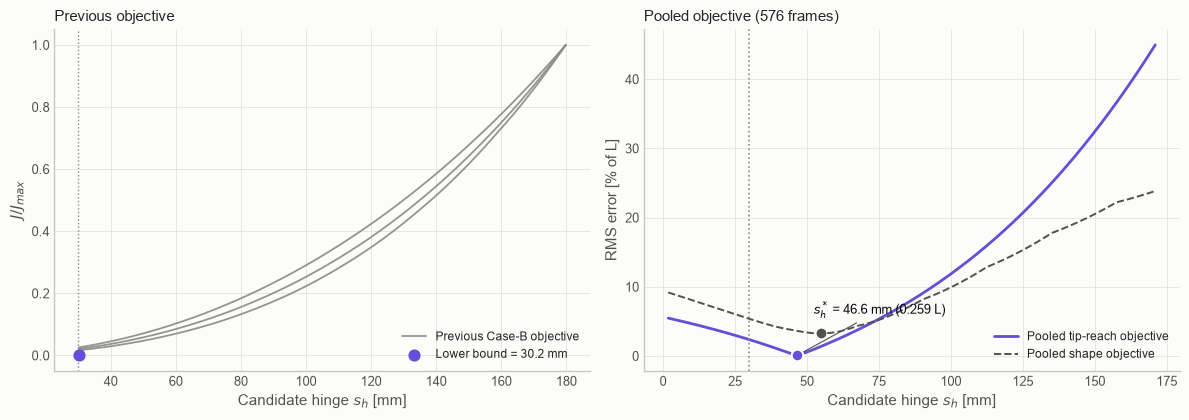

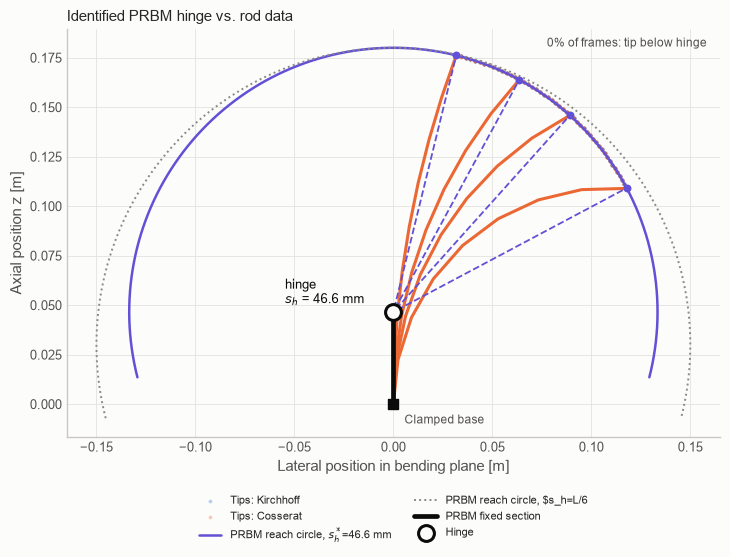

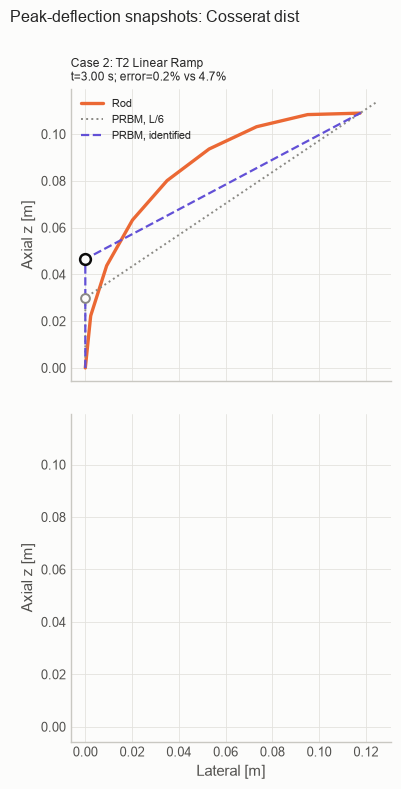

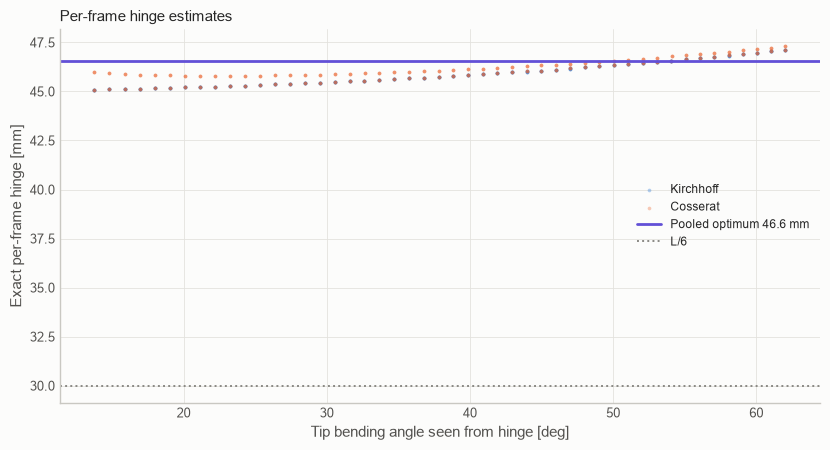

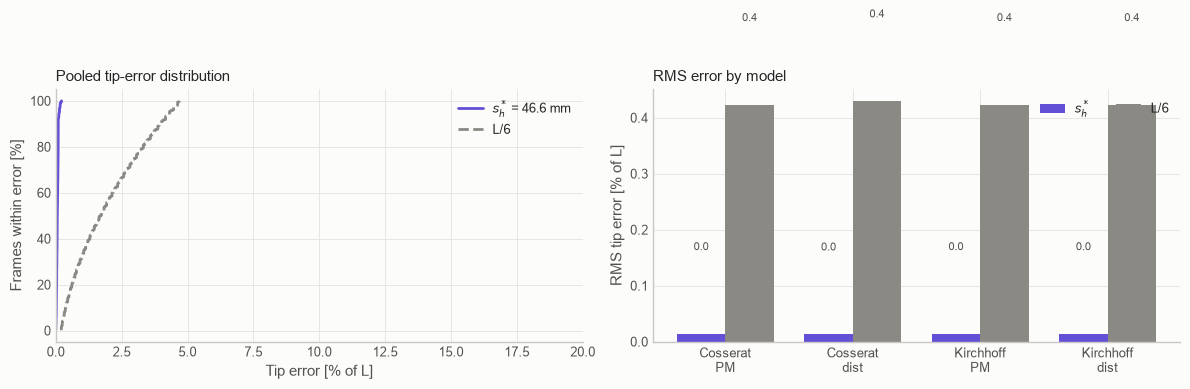

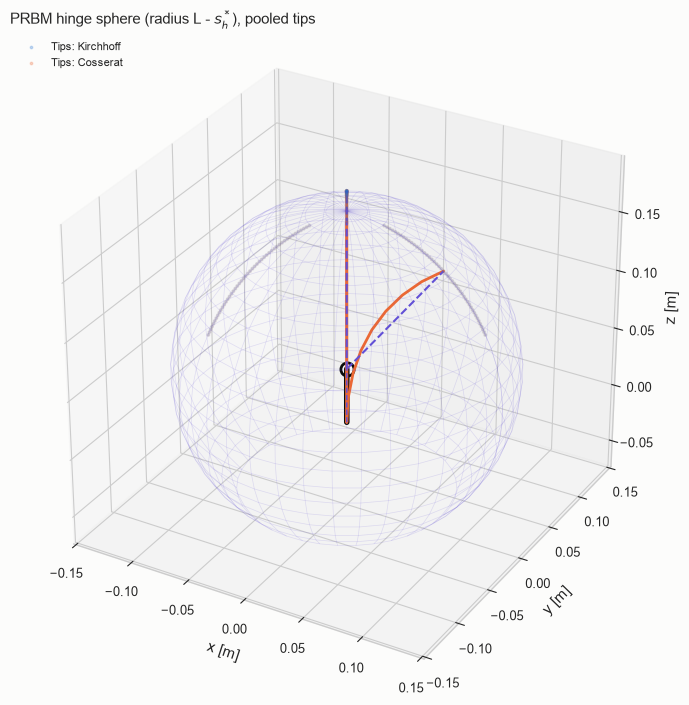

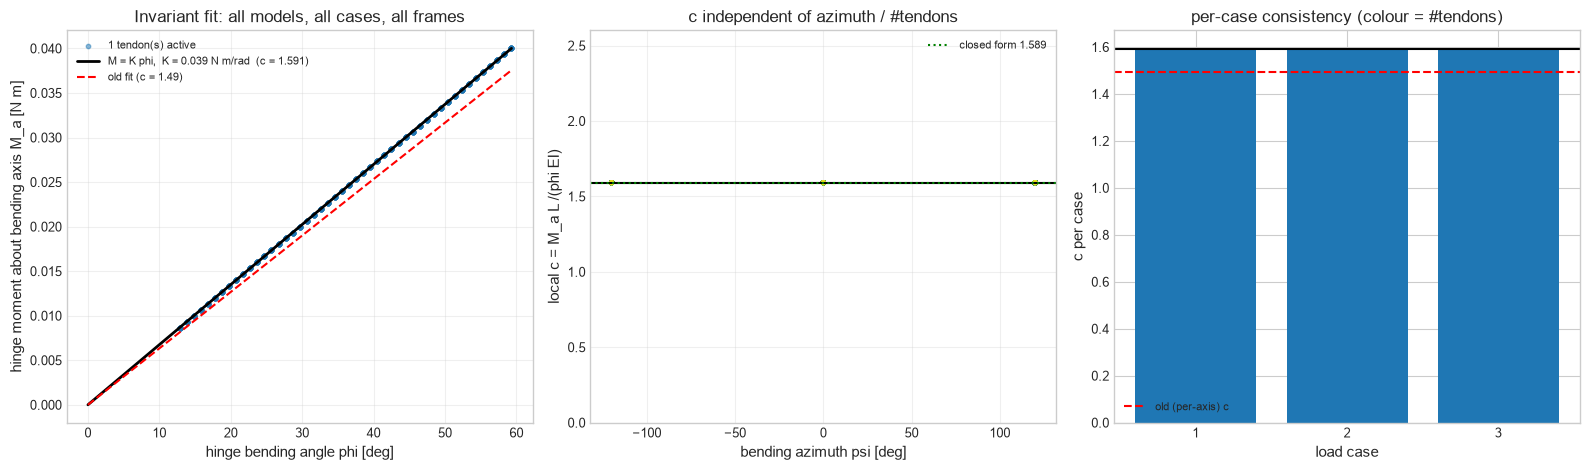

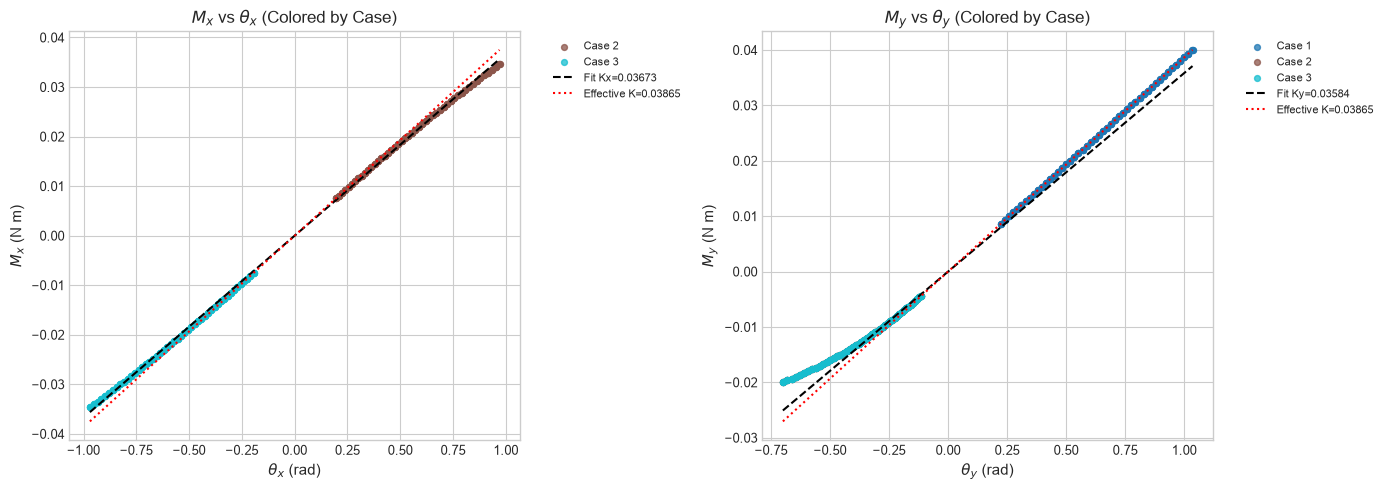


Identified PRBM: s_h=0.04655 m (0.2586 L), K=0.03865 N m/rad, c=1.5908


In [162]:
# ============================================================
# 1. POOLED HINGE IDENTIFICATION
# Requires: hinge_identification.py, hinge_plots.py
# ============================================================
import os, importlib, numpy as np
import matplotlib.pyplot as plt

# All four models are pooled; use one consistent source coordinate frame.
model_sources = {
    "Cosserat_PM":   (cosserat_results, "point_moment"),
    "Cosserat_dist": (cosserat_results, "distributed"),
    "Kirchhoff_PM":  (kirchhoff_results, "point_moment"),
    "Kirchhoff_dist":(kirchhoff_results, "distributed"),
}
SOURCE_FRAME = "world"  # "world" or "base"; must match saved states
base_position = np.asarray(base_position, dtype=float).reshape(3)
base_rotation = np.asarray(base_rotation, dtype=float).reshape(3, 3)

hinge_data = collect_frames(
    model_sources, L, cases=selected_cases,
    min_lateral_frac=1/6,
    base_position=base_position,
    base_rotation=base_rotation,
    input_frame=SOURCE_FRAME
)
print(f"Pooled frames: {hinge_data.n_frames}/{hinge_data.n_total}; "
      f"cases={len(np.unique(hinge_data.case))}, "
      f"models={len(np.unique(hinge_data.model))}")

# Primary hinge estimate and independent shape-objective estimate.
hinge = identify_hinge(hinge_data, objective="tip",
                          bounds=(0.01*L, 0.95*L))
hinge_c = identify_hinge(hinge_data, objective="tip",
                            bounds=(L/6 + 1e-3*L, L*(1 - 1e-3)))
hinge_shape = identify_hinge(hinge_data, objective="shape",
                                bounds=(0.01*L, 0.95*L))
print("PRIMARY:", hinge.summary())
print("Constrained s_h > L/6:", hinge_c.summary())
print(f"Shape objective: s_h={hinge_shape.s_h*1e3:.2f} mm "
      f"= {hinge_shape.fraction:.4f} L")

# Bootstrap by whole load cases.
boot = bootstrap_over_cases(hinge_data, n_boot=2000,
                               bounds=(0.01*L, 0.95*L))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"95% case-bootstrap interval: {lo*1e3:.2f}–{hi*1e3:.2f} mm")

# Exclude frames whose tip lies beyond 90 degrees from the local +z axis.
below = hinge_data.tips[:, 2] < hinge.s_h
if np.all(below):
    raise ValueError("No frames remain after the PRBM reach filter.")
reach = HingeData(
    L=hinge_data.L, s=hinge_data.s, P=hinge_data.P[~below],
    model=hinge_data.model[~below], case=hinge_data.case[~below],
    time=hinge_data.time[~below], n_total=hinge_data.n_total,
    base_position=hinge_data.base_position,
    base_rotation=hinge_data.base_rotation
)
hinge_reach = identify_hinge(reach, "tip", bounds=(0.01*L, 0.95*L))
print(f"{100*below.mean():.1f}% of frames curl past 90 degrees; "
      f"filtered fit: s_h={hinge_reach.s_h*1e3:.2f} mm "
      f"= {hinge_reach.fraction:.4f} L")

# Compare pooled tip errors.
for name, sh in (("Identified", hinge.s_h), ("Conventional L/6", L/6)):
    err = tip_error_at(hinge_data, sh)
    print(f"{name:>18}: RMS={100*err['rms']/L:.2f}% L, "
          f"max={100*err['max']/L:.2f}% L")

# ============================================================
# 2. HINGE PLOTS
# ============================================================
SAVE = None  # e.g. "hinge_figs"
def _p(name):
    if SAVE:
        os.makedirs(SAVE, exist_ok=True)
        return os.path.join(SAVE, name)
    return None

ref_case = 6 if 6 in kirchhoff_results else list(kirchhoff_results)[0]
st_ref = np.asarray(
    kirchhoff_results[ref_case]["point_moment"]["states"]
)[:, :, :3]

# Convert reference centerline to base coordinates only if it is world-frame.
if SOURCE_FRAME == "world":
    st_ref = (st_ref - base_position) @ base_rotation

plot_objectives(
    hinge_data, hinge, hinge_shape,
    old_frames=[st_ref[i] for i in (20, 40, 60) if i < len(st_ref)],
    old_s=kirchhoff_results[ref_case]["point_moment"]["s"],
    save=_p("1_objectives.png")
)
plot_prbm_setup(hinge_data, hinge, boot, save=_p("2_prbm_setup.png"))
plot_case_snapshots(
    hinge_data, hinge,
    cases=[c for c in (2,) if c in selected_cases],
    case_names=case_names, save=_p("3_case_snapshots.png")
)
plot_per_frame_hinge(hinge_data, hinge, boot, save=_p("4_per_frame_hinge.png"))
plot_error_distribution(hinge_data, hinge, save=_p("5_error_distribution.png"))
plot_prbm_3d(hinge_data, hinge, save=_p("6_prbm_3d.png"))

# ============================================================
# 3. STIFFNESS IDENTIFICATION
# ============================================================
n_active = {
    cid: count_active_tendons(kirchhoff_results[cid]["tendons"], t_final)
    for cid in selected_cases
}
stiff_data = collect_moment_angle(
    model_sources, L, hinge.s_h, EI,
    cases=selected_cases,
    n_active=n_active,
    min_lateral_frac=1/6,
    base_position=base_position,
    base_rotation=base_rotation,
    input_frame="world"
)
stiff = identify_stiffness(stiff_data)
print_report(stiff_data, stiff)
plot_stiffness(stiff_data, stiff)
Kx, Ky = plot_prbm_moment_angle(stiff_data, K_eff=stiff.K)
plt.show()
K_prbm = stiff.K
s_h = hinge.s_h
print(f"\nIdentified PRBM: s_h={s_h:.5f} m "
      f"({s_h/L:.4f} L), "
      f"K={K_prbm:.5f} N m/rad, c={stiff.c:.4f}")



In [163]:
import numpy as np
from scipy.integrate import solve_ivp
# ========================================================
# AnanthaSuresh IISc Mechanical Engineering
# PRBM 2R Pseudo-Rigid-Body Model for a TDCR
# ========================================================

class PRBM2R:
    """
    2-DOF Pseudo-Rigid-Body Model for a TDCR.

    Generalized coordinates:
        q = [alpha_x, alpha_y]
        q_dot = [alpha_x_dot, alpha_y_dot]

    No torsional DOF is included:
        alpha_z = 0

    First-stage tendon model:
        tau = sum_i(T_i * r_i)

    where r_i = [r_ix, r_iy] is the fixed bending moment-arm
    vector of tendon i.

    The configuration-dependent tendon Jacobian J_T(q)
    will be added later.
    """

    def __init__(self,L=0.20,r=0.003,m=0.005,E=1e7,
                 I_geom=None,K=None,C=None,g=9.81,l_g=None,
                 moment_arms=None,s_h=None,kinematics="legacy",Kx=None,Ky=None,base_position=None, base_rotation=None,
                         tip_load_enabled=False, tip_mass=0.0, tip_force=None):
        # kinematics = "legacy"  : original map d = (sin q0, sin q1, sqrt(1-sin^2 q0-sin^2 q1)).  The link is NOT rigid
        #                          once sin^2 q0 + sin^2 q1 > 1 (e.g. two tendons pulled together) and cannot bend past 90 deg.
        # kinematics = "rotvec"  : q = bending vector (|q| = bending angle phi, direction = bending azimuth);
        #                          d = (sin(phi) q/phi, cos(phi)).  |d| = 1 always, valid for phi < pi, isotropic spring
        #                          V = K|q|^2/2, full Lagrangian dynamics (configuration dependent inertia, Coriolis,
        #                          virtual-work tendon torque).  Equals "legacy" for small angles.
        if kinematics not in ("legacy","rotvec"):
            raise ValueError("kinematics must be 'legacy' or 'rotvec'.")
        self.kinematics = kinematics
        self.L = float(L)
        self.r = float(r)
        self.m = float(m)
        self.E = float(E)
        self.g = float(g)

        # Fixed base pose: base-frame vectors are transformed into world coordinates.
        self.base_position = np.zeros(3) if base_position is None else np.asarray(base_position, dtype=float).reshape(3)
        self.base_rotation = np.eye(3) if base_rotation is None else np.asarray(base_rotation, dtype=float).reshape(3, 3)
        if not np.allclose(self.base_rotation.T @ self.base_rotation, np.eye(3), atol=1e-8) or not np.isclose(np.linalg.det(self.base_rotation), 1.0, atol=1e-8):
            raise ValueError("base_rotation must be a proper rotation matrix in SO(3).")

        # Optional point payload and external tip force; force is expressed in world coordinates.
        self.tip_load_enabled = bool(tip_load_enabled)
        self.tip_mass = float(tip_mass)
        self.tip_force = np.zeros(3) if tip_force is None else np.asarray(tip_force, dtype=float).reshape(3)
        if self.tip_mass < 0:
            raise ValueError("tip_mass must be nonnegative.")
        
        # PRBM hinge and rotating-link lengths.
        # s_h : hinge position along the backbone [m].  Default L/6 (original setting);
        #       pass the value identified by hinge_identification.identify_hinge() to use the data-driven hinge.
        self.s_h = self.L/6.0 if s_h is None else float(s_h)
        if not 0.0 < self.s_h < self.L:
            raise ValueError("s_h must satisfy 0 < s_h < L.")
        self.L_rot = self.L-self.s_h
        self.l_g = self.L_rot/2 if l_g is None else float(L_rot/2)

        # Geometric second moment of area.
        self.I_geom = np.pi*self.r**4/4 if I_geom is None else float(I_geom)

        # Rotational inertia of the equivalent rotating link.
        self.Im = self.m*self.L_rot**2/3.0

        # Bending stiffness of each PRBM rotational DOF.
        #K = 2.25*self.E*self.I_geom/self.L
        if K is None:
            self.Kq = np.diag([Kx,Ky])
        elif np.isscalar(K):
            self.Kq = np.diag([float(K),float(K)])
            print(self.Kq)
        else:
            self.Kq = np.asarray(K,dtype=float).reshape(2,2)

        # Damping matrix.
        if C is None: self.Cq = self.Kq*0.01
        else: self.Cq = float(C)*np.eye(2) 
        

        # 2-DOF rotational inertia matrix.
        self.Mq = np.diag([self.Im,self.Im])
        self.Mq_inv = np.diag([1.0/self.Im,1.0/self.Im])   # constant -> invert once

        # Fixed tendon moment-arm vectors.
        # Each row corresponds to one tendon:
        # [r_ix, r_iy] -> bending moment produced by 1 N tension.
        if moment_arms is None:
            self.moment_arms = np.array([
                [0.012,0.0],
                [-0.006,0.0103923],
                [-0.006,-0.0103923]
            ],dtype=float)
        else:
            self.moment_arms = np.asarray(moment_arms,dtype=float)

        if self.moment_arms.ndim != 2 or self.moment_arms.shape[1] != 2:
            raise ValueError("moment_arms must have shape (N_tendons,2).")

        self.n_tendons = self.moment_arms.shape[0]

        

    
    def _direction_jacobian(self, q):
        """D = partial d / partial q, where d is the distal-link unit direction."""
        q = np.asarray(q, dtype=float).reshape(2)
        if self.kinematics == "legacy":
            dx, dy = np.sin(q)
            dz = np.sqrt(max(1e-14, 1.0-dx**2-dy**2))
            return np.array([
                [np.cos(q[0]), 0.0],
                [0.0, np.cos(q[1])],
                [-dx*np.cos(q[0])/dz, -dy*np.cos(q[1])/dz]
            ])
        phi = np.linalg.norm(q)
        g = self._gfun(phi)
        gp_over_phi = -1.0/3.0 + phi**2/30.0 if phi < 1e-3 else (phi*np.cos(phi)-np.sin(phi))/phi**3
        D = np.zeros((3, 2))
        D[:2] = g*np.eye(2) + gp_over_phi*np.outer(q, q)
        D[2] = -g*q
        return D

    def tip_jacobian(self, q, world=True):
        """J_tip = partial p_tip / partial q; optionally express it in world coordinates."""
        J = self.L_rot*self._direction_jacobian(q)
        return self.base_rotation @ J if world else J

    def _payload_mass_matrix(self, q):
        """Added inertia from the tip point mass: DeltaM = mp * J_tip.T @ J_tip."""
        if not self.tip_load_enabled or self.tip_mass == 0.0:
            return np.zeros((2, 2))
        J = self.tip_jacobian(q, world=False)
        return self.tip_mass*(J.T @ J)

    def mass_matrix(self, q):
        """Total generalized inertia of the robot plus optional tip payload."""
        M_robot = self._mass_rotvec(q) if self.kinematics == "rotvec" else self.Mq
        return M_robot + self._payload_mass_matrix(q)

    def _payload_coriolis(self, q, qd):
        """Christoffel inertial vector generated by the configuration-dependent payload inertia."""
        if not self.tip_load_enabled or self.tip_mass == 0.0:
            return np.zeros(2)
        eps = 1e-5
        dM = np.zeros((2, 2, 2))  # dM[k,i,j] = partial M[i,j] / partial q[k]
        for k in range(2):
            dq = np.zeros(2)
            dq[k] = eps
            dM[k] = (self._payload_mass_matrix(q+dq)-self._payload_mass_matrix(q-dq))/(2*eps)
        c = np.zeros(2)
        for i in range(2):
            for j in range(2):
                for k in range(2):
                    c[i] += 0.5*(dM[k, i, j]+dM[j, i, k]-dM[i, j, k])*qd[j]*qd[k]
        return c

    def tip_generalized_force(self, q):
        """Map the enabled world-frame tip force into generalized coordinates: Q = J_world.T @ F_world."""
        if not self.tip_load_enabled:
            return np.zeros(2)
        return self.tip_jacobian(q, world=True).T @ self.tip_force

    # =========================================================
    # Rotation-vector kinematics / dynamics  (kinematics="rotvec")
    # =========================================================

    @staticmethod
    def _gfun(phi):
        """g(phi) = sin(phi)/phi."""
        return 1.0-phi**2/6.0+phi**4/120.0 if phi < 1e-4 else np.sin(phi)/phi

    def direction(self,q):
        """Unit direction d of the rigid distal link for the generalized coordinates q."""
        q = np.asarray(q,dtype=float).reshape(2)
        if self.kinematics == "legacy":
            dx,dy = np.sin(q)
            return np.array([dx,dy,np.sqrt(max(0.0,1.0-dx**2-dy**2))])
        phi = np.linalg.norm(q)
        g = self._gfun(phi)
        return np.array([g*q[0],g*q[1],np.cos(phi)])

    def rotation_matrix(self,q):
        """Rotation of the distal link (Rodrigues, rotation vector Theta = (-q1, q0, 0))."""
        q = np.asarray(q,dtype=float).reshape(2)
        if self.kinematics == "legacy":
            ax,ay = q
            Rx = np.array([[1.0,0.0,0.0],[0.0,np.cos(ax),-np.sin(ax)],[0.0,np.sin(ax),np.cos(ax)]])
            Ry = np.array([[np.cos(ay),0.0,np.sin(ay)],[0.0,1.0,0.0],[-np.sin(ay),0.0,np.cos(ay)]])
            return Ry@Rx
        phi = np.linalg.norm(q)
        th = np.array([-q[1],q[0],0.0])
        Kx = np.array([[0.0,-th[2],th[1]],[th[2],0.0,-th[0]],[-th[1],th[0],0.0]])
        A = np.sin(phi)/phi if phi > 1e-8 else 1.0-phi**2/6.0
        B = (1.0-np.cos(phi))/phi**2 if phi > 1e-4 else 0.5-phi**2/24.0
        return np.eye(3)+A*Kx+B*(Kx@Kx)

    def _mass_rotvec(self,q):
        """M(q) = Im [ g^2 I + w q q^T ],  w = (1-g^2)/phi^2   (thin rigid link: T = Im |d_dot|^2 / 2)."""
        phi = np.linalg.norm(q)
        g = self._gfun(phi)
        w = (1.0/3.0-2.0*phi**2/45.0) if phi < 1e-3 else (1.0-g*g)/phi**2
        return self.Im*(g*g*np.eye(2)+w*np.outer(q,q))

    def _dmass_rotvec(self,q):
        """dM/dq_k  (shape (2,2,2): [k,i,j])."""
        phi = np.linalg.norm(q)
        g = self._gfun(phi)
        G = g*g
        if phi < 1e-3:
            Gp_over_phi = -2.0/3.0+8.0*phi**2/45.0*0.5            # G'/phi,  G = 1 - phi^2/3 + 2 phi^4/45
            wp_over_phi = -4.0/45.0
            w = 1.0/3.0-2.0*phi**2/45.0
        else:
            gp = (phi*np.cos(phi)-np.sin(phi))/phi**2
            Gp = 2.0*g*gp
            w = (1.0-G)/phi**2
            wp = -Gp/phi**2-2.0*(1.0-G)/phi**3
            Gp_over_phi,wp_over_phi = Gp/phi,wp/phi
        out = np.zeros((2,2,2))
        I2 = np.eye(2)
        for k in range(2):
            ek = I2[k]
            out[k] = self.Im*(Gp_over_phi*q[k]*I2+wp_over_phi*q[k]*np.outer(q,q)+w*(np.outer(ek,q)+np.outer(q,ek)))
        return out

    def _coriolis_rotvec(self,q,qd):
        dM = self._dmass_rotvec(q)
        c = np.zeros(2)
        for i in range(2):
            for j in range(2):
                for k in range(2):
                    c[i] += 0.5*(dM[k][i,j]+dM[j][i,k]-dM[i][j,k])*qd[j]*qd[k]
        return c

    def _tendon_force_rotvec(self,tau,q):
        """
        Generalized force of the tendon moment, by virtual work.

        The tendon moment is a moment on the cross-section, i.e. it rotates WITH the link:
            M_body  = z x tau = (-tau_y, tau_x, 0)          (tau = sum_i T_i r_i, as in the legacy model)
            M_world = R(q) M_body                           (always perpendicular to the link axis d)
            Q_k     = M_world . (d x d d/d q_k)
        This is the configuration-dependent tendon Jacobian J_T(q) announced in the class docstring.
        For q parallel to tau (planar bending) it reduces to Q = tau.
        """
        q = np.asarray(q,dtype=float)
        phi = np.linalg.norm(q)
        g = self._gfun(phi)
        gp_over_phi = -1.0/3.0+phi**2/30.0 if phi < 1e-3 else (phi*np.cos(phi)-np.sin(phi))/phi**3
        d = np.array([g*q[0],g*q[1],np.cos(phi)])
        D = np.zeros((3,2))
        D[:2,:] = g*np.eye(2)+gp_over_phi*np.outer(q,q)
        D[2,:] = -g*q
        Mw = self.rotation_matrix(q)@np.array([-tau[1],tau[0],0.0])
        return np.array([Mw@np.cross(d,D[:,k]) for k in range(2)])

    # =========================================================
    # PRBM centerline
    # =========================================================

    def shape(self,q,n=100,world = False):
        """
        Return 3-D PRBM centerline.

        q = [alpha_x, alpha_y]

        The rotating section is approximated as a straight
        rigid link whose direction is obtained from the two
        bending angles.
        """
        q = np.asarray(q,dtype=float).reshape(2)
        d = self.direction(q)

        s = np.linspace(0.0,self.L,n)
        r = np.zeros((n,3))

        fixed = s <= self.s_h
        r[fixed,2] = s[fixed]

        sr = s[~fixed]-self.s_h

        # Rigid distal link of length L_rot along the unit direction d.
        r[~fixed,0] = sr*d[0]
        r[~fixed,1] = sr*d[1]
        r[~fixed,2] = self.s_h+sr*d[2]

        if world:
            r = self.base_position + r @ self.base_rotation.T
        return s,r

    # =========================================================
    # Tip kinematics
    # =========================================================
    
    def tip_pose(self, q, world=False):
        """Return tip position in the base frame or world frame, plus q."""
        d = self.direction(q)
        p = np.array([self.L_rot*d[0], self.L_rot*d[1], self.s_h+self.L_rot*d[2]])
        if world:
            p = self.base_position + self.base_rotation @ p
        return p, np.asarray(q, dtype=float).reshape(2).copy()

    # =========================================================
    # Tendon moments
    # =========================================================

    def tendon_moments(self,tensions,t=None):
        """
        Compute total 2-D bending moment from all tendons.

        tau = sum_i(r_i*T_i)

        Output:
            tau = [tau_x,tau_y]
        """
        if callable(tensions):
            if t is None:
                raise ValueError("Time t is required for callable tensions.")
            tensions = tensions(t)

        T = np.asarray(tensions,dtype=float).reshape(-1)

        if T.size != self.n_tendons:
            raise ValueError(
                f"Expected {self.n_tendons} tendon tensions, got {T.size}."
            )

        # Each row:
        # [T_i*r_ix, T_i*r_iy]
        tendon_moments = self.moment_arms*T[:,None]

        # Sum moments from all tendons.
        return np.sum(tendon_moments,axis=0)

    # =========================================================
    # Individual tendon moment history
    # =========================================================

    def individual_tendon_moments(self,tensions,t=None):
        """
        Return individual tendon moment vectors.

        Output shape:
            (N_tendons,2)
        """
        if callable(tensions):
            if t is None:
                raise ValueError("Time t is required for callable tensions.")
            tensions = tensions(t)

        T = np.asarray(tensions,dtype=float).reshape(-1)

        if T.size != self.n_tendons:
            raise ValueError(
                f"Expected {self.n_tendons} tendon tensions, got {T.size}."
            )

        return self.moment_arms*T[:,None]

    # =========================================================
    # Gravity generalized moment
    # =========================================================

    
    def gravity_moment(self, q):
        """World-gravity generalized load for the equivalent robot COM."""
        J_com = self.l_g*self._direction_jacobian(q)
        J_com_world = self.base_rotation @ J_com
        gravity_world = np.array([0.0, 0.0, -self.g])
        return J_com_world.T @ (self.m*gravity_world)


    # =========================================================
    # Input torque
    # =========================================================

    def input_torque(self,t,q,input_function=None,tensions=None):
        """
        Return total 2-DOF generalized tendon torque.

        input_function, if supplied, must return:
            [tau_x,tau_y]

        Otherwise tensions are converted into moments.
        """
        q = np.asarray(q,dtype=float).reshape(2)

        if input_function is not None:
            tau = np.asarray(input_function(t,q),dtype=float).reshape(2)
            return tau

        if tensions is not None:
            return self.tendon_moments(tensions,t)

        return np.zeros(2)

    
    # =========================================================
    # INVERSE KINEMATICS: Cosserat tip -> PRBM angular reference
    # =========================================================
    
    # =========================================================
    # INVERSE KINEMATICS: Cosserat tip -> PRBM angular reference
    # =========================================================

    def _project_legacy_xy(self, p, max_angle_deg=80.0):
        """Project a local tip position onto the safe legacy PRBM workspace."""
        if not (0.0 < max_angle_deg < 90.0):
            raise ValueError("max_angle_deg must be between 0 and 90 degrees.")

        p = np.asarray(p, dtype=float).reshape(3)
        sx, sy = p[0]/self.L_rot, p[1]/self.L_rot

        # The safe workspace is a circle of radius sin(max_angle).
        rho = np.hypot(sx, sy)
        rho_max = np.sin(np.deg2rad(max_angle_deg))
        scale = min(1.0, rho_max/max(rho, 1e-12))
        sx_clip, sy_clip = scale*sx, scale*sy

        # Inverse kinematics after workspace projection.
        q = np.arcsin(np.clip([sx_clip, sy_clip], -1.0, 1.0))
        radicand = max(0.0, 1.0-sx_clip**2-sy_clip**2)
        z_pred = self.s_h+self.L_rot*np.sqrt(radicand)
        z_error = p[2]-z_pred
        clipped = scale < 1.0-1e-12

        return q, z_error, clipped, scale, rho

    def inverse_kinematics(self, tip_position, world=True, strict=False,
                           tol=1e-4, max_angle_deg=80.0):
        """
        Analytical legacy IK with automatic workspace projection.
        Returns q=[alpha_x,alpha_y] and axial position residual.
        """
        if self.kinematics != "legacy":
            raise ValueError("This inverse_kinematics method is for legacy kinematics only.")

        p = np.asarray(tip_position, dtype=float).reshape(3)
        if world:
            p = self.base_rotation.T @ (p-self.base_position)

        q, z_error, clipped, scale, rho = self._project_legacy_xy(
            p, max_angle_deg=max_angle_deg
        )

        if strict and abs(z_error) > tol:
            raise ValueError(f"Tip is outside the PRBM reachable surface: axial error={z_error:.6g} m.")

        return q, z_error

    def inverse_kinematics_trajectory(self, tip_position, world=True,
                                      strict=False, tol=1e-4,
                                      max_angle_deg=80.0):
        """Analytical IK for an entire tip-position trajectory."""
        P = np.asarray(tip_position, dtype=float)
        if P.ndim != 2 or P.shape[1] != 3:
            raise ValueError("Tip trajectory must have shape (N,3).")

        q_ref = np.zeros((len(P), 2))
        z_error = np.zeros(len(P))
        for k, pk in enumerate(P):
            q_ref[k], z_error[k] = self.inverse_kinematics(
                pk, world=world, strict=strict, tol=tol,
                max_angle_deg=max_angle_deg
            )
        return q_ref, z_error

    # =========================================================
    # REFERENCE DERIVATIVES: clipped q -> qdot and qddot
    # =========================================================

    def inverse_reference(self, time, tip_position, tip_velocity,
                          tip_acceleration=None, world=True,
                          strict=False, tol=1e-4,
                          max_angle_deg=80.0):
        """
        Generate q_ref, qd_ref and qdd_ref from Cosserat tip histories.
        Derivatives are calculated from the clipped angular trajectory,
        ensuring consistency with the projected PRBM reference.
        """
        if self.kinematics != "legacy":
            raise ValueError("This reference conversion is for legacy kinematics only.")

        t = np.asarray(time, dtype=float).reshape(-1)
        P = np.asarray(tip_position, dtype=float)
        V = np.asarray(tip_velocity, dtype=float)

        if len(t) < 2:
            raise ValueError("At least two time samples are required.")
        if P.shape != (len(t), 3) or V.shape != (len(t), 3):
            raise ValueError("Position and velocity histories must have shape (N,3).")
        if not np.all(np.isfinite(P)) or not np.all(np.isfinite(V)):
            raise ValueError("Position and velocity histories contain NaN or Inf.")
        if np.any(np.diff(t) <= 0):
            raise ValueError("Time must be strictly increasing.")

        if tip_acceleration is None:
            edge = 2 if len(t) > 2 else 1
            A_world = np.gradient(V, t, axis=0, edge_order=edge)
        else:
            A_world = np.asarray(tip_acceleration, dtype=float).copy()
            if A_world.shape != (len(t), 3):
                raise ValueError("Acceleration history must have shape (N,3).")
            bad = ~np.all(np.isfinite(A_world), axis=1)
            if np.any(bad):
                edge = 2 if len(t) > 2 else 1
                A_num = np.gradient(V, t, axis=0, edge_order=edge)
                A_world[bad] = A_num[bad]

        # Transform world-frame histories into the PRBM base frame.
        if world:
            P_local = (P-self.base_position) @ self.base_rotation
            V_local = V @ self.base_rotation
            A_local = A_world @ self.base_rotation
        else:
            P_local, V_local, A_local = P.copy(), V.copy(), A_world.copy()

        # Apply workspace projection independently at every time sample.
        n = len(t)
        q_ref = np.zeros((n, 2))
        z_error = np.zeros(n)
        ik_clipped = np.zeros(n, dtype=bool)
        ik_scale = np.ones(n)
        ik_rho = np.zeros(n)

        for k in range(n):
            q_ref[k], z_error[k], ik_clipped[k], ik_scale[k], ik_rho[k] = (
                self._project_legacy_xy(P_local[k], max_angle_deg)
            )

        if strict and np.any(np.abs(z_error) > tol):
            k = np.argmax(np.abs(z_error))
            raise ValueError(
                f"Tip outside PRBM reachable surface at sample {k}: "
                f"axial error={z_error[k]:.6g} m."
            )

        # Differentiate the actual clipped angular reference.
        edge = 2 if len(t) > 2 else 1
        qd_ref = np.gradient(q_ref, t, axis=0, edge_order=edge)
        qdd_ref = np.gradient(qd_ref, t, axis=0, edge_order=edge)

        return {
            "time": t,
            "p_local": P_local,
            "v_local": V_local,
            "a_local": A_local,
            "q_ref": q_ref,
            "qd_ref": qd_ref,
            "qdd_ref": qdd_ref,
            "ik_z_error": z_error,
            "ik_clipped": ik_clipped,
            "ik_scale": ik_scale,
            "ik_rho": ik_rho,
            "max_angle_deg": max_angle_deg
        }

    # =========================================================
    # INVERSE DYNAMICS: PRBM reference -> required tendon moments
    # =========================================================

    def inverse_dynamics(self, q_ref, qd_ref, qdd_ref):
        """
        Required generalized tendon moments using the exact PRBM
        state_equation sign convention.
        """
        q_ref = np.asarray(q_ref, dtype=float)
        qd_ref = np.asarray(qd_ref, dtype=float)
        qdd_ref = np.asarray(qdd_ref, dtype=float)

        if self.kinematics != "legacy":
            raise ValueError("This inverse-dynamics block is configured for legacy kinematics.")
        if q_ref.ndim != 2 or q_ref.shape[1] != 2:
            raise ValueError("q_ref must have shape (N,2).")
        if qd_ref.shape != q_ref.shape or qdd_ref.shape != q_ref.shape:
            raise ValueError("q_ref, qd_ref and qdd_ref must have matching shapes.")

        Q_required = np.zeros_like(q_ref)
        for k, (q, qd, qdd) in enumerate(zip(q_ref, qd_ref, qdd_ref)):
            M = self.mass_matrix(q)
            c = self._payload_coriolis(q, qd)
            Q_tip = self.tip_generalized_force(q)

            Q_payload_g = np.zeros(2)
            if self.tip_load_enabled and self.tip_mass > 0.0:
                Fg = np.array([0.0, 0.0, -self.g*self.tip_mass])
                Q_payload_g = self.tip_jacobian(q, world=True).T @ Fg

            # Invert: M*qdd = Qtendon + Qg + Qtip + Qpayload_g - c - Cqd - Kq.
            Q_required[k] = (
                M @ qdd + c + self.Cq @ qd + self.Kq @ q
                - self.gravity_moment(q) - Q_tip - Q_payload_g
            )

        return Q_required

    # =========================================================
    # GENERAL TENDON ALLOCATION: generalized moment -> tensions
    # =========================================================

    def allocate_tensions(self, Q_required, T_nominal=1.0,
                          T_min=0.0, T_max=None, tol=1e-7):
        """
        Minimum-deviation tension allocation:
            min 0.5*||T-T_nominal||^2
            subject to moment_arms.T @ T = Q_required
                       T_min <= T <= T_max.
        """
        from scipy.optimize import minimize

        A = self.moment_arms.T
        if np.linalg.matrix_rank(A) < 2:
            raise ValueError("Tendon moment-arm matrix must have rank 2.")

        Q = np.asarray(Q_required, dtype=float).reshape(2)
        n = self.n_tendons
        T0 = np.broadcast_to(np.asarray(T_nominal, dtype=float), (n,)).copy()
        lo = np.broadcast_to(np.asarray(T_min, dtype=float), (n,)).copy()
        hi = np.full(n, np.inf) if T_max is None else np.broadcast_to(
            np.asarray(T_max, dtype=float), (n,)
        ).copy()

        if np.any(lo > hi):
            raise ValueError("T_min cannot exceed T_max.")

        # Unconstrained minimum-distance solution as initial guess.
        T_init = T0 + A.T @ np.linalg.solve(A @ A.T, Q-A @ T0)
        T_init = np.clip(T_init, lo, hi)
        bounds = [(lo[j], None if np.isinf(hi[j]) else hi[j]) for j in range(n)]

        sol = minimize(
            lambda T: 0.5*np.sum((T-T0)**2),
            T_init,
            jac=lambda T: T-T0,
            method="SLSQP",
            bounds=bounds,
            constraints={
                "type": "eq",
                "fun": lambda T: A @ T-Q,
                "jac": lambda T: A
            },
            options={"ftol": 1e-12, "maxiter": 200}
        )

        residual = A @ sol.x-Q
        if not sol.success or np.linalg.norm(residual) > tol:
            raise RuntimeError(
                f"Tendon allocation failed/infeasible: {sol.message}; "
                f"moment residual={np.linalg.norm(residual):.3e} Nm."
            )

        return sol.x

    # =========================================================
    # COMPLETE INVERSE REFERENCE PIPELINE
    # =========================================================

    def inverse_control_reference(self, cosserat_result, T_nominal=1.0,
                                  T_min=0.0, T_max=None,
                                  strict_ik=False, ik_tol=1e-4,
                                  max_angle_deg=80.0):
        """
        Cosserat output -> PRBM angular reference -> inverse dynamics
        -> bounded general tendon tension histories.
        """
        if "tip_world" in cosserat_result:
            P = np.asarray(cosserat_result["tip_world"], dtype=float)
        elif "tip" in cosserat_result:
            P = np.asarray(cosserat_result["tip"], dtype=float)
        elif all(k in cosserat_result for k in ("x_tip", "y_tip", "z_tip")):
            P = np.column_stack((
                cosserat_result["x_tip"],
                cosserat_result["y_tip"],
                cosserat_result["z_tip"]
            ))
        elif "states" in cosserat_result:
            P = np.asarray(cosserat_result["states"][:, -1, 0:3], dtype=float)
        else:
            raise KeyError(
                "Cosserat tip position not found. Available keys: "
                f"{list(cosserat_result.keys())}"
            )

        t = np.asarray(cosserat_result["time"], dtype=float)

        if "tip_velocity" in cosserat_result:
            V = np.asarray(cosserat_result["tip_velocity"], dtype=float)
        else:
            edge = 2 if len(t) > 2 else 1
            V = np.gradient(P, t, axis=0, edge_order=edge)

        ref = self.inverse_reference(
            t, P, V,
            cosserat_result.get("tip_acceleration"),
            world=True, strict=strict_ik, tol=ik_tol,
            max_angle_deg=max_angle_deg
        )

        Q_required = self.inverse_dynamics(
            ref["q_ref"], ref["qd_ref"], ref["qdd_ref"]
        )

        T_ref = np.zeros((len(t), self.n_tendons))
        for k in range(len(t)):
            T_ref[k] = self.allocate_tensions(
                Q_required[k], T_nominal=T_nominal,
                T_min=T_min, T_max=T_max
            )

        ref["Q_required"] = Q_required
        ref["tensions"] = T_ref
        ref["moment_reconstruction"] = T_ref @ self.moment_arms
        ref["moment_residual"] = ref["moment_reconstruction"]-Q_required
        ref["tip_world_cosserat"] = P
        ref["tension_nominal"] = T_nominal
        ref["tension_min"] = T_min
        ref["tension_max"] = T_max
        return ref

    # =========================================================
    # INVERSE-DYNAMICS TRACKING SIMULATION
    # =========================================================

    def simulate_inverse_tracking(self, reference, dt=0.002, x0=None,
                                  Kp=2.0, Kd=0.2,
                                  T_min=0.0, T_max=None,
                                  method="RK45", rtol=1e-8, atol=1e-10):
        """
        Track q_ref using inverse-dynamics feedforward + PD feedback.
        Tendon tensions are recalculated from the commanded moment.
        """
        from scipy.integrate import solve_ivp

        t_ref = np.asarray(reference["time"], dtype=float)
        q_ref = np.asarray(reference["q_ref"], dtype=float)
        qd_ref = np.asarray(reference["qd_ref"], dtype=float)
        Q_ff = np.asarray(reference["Q_required"], dtype=float)

        if len(t_ref) < 2 or np.any(np.diff(t_ref) <= 0):
            raise ValueError("Reference time must contain at least two increasing samples.")

        kp = np.broadcast_to(np.asarray(Kp, dtype=float), (2,))
        kd = np.broadcast_to(np.asarray(Kd, dtype=float), (2,))
        if x0 is None:
            x0 = np.r_[q_ref[0], qd_ref[0]]
        x0 = np.asarray(x0, dtype=float).reshape(4)

        def interp(arr, t):
            return np.array([
                np.interp(t, t_ref, arr[:, j])
                for j in range(arr.shape[1])
            ])

        def controller(t, x):
            q_des = interp(q_ref, t)
            qd_des = interp(qd_ref, t)
            Qbase = interp(Q_ff, t)
            q, qdot = x[:2], x[2:]

            # Feedforward inverse dynamics + angular PD correction.
            Qcmd = Qbase + kp*(q_des-q) + kd*(qd_des-qdot)

            Tcmd = self.allocate_tensions(
                Qcmd,
                T_nominal=reference["tensions"][0],
                T_min=T_min,
                T_max=T_max
            )
            return Qcmd, Tcmd

        def rhs(t, x):
            _, Tcmd = controller(t, x)
            return self.state_equation(t, x, tensions=Tcmd)

        n_out = max(1, int(np.ceil((t_ref[-1]-t_ref[0])/dt)))
        t_eval = np.linspace(t_ref[0], t_ref[-1], n_out+1)
        sol = solve_ivp(
            rhs, (t_ref[0], t_ref[-1]), x0,
            t_eval=t_eval, method=method, rtol=rtol, atol=atol
        )
        if not sol.success:
            raise RuntimeError(sol.message)

        q = sol.y[:2].T
        qd = sol.y[2:].T
        qdd = np.zeros_like(q)
        T_hist = np.zeros((len(sol.t), self.n_tendons))
        Q_hist = np.zeros((len(sol.t), 2))

        for k, tk in enumerate(sol.t):
            xk = np.r_[q[k], qd[k]]
            Q_hist[k], T_hist[k] = controller(tk, xk)
            qdd[k] = self.state_equation(
                tk, xk, tensions=T_hist[k]
            )[2:]

        tip_world = np.array([
            self.tip_pose(qk, world=True)[0] for qk in q
        ])

        return {
            "time": sol.t,
            "q": q,
            "q_dot": qd,
            "q_ddot": qdd,
            "tip_world": tip_world,
            "tip": tip_world,
            "tensions": T_hist,
            "Q_command": Q_hist,
            "success": sol.success,
            "message": sol.message
        }


    # =========================================================
    # Static equilibrium (initial condition consistent with the rod solvers)
    # =========================================================

    def equilibrium(self, tensions, t=0.0):
        """Find static equilibrium using the same loads as the dynamic model."""
        from scipy.optimize import least_squares

        tau = self.tendon_moments(tensions, t)
        limit = np.pi - 0.02 if self.kinematics == "rotvec" else np.pi/2 - 1e-4

        def residual(q):
            # Tendon generalized force follows the selected kinematic model.
            Q_tendon = self._tendon_force_rotvec(tau, q) if self.kinematics == "rotvec" else tau
            # Include robot gravity and external tip force.
            Q = Q_tendon + self.gravity_moment(q) + self.tip_generalized_force(q)
            # Include payload gravity when a tip mass is enabled.
            if self.tip_load_enabled and self.tip_mass > 0.0:
                Fg = np.array([0.0, 0.0, -self.g*self.tip_mass])
                Q += self.tip_jacobian(q, world=True).T @ Fg
            return Q - self.Kq @ q

        # The linear estimate is only an initial guess; clip it to a safe range.
        try:
            q_linear = np.linalg.solve(self.Kq, tau)
        except np.linalg.LinAlgError:
            q_linear = np.zeros(2)
        q_linear = np.clip(q_linear, -limit, limit)

        starts = [np.zeros(2), q_linear]
        starts += [np.array([a, b]) for a in (-1.0, 1.0)
                for b in (-1.0, 1.0)]
        lower = np.full(2, -limit)
        upper = np.full(2, limit)
        candidates = []

        for q0 in starts:
            sol = least_squares(
                residual, np.clip(q0, lower + 1e-8, upper - 1e-8),
                bounds=(lower, upper), x_scale="jac",
                ftol=1e-12, xtol=1e-12, gtol=1e-12, max_nfev=3000
            )
            # Reject configurations outside the valid rotvec bending range.
            if self.kinematics != "rotvec" or np.linalg.norm(sol.x) < limit:
                candidates.append((np.linalg.norm(residual(sol.x)), sol.x, sol.message))

        if not candidates:
            raise RuntimeError("No candidate equilibrium inside the valid bending range.")

        norm_R, q_eq, message = min(candidates, key=lambda item: item[0])
        tol = 1e-7
        if norm_R > tol:
            raise RuntimeError(
                f"Static equilibrium not found: residual norm={norm_R:.6g} N·m; "
                f"best q={q_eq}, |q|={np.linalg.norm(q_eq):.6g} rad. "
                "Check tendon loads, gravity/base orientation, tip loading, and stiffness."
            )
        return q_eq

    # =========================================================
    # Nonlinear state equation
    # =========================================================

    
    def state_equation(self, t, state, input_function=None, tensions=None):
        """M(q)qdd + c(q,qd) + Cqd + Kq = Qt + Qg + Qtip."""
        state = np.asarray(state, dtype=float).reshape(4)
        q, q_dot = state[:2], state[2:]

        tau = self.input_torque(t, q, input_function=input_function, tensions=tensions)
        tau_g = self.gravity_moment(q)
        M = self.mass_matrix(q)

        # External tip force and payload gravity are world-frame loads.
        Q_tip = self.tip_generalized_force(q)
        Q_payload_g = np.zeros(2)
        if self.tip_load_enabled and self.tip_mass > 0.0:
            gravity_world = np.array([0.0, 0.0, -self.g])
            Q_payload_g = self.tip_jacobian(q, world=True).T @ (self.tip_mass*gravity_world)

        # Configuration-dependent inertia produces Coriolis/centrifugal terms.
        c = self._coriolis_rotvec(q, q_dot) if self.kinematics == "rotvec" else np.zeros(2)
        c += self._payload_coriolis(q, q_dot)

        q_ddot = np.linalg.solve(
            M,
            tau + tau_g + Q_tip + Q_payload_g
            - c - self.Cq @ q_dot - self.Kq @ q
        )
        return np.hstack((q_dot, q_ddot))


    # =========================================================
    # Simulation
    # =========================================================

    def simulate(self, t_span=(0.0,10.0), x0=None, dt=0.002,
             input_function=None, tensions=None, method="RK45",
             rtol=1e-8, atol=1e-10, stop_at_singularity=False,
             world_coordinates=True):

        """
        Simulate the 2-DOF PRBM.

        State:
            [alpha_x,alpha_y,alpha_x_dot,alpha_y_dot]

        The returned structure is compatible with the
        continuum-model plotting functions.
        """
        if x0 is None:
            x0 = np.zeros(4)

        x0 = np.asarray(x0,dtype=float).reshape(4)

        # linspace (not arange) so the last sample is exactly t_span[1];
        # solve_ivp rejects t_eval values that exceed t_span by round-off.
        n_out = int(round((t_span[1]-t_span[0])/dt))
        t_eval = np.linspace(t_span[0],t_span[1],n_out+1)

        events = None
        if self.kinematics == "rotvec":
            # q = bending vector has a coordinate singularity at |q| = pi (link pointing straight down).
            def _south_pole(t,x):
                return np.pi-0.02-np.hypot(x[0],x[1])
            _south_pole.terminal = True
            events = _south_pole

        sol = solve_ivp(
            lambda t,x: self.state_equation(
                t,x,
                input_function=input_function,
                tensions=tensions
            ),
            t_span,
            x0,
            t_eval=t_eval,
            method=method,
            rtol=rtol,
            atol=atol,
            events=events
        )

        terminated_early = False
        if self.kinematics == "rotvec" and sol.status == 1:
            msg = (f"PRBM bending angle reached pi at t={sol.t_events[0][0]:.4f} s (link pointing straight down): "
                   "the 2-angle PRBM is singular there (physically: the load drives the link past 180 deg).")
            if not stop_at_singularity:
                raise RuntimeError(msg+" Pass stop_at_singularity=True to keep the part before this instant.")
            print("WARNING:",msg,"Result truncated.")
            terminated_early = True
        elif not sol.success:
            raise RuntimeError(sol.message)

        time = sol.t
        q = sol.y[:2].T
        q_dot = sol.y[2:].T
        nt = len(time)

        # -----------------------------------------------------
        # Spatial grid.
        # -----------------------------------------------------
        s = np.linspace(0.0,self.L,100)
        ns = len(s)

        # Common state:
        # [p(3),R(9),n(3),m(3),q(3)] = 21 states
        states = np.zeros((nt,ns,21))

        # Histories.
        q_ddot = np.zeros((nt,2))
        tau = np.zeros((nt,2))
        tendon_moments = np.zeros((nt,self.n_tendons,2))

        for k,t in enumerate(time):
            qk = q[k]
            qdk = q_dot[k]

            # PRBM acceleration.
            xk = np.hstack((qk,qdk))
            dxk = self.state_equation(
                t,xk,
                input_function=input_function,
                tensions=tensions
            )
            q_ddot[k] = dxk[2:4]

            # Total tendon moment.
            tau[k] = self.input_torque(
                t,qk,
                input_function=input_function,
                tensions=tensions
            )

            # Individual tendon contributions.
            if tensions is not None:
                tendon_moments[k] = self.individual_tendon_moments(
                    tensions,t
                )

            # -------------------------------------------------
            # PRBM backbone geometry.
            # -------------------------------------------------
            # Backbone coordinates: rotate and translate into the world frame if requested.
            _, centerline_base = self.shape(qk, n=ns, world=False)
            if world_coordinates:
                centerline = self.base_position + centerline_base @ self.base_rotation.T
            else:
                centerline = centerline_base
            states[k, :, 0:3] = centerline

            # Base and distal-link orientations, expressed in the selected frame.
            R_local = self.rotation_matrix(qk)
            if world_coordinates:
                R_base = self.base_rotation
                R_distal = self.base_rotation @ R_local
            else:
                R_base = np.eye(3)
                R_distal = R_local
            fixed = s <= self.s_h
            states[k, fixed, 3:12] = R_base.reshape(1, 9)
            states[k, ~fixed, 3:12] = R_distal.reshape(1, 9)

            # PRBM does not explicitly solve Cosserat n,m.
            # Approximate tendon-moment vector; this is not a Cosserat internal-moment solution.
            m_approx_base = np.array([tau[k, 1], tau[k, 0], 0.0])
            states[k, :, 15:18] = m_approx_base @ self.base_rotation.T if world_coordinates else m_approx_base
            # Common q slot stores:
            # [alpha_x,alpha_y,alpha_z=0]
            ax, ay = qk
            states[k,:,18] = ax
            states[k,:,19] = ay
            states[k,:,20] = 0.0

        # -----------------------------------------------------
        # Tip position.
        # -----------------------------------------------------
        # Tip positions in both coordinate frames.
        tip_base = np.array([self.tip_pose(qk, world=False)[0] for qk in q])
        tip_world = np.array([self.tip_pose(qk, world=True)[0] for qk in q])
        tip = tip_world.copy() if world_coordinates else tip_base.copy()

        # Evaluate the inertia at each time step's actual configuration.
        M_history = np.array([self.mass_matrix(qk) for qk in q])

        # Kinetic energy includes the payload inertia when enabled.
        T_energy = np.array([
            0.5 * q_dot[k] @ M_history[k] @ q_dot[k]
            for k in range(nt)
        ])

        tip_world = np.array([self.tip_pose(qk, world=True)[0] for qk in q])

        V_spring = np.array([
            0.5*q[k]@self.Kq@q[k]
            for k in range(nt)
        ])

                # Gravitational potential energy in the world frame.
        gravity_world = np.array([0.0, 0.0, -self.g])
        V_gravity = np.zeros(nt)
        for k in range(nt):
            d = self.direction(q[k])
            p_com_base = np.array([self.l_g*d[0], self.l_g*d[1], self.l_g*d[2]])
            p_com_world = self.base_position + self.base_rotation @ p_com_base
            V_gravity[k] = -self.m * gravity_world @ p_com_world
            if self.tip_load_enabled and self.tip_mass > 0.0:
                p_tip_world = tip_world[k]
                V_gravity[k] -= self.tip_mass * gravity_world @ p_tip_world
        V_gravity -= V_gravity[0]
        # Gravity potential corresponding to the
        # decoupled approximation.
        

        V = V_spring+V_gravity
        E_total = T_energy+V

        Q_spring = -(q@self.Kq.T)
        Q_damping = -(q_dot@self.Cq.T)
        Q_gravity = np.array([
            self.gravity_moment(q[k])
            for k in range(nt)
        ])

        return {
            "time":time,
            "t":time,
            "s":s,
            "states":states,
            "q":q,
            "q_dot":q_dot,
            "q_ddot":q_ddot,
            "alpha_x":q[:,0],
            "alpha_y":q[:,1],
            "alpha_x_dot":q_dot[:,0],
            "alpha_y_dot":q_dot[:,1],
            "alpha_x_ddot":q_ddot[:,0],
            "alpha_y_ddot":q_ddot[:,1],
            "u":tau,
            "tau":tau,
            "tendon_moments":tendon_moments,
            "tip":tip,
            "tip_base": tip_base,
            "tip_world": tip_world,
            "tip_position":tip,
            "x_tip":tip[:,0],
            "y_tip":tip[:,1],
            "z_tip":tip[:,2],
            "theta_tip":q,
            "T":T_energy,
            "V":V,
            "V_spring":V_spring,
            "V_gravity":V_gravity,
            "E_total":E_total,
            "Q_spring":Q_spring,
            "Q_damping":Q_damping,
            "Q_gravity":Q_gravity,
            #"M":self.Mq,
            "M": M_history[0],
            "M_history": M_history,
            "C":self.Cq,
            "D":self.Cq,
            "K":self.Kq,
            "moment_arms":self.moment_arms,
            "success":sol.success,
            "terminated_early":terminated_early,
            "message":sol.message
        }

    # =========================================================
    # Model parameters
    # =========================================================

    def parameters(self):
        return {
            "L":self.L,
            "r":self.r,
            "m":self.m,
            "E":self.E,
            "kinematics":self.kinematics,
            "s_h":self.s_h,
            "L_rot":self.L_rot,
            "l_g":self.l_g,
            "I_geom":self.I_geom,
            "I_dyn":self.Im,
            "M":self.Mq,
            "C":self.Cq,
            "K":self.Kq,
            "g":self.g,
            "n_tendons":self.n_tendons,
            "moment_arms":self.moment_arms
        }

In [164]:
#Identified PRBM: s_h=0.08892 m (0.2470 L), K=0.32603 N m/rad, c=1.6772
# ============================================================
# 4. PRBM DYNAMIC SIMULATIONS: BASELINE VS IDENTIFIED
# ============================================================
C_PRBM = 0.005
TIP_LOAD_ENABLED = True if not(g) else False
G_PRBM = 9.81 if not(g) else 0.0  # PRBM.py applies gravity as [0, 0, -self.g].

baseline_params = {"K": 2.25 * E * I / L, "s_h": L / 6}
identified_params = {"K": K_prbm, "s_h": s_h}

def run_prbm(params, label):
    results = {}
    for case_id in selected_cases:
        tf = load_cases[case_id]
        tensions = lambda t, tf=tf: np.array([float(f(t)) for f in tf])
        robot = PRBM2R(
            L=L, r=radius, m=m, E=E,
            K=params["K"], C=C_PRBM, g=G_PRBM,
            s_h=params["s_h"], moment_arms=positions,
            kinematics="rotvec",
            base_position=base_position, base_rotation=base_rotation,
            tip_load_enabled=TIP_LOAD_ENABLED,
            tip_mass=tip_mass, tip_force=tip_ext_force
        )

        # Check the applied tendon tensions at the initial time.
        T0 = tensions(0.0)
        print(f"\n{label} | Case {case_id} | T(0) = {T0}")

        # Solve static equilibrium before starting the dynamic simulation.
        try:
            q_eq = robot.equilibrium(tensions, 0.0)
        except (RuntimeError, ValueError, np.linalg.LinAlgError) as exc:
            print(f"Equilibrium failed for {label}, case {case_id}: {exc}")
            continue

        print(f"Equilibrium q = {q_eq}, |q| = {np.linalg.norm(q_eq):.6g}")
        x0 = np.r_[q_eq, 0.0, 0.0]  # [q1, q2, q1_dot, q2_dot]

        # Simulate the tendon-driven robot from its static equilibrium.
        try:
            results[case_id] = robot.simulate(
                t_span=(0.0, t_final), x0=x0, dt=dt,
                tensions=tensions, rtol=1e-6, atol=1e-8,
                stop_at_singularity=True
            )
        except (RuntimeError, ValueError, np.linalg.LinAlgError) as exc:
            print(f"Simulation failed for {label}, case {case_id}: {exc}")

    return results

# Run each parameter set once.
#prbm_results_baseline = run_prbm(baseline_params, "Baseline")
#print("\nBaseline completed:", list(prbm_results_baseline))

prbm_results = run_prbm(identified_params, "Identified")
print("\nIdentified completed:", list(prbm_results))


[[0.03865277 0.        ]
 [0.         0.03865277]]

Identified | Case 1 | T(0) = [0. 0. 0.]
Equilibrium q = [0. 0.], |q| = 0
[[0.03865277 0.        ]
 [0.         0.03865277]]

Identified | Case 2 | T(0) = [0. 0. 0.]
Equilibrium q = [0. 0.], |q| = 0
[[0.03865277 0.        ]
 [0.         0.03865277]]

Identified | Case 3 | T(0) = [0. 0. 0.]
Equilibrium q = [0. 0.], |q| = 0

Identified completed: [1, 2, 3]


In [ ]:
"""
sorosim_py -- Python port of the Geometric Variable Strain (GVS) core of SoRoSim
==============================================================================

Port of the MATLAB toolbox SoRoSim (Mathew, Hyatt, Prakash, Alambeigi, Renda,
Mehta, "SoRoSim: a MATLAB toolbox for hybrid rigid-soft robots based on the
geometric variable-strain approach", IEEE RAM 2023, arXiv:2107.05494).

Scope of this port (what a single tendon-driven soft rod needs):
  * fixed base, ONE soft link made of one or more consecutive "divisions"
  * circular cross-section, linear elastic (Es), Kelvin-Voigt damping (Gs)
  * strain bases: Monomial, Legendre polynomial (any order per strain component)
  * Gauss quadrature (SoRoSim GaussQuadrature), Zanna order 2 or 4 integration
  * Jacobian, Jacobian-dot, mass M, Coriolis C, stiffness K, damping D,
    gravity, tip point force, tip point mass, cable (tendon) actuation matrix
  * statics (root solve) and dynamics (solve_ivp)
NOT ported: GUI, rigid links, joints, closed loops, custom forces, MEX code,
the "Differentiable_SoRoSim" multibody/contact/drone code.

Conventions are SoRoSim's (the rod's tangent is the local +x axis):
    strain xi = [kappa_x, kappa_y, kappa_z, eps_x, eps_y, eps_z]
    reference strain xi* = [0,0,0,1,0,0]
    generalised coordinates q:  xi(X) = B(X) q + xi*(X),  X in [0,1]
    curvature rows of q are in rad (kappa*L), translation rows are strains.
    cable strength u: SoRoSim's sign (u < 0 is a PULL).  The helper
    `cable_tension_to_u` flips the sign so you can work with tensions > 0.
"""
from __future__ import annotations
from dataclasses import dataclass, field
from typing import Callable, List, Optional, Sequence
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import root

# ----------------------------------------------------------------------------
# Lie-group helpers (SoRoSim "Basic functions")
# ----------------------------------------------------------------------------
def tilde(v):
    a, b, c = float(v[0]), float(v[1]), float(v[2])
    return np.array([[0.0, -c, b], [c, 0.0, -a], [-b, a, 0.0]])


def hat(s):
    out = np.zeros((4, 4))
    out[:3, :3] = tilde(s[:3])
    out[:3, 3] = s[3:]
    return out


def adj(s):
    a, b, c, d, e, f = [float(x) for x in s]
    return np.array([[0, -c, b, 0, 0, 0],
                     [c, 0, -a, 0, 0, 0],
                     [-b, a, 0, 0, 0, 0],
                     [0, -f, e, 0, -c, b],
                     [f, 0, -d, c, 0, -a],
                     [-e, d, 0, -b, a, 0]], dtype=float)


def coadj(s):
    out = np.zeros((6, 6))
    out[:3, :3] = tilde(s[:3])
    out[:3, 3:] = tilde(s[3:])
    out[3:, 3:] = tilde(s[:3])
    return out


def Adjoint(g):
    R, p = g[:3, :3], g[:3, 3]
    out = np.zeros((6, 6))
    out[:3, :3] = R
    out[3:, :3] = tilde(p) @ R
    out[3:, 3:] = R
    return out


def Adjoint_inv(g):
    """Adjoint(ginv(g)) without forming ginv."""
    R, p = g[:3, :3], g[:3, 3]
    out = np.zeros((6, 6))
    out[:3, :3] = R.T
    out[3:, 3:] = R.T
    out[3:, :3] = -R.T @ tilde(p)
    return out


def ginv(g):
    R, p = g[:3, :3], g[:3, 3]
    out = np.eye(4)
    out[:3, :3] = R.T
    out[:3, 3] = -R.T @ p
    return out


_I6 = np.eye(6)


def expmap_g(Gamma):
    th = np.linalg.norm(Gamma[:3])
    Gh = hat(Gamma)
    G2 = Gh @ Gh
    G3 = G2 @ Gh
    if th <= 1e-6:
        return np.eye(4) + Gh + G2 / 2 + G3 / 6
    return np.eye(4) + Gh + (1 - np.cos(th)) / th**2 * G2 + (th - np.sin(th)) / th**3 * G3


def expmap_gTg(Gamma):
    th = np.linalg.norm(Gamma[:3])
    Gh = hat(Gamma)
    A = adj(Gamma)
    G2 = Gh @ Gh
    G3 = G2 @ Gh
    A2 = A @ A
    A3 = A2 @ A
    A4 = A3 @ A
    if th <= 1e-2:
        g = np.eye(4) + Gh + G2 / 2 + G3 / 6
        Tg = _I6 + A / 2 + A2 / 6 + A3 / 24 + A4 / 120
    else:
        s, c = np.sin(th), np.cos(th)
        t1, t2 = th * s, th * c
        g = np.eye(4) + Gh + (1 - c) / th**2 * G2 + (th - s) / th**3 * G3
        Tg = (_I6 + (4 - 4 * c - t1) / (2 * th**2) * A
              + (4 * th - 5 * s + t2) / (2 * th**3) * A2
              + (2 - 2 * c - t1) / (2 * th**4) * A3
              + (2 * th - 3 * s + t2) / (2 * th**5) * A4)
    return g, Tg


def expmap_gTgTgd(Gamma, Gammad):
    k, kd = Gamma[:3], Gammad[:3]
    th = np.linalg.norm(k)
    Gh = hat(Gamma)
    A = adj(Gamma)
    Ad = adj(Gammad)
    G2 = Gh @ Gh
    G3 = G2 @ Gh
    A2 = A @ A
    A3 = A2 @ A
    A4 = A3 @ A
    Ad2 = Ad @ A + A @ Ad
    Ad3 = Ad2 @ A + A2 @ Ad
    Ad4 = Ad3 @ A + A3 @ Ad
    if th <= 1e-2:
        g = np.eye(4) + Gh + G2 / 2 + G3 / 6
        Tg = _I6 + A / 2 + A2 / 6 + A3 / 24 + A4 / 120
        Tgd = Ad / 2 + Ad2 / 6 + Ad3 / 24 + Ad4 / 120
    else:
        thd = (kd @ k) / th
        s, c = np.sin(th), np.cos(th)
        tp2, tp3, tp4, tp5, tp6 = th**2, th**3, th**4, th**5, th**6
        t1, t2 = th * s, th * c
        t3 = -8 + (8 - tp2) * c + 5 * t1
        t4 = -8 * th + (15 - tp2) * s - 7 * t2
        t5 = (4 - 4 * c - t1) / (2 * tp2)
        t6 = (4 * th - 5 * s + t2) / (2 * tp3)
        t7 = (2 - 2 * c - t1) / (2 * tp4)
        t8 = (2 * th - 3 * s + t2) / (2 * tp5)
        g = np.eye(4) + Gh + (1 - c) / tp2 * G2 + (th - s) / tp3 * G3
        Tg = _I6 + t5 * A + t6 * A2 + t7 * A3 + t8 * A4
        Tgd = (thd * t3 / (2 * tp3) * A + t5 * Ad
               + thd * t4 / (2 * tp4) * A2 + t6 * Ad2
               + thd * t3 / (2 * tp5) * A3 + t7 * Ad3
               + thd * t4 / (2 * tp6) * A4 + t8 * Ad4)
    return g, Tg, Tgd


# ----------------------------------------------------------------------------
# Quadrature and strain bases
# ----------------------------------------------------------------------------
def gauss_quadrature(n_gq):
    """SoRoSim GaussQuadrature: n_gq Gauss points on [0,1] plus the two
    boundaries (zero weight).  Returns Xs, Ws, nip (= n_gq + 2)."""
    x, w = np.polynomial.legendre.leggauss(n_gq)
    Xs = np.concatenate([[0.0], (x + 1) / 2, [1.0]])
    Ws = np.concatenate([[0.0], w / 2, [0.0]])
    return Xs, Ws, n_gq + 2


def B_monomial(X, Bdof, Bodr):
    Bdof = np.asarray(Bdof, int)
    Bodr = np.asarray(Bodr, int)
    dof = int(np.sum(Bdof * (Bodr + 1)))
    B = np.zeros((6, dof))
    k = 0
    for i in range(6):
        for j in range(Bdof[i] * (Bodr[i] + 1)):
            B[i, k] = X**j
            k += 1
    return B


def B_legendre(X, Bdof, Bodr):
    Bdof = np.asarray(Bdof, int)
    Bodr = np.asarray(Bodr, int)
    dof = int(np.sum(Bdof * (Bodr + 1)))
    B = np.zeros((6, dof))
    x = 2 * X - 1
    k = 0
    for i in range(6):
        P0, P1 = 1.0, x
        for j in range(1, Bdof[i] * (Bodr[i] + 1) + 1):
            if j == 1:
                B[i, k] = P0
            elif j == 2:
                B[i, k] = P1
            else:
                n = j - 2
                P1t = P1
                P1 = ((2 * n + 1) * x * P1 - n * P0) / (n + 1)
                P0 = P1t
                B[i, k] = P1
            k += 1
    return B


_BASES = {"monomial": B_monomial, "legendre": B_legendre}


def _ref_strain(X):
    return np.array([0.0, 0.0, 0.0, 1.0, 0.0, 0.0])


# ----------------------------------------------------------------------------
# Soft division (SoRoSim "SorosimTwist" + "MEG") and cables
# ----------------------------------------------------------------------------
@dataclass
class Division:
    """One soft piece of the link: length lp [m], strain basis, material."""
    length: float
    Bdof: Sequence[int]            # which of the 6 strain components are free
    Bodr: Sequence[int]            # polynomial order of each component
    basis: str = "legendre"        # 'monomial' | 'legendre'
    radius: float = 0.003
    E: float = 1.1e9
    G: Optional[float] = None
    rho: float = 1230.0
    eta: float = 0.05               # Kelvin-Voigt damping coefficient (SoRoSim Link.Eta)
    n_gauss: int = 5               # SoRoSim minimum is 5
    xi_star_fn: Callable = _ref_strain
    mu: float = 0.35

    def __post_init__(self):
        if self.G is None:
            self.G = self.E / (2 * (1 + self.mu))
        self.Bdof = np.asarray(self.Bdof, int)
        self.Bodr = np.asarray(self.Bodr, int)
        Bfun = _BASES[self.basis]
        self.dof = int(np.sum(self.Bdof * (self.Bodr + 1)))
        self.Xs, self.Ws, self.nip = gauss_quadrature(max(self.n_gauss, int(self.Bodr.max()) + 1, 2))
        Z1, Z2, Z = 0.5 - np.sqrt(3) / 6, 0.5 + np.sqrt(3) / 6, 0.5
        n, d = self.nip, self.dof
        self.B = np.zeros((n, 6, d))
        self.B_Z1 = np.zeros((n, 6, d))
        self.B_Z2 = np.zeros((n, 6, d))
        self.B_Z = np.zeros((n, 6, d))
        self.xi_star = np.zeros((n, 6, 4))
        if d > 0:
            self.B[0] = Bfun(self.Xs[0], self.Bdof, self.Bodr)
        self.xi_star[0, :, 0] = self.xi_star_fn(self.Xs[0])
        for ii in range(1, n):
            h = self.Xs[ii] - self.Xs[ii - 1]
            pts = [self.Xs[ii], self.Xs[ii - 1] + Z1 * h, self.Xs[ii - 1] + Z2 * h, self.Xs[ii - 1] + Z * h]
            if d > 0:
                self.B[ii] = Bfun(pts[0], self.Bdof, self.Bodr)
                self.B_Z1[ii - 1] = Bfun(pts[1], self.Bdof, self.Bodr)
                self.B_Z2[ii - 1] = Bfun(pts[2], self.Bdof, self.Bodr)
                self.B_Z[ii - 1] = Bfun(pts[3], self.Bdof, self.Bodr)
            self.xi_star[ii, :, 0] = self.xi_star_fn(pts[0])
            self.xi_star[ii - 1, :, 1] = self.xi_star_fn(pts[1])
            self.xi_star[ii - 1, :, 2] = self.xi_star_fn(pts[2])
            self.xi_star[ii - 1, :, 3] = self.xi_star_fn(pts[3])
        # MEG: cross-section matrices (circular section)
        r = self.radius
        Iy = np.pi / 4 * r**4
        Iz = Iy
        Ix = Iy + Iz
        A = np.pi * r**2
        self.Ms_node = self.rho * np.diag([Ix, Iy, Iz, A, A, A])
        self.Es_node = np.diag([self.G * Ix, self.E * Iy, self.E * Iz, self.E * A, self.G * A, self.G * A])
        self.Gs_node = self.eta * np.diag([Ix, 3 * Iy, 3 * Iz, 3 * A, A, A])


@dataclass
class Cable:
    """Tendon routed along the whole link.  dc(s) -> 3-vector position in the
    rod frame (x = tangent) at arclength s [m]; dcp(s) = d dc/ds (dimensionless)."""
    dc: Callable
    dcp: Optional[Callable] = None
    name: str = "cable"

    def dcp_at(self, s, h=1e-6):
        if self.dcp is not None:
            return np.asarray(self.dcp(s), float)
        return (np.asarray(self.dc(s + h)) - np.asarray(self.dc(s - h))) / (2 * h)

    @staticmethod
    def straight(radius, angle, name="cable"):
        """Straight tendon at distance `radius` from the backbone.  `angle` is
        measured in the notebook frame (from its local x toward its local y);
        see `notebook_mount` for how that maps to the SoRoSim rod frame."""
        p = np.array([0.0, radius * np.cos(angle), radius * np.sin(angle)])
        return Cable(dc=lambda s, p=p: p, dcp=lambda s: np.zeros(3), name=name)


# Rotation that maps SoRoSim's rod axis (+x) onto the notebook's rod axis (+z):
#   x_s -> z_nb,  y_s -> x_nb,  z_s -> y_nb
R_X2Z = np.array([[0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [1.0, 0.0, 0.0]])


def notebook_mount(base_position, base_rotation):
    """g_ini for SoRoSim given the notebook's (base_position, base_rotation),
    where the rod axis is the notebook's local z."""
    g = np.eye(4)
    g[:3, :3] = np.asarray(base_rotation) @ R_X2Z
    g[:3, 3] = base_position
    return g


def cable_tension_to_u(tension):
    """SoRoSim cable strength u is negative for a pull."""
    return -np.asarray(tension, float)

def rk4_integrate(f, t_eval, y0, substeps=1):
    """Fixed-step RK4 (explicit).  Only usable when the step is below the stability
    limit ~2.78/omega_max of the stiffest mode -- see SoftLinkage.stability_report()."""
    t_eval = np.asarray(t_eval, dtype=float)
    y = np.zeros((len(t_eval), len(y0)))
    y[0] = yi = np.asarray(y0, dtype=float)
    for i in range(len(t_eval) - 1):
        h = (t_eval[i + 1] - t_eval[i]) / substeps
        t = t_eval[i]
        for _ in range(substeps):
            k1 = f(t, yi)
            k2 = f(t + h / 2, yi + h * k1 / 2)
            k3 = f(t + h / 2, yi + h * k2 / 2)
            k4 = f(t + h, yi + h * k3)
            yi = yi + (h / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
            t += h
        if not np.all(np.isfinite(yi)) or np.abs(yi).max() > 1e6:
            raise FloatingPointError(
                f"RK4 diverged at t={t_eval[i+1]:.3f}s (|y|max={np.abs(yi).max():.2e}). "
                "The step is above the stability limit of the stiff (axial/shear/twist) modes: "
                "use integrator='bdf', more substeps, or restrict `components` (see stability_report()).")
        y[i + 1] = yi
    return t_eval, y

# ----------------------------------------------------------------------------
# The linkage
# ----------------------------------------------------------------------------
class SoftLinkage:
    def __init__(self, divisions: List[Division], g_ini=None, gravity=(0, 0, -9.81),
                 cables: Optional[List[Cable]] = None, z_order=4,eta = None,
                 tip_mass=0.0, tip_force=None, z4_literal=False):
        self.div = divisions
        self.g_ini = np.eye(4) if g_ini is None else np.asarray(g_ini, float)
        self.G6 = np.concatenate([np.zeros(3), np.asarray(gravity, float)])
        self.cables = cables or []
        self.nact = len(self.cables)
        self.z_order = z_order
        self.z4_literal = z4_literal
        self.tip_mass = tip_mass
        self.tip_force = None if tip_force is None else np.asarray(tip_force, float)  # world frame [N]
        self.dofs = [d.dof for d in divisions]
        self.ndof = int(sum(self.dofs))
        self.L = float(sum(d.length for d in divisions))
        self._offsets = np.concatenate([[0], np.cumsum(self.dofs)]).astype(int)
        self._s0 = np.concatenate([[0], np.cumsum([d.length for d in divisions])])
        self.K = self._find_K()
        self.D = self._find_D()
        self.eta = eta

    # -- stiffness / damping (findK, findD) ----------------------------------
    def _find_KD(self, which):
        out = np.zeros((self.ndof, self.ndof))
        for j, d in enumerate(self.div):
            if d.dof == 0:
                continue
            Ls = d.length
            sl = slice(self._offsets[j], self._offsets[j + 1])
            mat = d.Es_node if which == "K" else d.Gs_node
            m = mat.copy()
            m[:3, :] /= Ls**3
            m[3:, :] /= Ls
            T = np.zeros((d.dof, d.dof))
            for ii in range(d.nip):
                if d.Ws[ii] > 0:
                    Bi = d.B[ii]
                    T += d.Ws[ii] * Bi.T @ m @ Bi
            out[sl, sl] = T * Ls**2
        return out

    def _find_K(self):
        return self._find_KD("K")

    def _find_D(self):
        return self._find_KD("D")

    # -- the main recursion (FwdKinematics + Jacobian + derivatives.m) -------
    def _sweep(self, q, qd=None, nodes=False):
        q = np.asarray(q, float)
        nd = self.ndof
        qd = np.zeros(nd) if qd is None else np.asarray(qd, float)
        M = np.zeros((nd, nd))
        C = np.zeros((nd, nd))
        F = np.zeros(nd)
        g = self.g_ini.copy()
        J = np.zeros((6, nd))
        Jd = np.zeros((6, nd))
        eta = np.zeros(6)
        node_g = []
        for j, d in enumerate(self.div):
            Ls = d.length
            sl = slice(self._offsets[j], self._offsets[j + 1])
            dof = d.dof
            qh, qdh = q[sl], qd[sl]
            g = g.copy()
            g[:3, 3] /= Ls
            J = J.copy(); J[3:] /= Ls
            Jd = Jd.copy(); Jd[3:] /= Ls
            eta = eta.copy(); eta[3:] /= Ls
            G6 = self.G6 / Ls
            if nodes:
                gg = g.copy(); gg[:3, 3] *= Ls
                node_g.append(gg)

            def accumulate(ii):
                nonlocal M, C, F
                W = d.Ws[ii]
                if W <= 0:
                    return
                Ms = d.Ms_node.copy()
                Ms[:3, :] /= Ls
                Ms[3:, :] *= Ls
                F = F + W * J.T @ Ms @ Adjoint_inv(g) @ G6 * Ls**2
                Q = W * J.T @ Ms * Ls**2
                M = M + Q @ J
                C = C + Q @ Jd + W * J.T @ coadj(eta) @ Ms @ J * Ls**2

            accumulate(0)
            for ii in range(1, d.nip):
                H = d.Xs[ii] - d.Xs[ii - 1]
                k = ii - 1
                if self.z_order == 4:
                    x1 = d.xi_star[k, :, 1].copy(); x1[:3] *= Ls
                    x2 = d.xi_star[k, :, 2].copy(); x2[:3] *= Ls
                    B1, B2 = d.B_Z1[k], d.B_Z2[k]
                    if dof > 0:
                        x1 = x1 + B1 @ q[sl]
                        x2 = x2 + B2 @ q[sl]
                    A1 = adj(x1)
                    BGam = (H / 2) * (B1 + B2) + (np.sqrt(3) * H**2 / 12) * (A1 @ B2 - adj(x2) @ B1)
                    if dof > 0:
                        if self.z4_literal:   # SoRoSim derivatives.m, as written
                            Gdd = (np.sqrt(3) * H**2 / 6) * adj(B1 @ qdh) @ B2
                        else:                 # exact d(BGam)/dt
                            Gdd = (np.sqrt(3) * H**2 / 12) * (adj(B1 @ qdh) @ B2 - adj(B2 @ qdh) @ B1)
                        Gamd = BGam @ qdh
                    else:
                        Gdd = np.zeros((6, 0)); Gamd = np.zeros(6)
                    Gam = (H / 2) * (x1 + x2) + (np.sqrt(3) * H**2 / 12) * A1 @ x2
                else:
                    x = d.xi_star[k, :, 3].copy(); x[:3] *= Ls
                    Bz = d.B_Z[k]
                    if dof > 0:
                        x = x + Bz @ qh
                    BGam = H * Bz
                    Gam = H * x
                    Gamd = BGam @ qdh if dof > 0 else np.zeros(6)
                    Gdd = None
                gh, Tg, Tgd = expmap_gTgTgd(Gam, Gamd)
                TBG = np.zeros((6, nd)); TBGd = np.zeros((6, nd))
                if dof > 0:
                    TBG[:, sl] = Tg @ BGam
                    TBGd[:, sl] = adj(eta) @ TBG[:, sl] + Tgd @ BGam
                    if self.z_order == 4:
                        TBGd[:, sl] += Tg @ Gdd
                g = g @ gh
                Ad = Adjoint_inv(gh)
                J_new = Ad @ (J + TBG)
                Jd = Ad @ (Jd + TBGd)
                eta = Ad @ (eta + (TBG[:, sl] @ qdh if dof > 0 else 0.0))
                J = J_new
                if nodes:
                    gg = g.copy(); gg[:3, 3] *= Ls
                    node_g.append(gg)
                accumulate(ii)
            g = g.copy(); g[:3, 3] *= Ls
            J = J.copy(); J[3:] *= Ls
            Jd = Jd.copy(); Jd[3:] *= Ls
            eta = eta.copy(); eta[3:] *= Ls
        # tip point mass and tip point force (SI units from here on)
        if self.tip_mass > 0:
            Mt = np.diag([0, 0, 0, self.tip_mass, self.tip_mass, self.tip_mass])
            F = F + J.T @ Mt @ Adjoint_inv(g) @ self.G6
            M = M + J.T @ Mt @ J
            C = C + J.T @ Mt @ Jd + J.T @ coadj(eta) @ Mt @ J
        if self.tip_force is not None:
            R, p = g[:3, :3], g[:3, 3]
            wr = np.concatenate([R.T @ np.cross(p, self.tip_force), R.T @ self.tip_force])
            F = F + J.T @ wr
        out = dict(M=M, C=C, F=F, g_tip=g, J_tip=J, Jd_tip=Jd, eta_tip=eta)
        if nodes:
            out["node_g"] = node_g
        return out

    # -- cable actuation matrix (ComputeCableActuation, 'Inside' cables) -----
    def _cable_cache(self):
        if getattr(self, "_cc", None) is not None:
            return self._cc
        cc = []
        for cab in self.cables:
            per = []
            for j, d in enumerate(self.div):
                idx = np.where(d.Ws > 0)[0]
                s_ = self._s0[j] + d.Xs[idx] * d.length
                dc = np.array([np.asarray(cab.dc(x), float) for x in s_])
                dcp = np.array([cab.dcp_at(x) for x in s_])
                per.append((idx, dc, dcp))
            cc.append(per)
        self._cc = cc
        return cc

    def actuation_matrix(self, q):
        q = np.asarray(q, float)
        Bq = np.zeros((self.ndof, self.nact))
        cc = self._cable_cache()
        for c in range(self.nact):
            for j, d in enumerate(self.div):
                if d.dof == 0:
                    continue
                Ls = d.length
                sl = slice(self._offsets[j], self._offsets[j + 1])
                idx, dc, dcp = cc[c][j]
                Bk = d.B[idx]                                   # (m,6,dof)
                xi = d.xi_star[idx, :, 0].copy()
                xi[:, :3] *= Ls
                xi = xi + Bk @ q[sl]
                xi[:, :3] /= Ls
                w, v = xi[:, :3], xi[:, 3:]
                tang = np.cross(w, dc) + v + dcp
                tang /= np.linalg.norm(tang, axis=1, keepdims=True)
                Btau = np.concatenate([np.cross(dc, tang) / np.array([Ls, Ls, Ls]), tang], axis=1)
                Bq[sl, c] += np.einsum("m,mkd,mk->d", d.Ws[idx], Bk, Btau) * Ls
        return Bq

    # -- kinematics outputs --------------------------------------------------
    def tip_pose(self, q):
        return self._sweep(q)["g_tip"]

    def backbone(self, q):
        """Backbone points (n,3) in SI units at the quadrature nodes."""
        nodes = self._sweep(q, nodes=True)["node_g"]
        pts = [self.g_ini[:3, 3]] + [g[:3, 3] for g in nodes]
        return np.array(pts)

    def tip_velocity_world(self, q, qd):
        s = self._sweep(q, qd)
        g, J = s["g_tip"], s["J_tip"]
        v_body = J[3:] @ qd
        w_body = J[:3] @ qd
        R, p = g[:3, :3], g[:3, 3]
        return R @ v_body, R @ w_body

    # -- statics (statics.m / Equilibrium.m) ---------------------------------
    def residual(self, q, u):
        s = self._sweep(q)
        Bq = self.actuation_matrix(q) if self.nact else np.zeros((self.ndof, 0))
        return self.K @ q - s["F"] - Bq @ np.asarray(u, float)

    def statics(self, u, q0=None):
        q0 = np.zeros(self.ndof) if q0 is None else q0
        sol = root(lambda q: self.residual(q, u), q0, method="hybr", tol=1e-12)
        if not sol.success:
            sol = root(lambda q: self.residual(q, u), q0, method="lm", tol=1e-12)
        return sol.x

    # -- dynamics (derivatives.m / dynamics.m) -------------------------------
    def qdd2(self, q, qd, u):
        s = self._sweep(q, qd)
        Bq = self.actuation_matrix(q) if self.nact else np.zeros((self.ndof, 0))
        rhs = Bq @ np.asarray(u, float) + s["F"] - self.K @ q - (s["C"] + self.D) @ qd
        return np.linalg.solve(s["M"], rhs)

    def qdd(self, q, qd, u):
        s = self._sweep(q, qd)
        Bq = self.actuation_matrix(q) if self.nact else np.zeros((self.ndof, 0))
        rhs = Bq @ np.asarray(u, float) + s["F"] - self.K @ q - (s["C"] + self.D + self.eta * np.eye(len(qd))) @ qd #(s["C"] + self.D)
        #print(np.linalg.matrix_norm(s["C"] + self.D))
        M = np.asarray(s["M"], dtype=float)

        # First attempt: solve using the original mass matrix
        try:
            return np.linalg.solve(M, rhs)
        except np.linalg.LinAlgError:
            pass

        # Singular matrix: apply adaptive diagonal damping (almost always a symptom of a diverged state)
        scale = max(np.linalg.norm(M, ord=2), 1.0)
        lam = 1e-10 * scale
        I = np.eye(self.ndof)

        for _ in range(8):
            try:
                qdd = np.linalg.solve(M + lam*I, rhs)
                return qdd
            except np.linalg.LinAlgError:
                lam *= 10.0

        raise np.linalg.LinAlgError(
            f"Mass matrix remains singular after regularisation. "
            f"Final damping={lam:.3e}, rank={np.linalg.matrix_rank(M)}"
        )
    
    def stability_report(self, q=None):
        """Natural frequencies of the linearised model (undamped) and the largest stable RK4 step."""
        q = np.zeros(self.ndof) if q is None else q
        M = self._sweep(q)["M"]
        w = np.sqrt(np.abs(np.linalg.eigvals(np.linalg.solve(M, self.K)).real))
        return dict(cond_M=np.linalg.cond(M), f_min_Hz=w.min() / 2 / np.pi, f_max_Hz=w.max() / 2 / np.pi,
                    rk4_dt_max=2.78 / w.max())

    def dynamics(self, u_fun, t_eval, q0=None, qd0=None, integrator="bdf", method="BDF",
                 rtol=1e-3, atol=1e-6, substeps=None):
        """u_fun(t) -> cable strengths u (SoRoSim sign, negative = pull).
        integrator: 'bdf' (scipy implicit, recommended; `method` picks BDF/Radau/LSODA)
                    'rk4' (fixed-step explicit; `substeps` per output step, auto-chosen if None)."""
        nd = self.ndof
        q0 = np.zeros(nd) if q0 is None else q0
        qd0 = np.zeros(nd) if qd0 is None else qd0
        y0 = np.concatenate([q0, qd0])

        def f(t, y):
            return np.concatenate([y[nd:], self.qdd(y[:nd], y[nd:], u_fun(t))])

        t_eval = np.asarray(t_eval, float)
        if integrator == "rk4":
            if substeps is None:
                substeps = int(np.ceil(np.diff(t_eval).max() / (0.8 * self.stability_report(q0)["rk4_dt_max"])))
            t_sol, y_sol = rk4_integrate(f, t_eval, y0, substeps)
            return t_sol, y_sol[:, :nd], y_sol[:, nd:]
        sol = solve_ivp(f, (t_eval[0], t_eval[-1]), y0, t_eval=t_eval, method=method, rtol=rtol, atol=atol)
        if not sol.success:
            raise RuntimeError(sol.message)
        return sol.t, sol.y[:nd].T, sol.y[nd:].T


# ----------------------------------------------------------------------------
# Model presets: PCC / PCS(N) / GVS(order)
# ----------------------------------------------------------------------------
_COMP = {"kx": 0, "ky": 1, "kz": 2, "ex": 3, "ey": 4, "ez": 5}


def _flags(components):
    f = np.zeros(6, int)
    for c in components:
        f[_COMP[c]] = 1
    return f


def make_division_spec(model, components=None):
    if components is None:
        components = ("ky", "kz") if model.lower() in ("pcc", "pcs-bend") else ("kx", "ky", "kz", "ex", "ey", "ez")
    return _flags(components)


def build_model(kind, *, L, radius, E, mu, rho, g_ini, gravity, cables,
                n_pieces=1, order=0, components=None, basis="legendre",
                eta=0.0, tip_mass=0.0, tip_force=None, z_order=4, n_gauss=None):
    """kind:
         'PCC'  piecewise constant curvature (1 piece, bending only, no twist/shear/stretch)
         'PCS'  piecewise constant strain, `n_pieces` pieces, `components` free per piece
         'GVS'  one piece, polynomial strain basis of `order` for each free component
       components default: PCC -> (ky,kz); PCS/GVS -> all six (full Cosserat strain)."""
    kind = kind.upper()
    if kind == "PCC":
        n_pieces, order = 1, 0
        comps = components or ("ky", "kz")
    elif kind == "PCS":
        order = 0
        comps = components or ("kx", "ky", "kz", "ex", "ey", "ez")
    elif kind == "GVS":
        n_pieces = n_pieces
        comps = components or ("kx", "ky", "kz", "ex", "ey", "ez")
    else:
        raise ValueError(kind)
    flags = _flags(comps)
    if n_gauss is None:   # constant-strain pieces need only 3 Gauss points (5 is SoRoSim's minimum for polynomial bases)
        n_gauss = 3 if kind in ("PCC", "PCS") else 5
    divs = [Division(length=L / n_pieces, Bdof=flags, Bodr=np.full(6, order), basis=basis,
                     radius=radius, E=E, rho=rho, eta=eta, mu=mu, n_gauss=n_gauss) for _ in range(n_pieces)]
    return SoftLinkage(divs, g_ini=g_ini, gravity=gravity, cables=cables, z_order=z_order,
                       tip_mass=tip_mass, tip_force=tip_force,eta=eta)

def simulate_case(model: SoftLinkage, tension_funcs, t_eval, tension_to_u=cable_tension_to_u,
                  q0=None, equilibrium_start=True, **kw):
    """Run a load case (list of tension functions, one per tendon, tension > 0 pulls).
    Returns a dict in the layout used by the notebook's Cosserat results."""
    t_eval = np.asarray(t_eval, float)
    u_fun = lambda t: tension_to_u([f(t) for f in tension_funcs])
    if q0 is None and equilibrium_start:
        q0 = model.statics(u_fun(t_eval[0]))
    t, q, qd = model.dynamics(u_fun, t_eval, q0=q0, **kw)
    tip = np.zeros((len(t), 3)); vel = np.zeros((len(t), 3))
    
    for i in range(len(t)):
        tip[i] = model.tip_pose(q[i])[:3, 3]
        vel[i] = model.tip_velocity_world(q[i], qd[i])[0]
    acc = np.gradient(vel, t, axis=0)
    return dict(time=t, q=q, qd=qd, tip=tip, tip_velocity=vel, tip_acceleration=acc,
                tendon_tension=np.array([[f(ti) for f in tension_funcs] for ti in t]))


In [ ]:
g_ini = notebook_mount(base_position, base_rotation)          # same mounting as your Cosserat/MuJoCo runs
cables = [Cable.straight(tendon_radius, a, f"Tendon {i+1}") for i, a in enumerate([A1, A2, A3])]
common = dict(L=L, radius=radius, E=E, mu=mu, rho=density, g_ini=g_ini, cables=cables,
              gravity=gravity2, tip_mass=tip_mass, eta=0.005)        # eta: set to match your damping

variants = {
    "SoRoSim-PCC":     dict(kind="PCC"),
    #"SoRoSim-PCS3":    dict(kind="PCS", n_pieces=3),
    #"SoRoSim-PCS5":    dict(kind="PCS", n_pieces=5),
    #"SoRoSim-GVS-o2":  dict(kind="GVS", order=2),
    "SoRoSim-GVS-o1":  dict(kind="GVS", n_pieces = 1,  order=1),
}
for name, spec in variants.items():
    print(name)
    model = build_model(**spec, **common)
    #print("after model")
    all_case_results[name] = {cid: simulate_case(model, load_cases[cid], time_array) for cid in selected_cases}


SoRoSim-PCC
SoRoSim-GVS-o1


In [167]:

all_by_case = {}

for cid in selected_cases:
    d = {
        "K_pm": kirchhoff_results.get(cid, {}).get("point_moment"),
        "K_dist": kirchhoff_results.get(cid, {}).get("distributed"),
        "Csrt_pm": cosserat_results.get(cid, {}).get("point_moment"),
        "Csrt_dist": cosserat_results.get(cid, {}).get("distributed"),
        "PRBM2R": prbm_results.get(cid),
        #"PRBM2R_g": prbm_results_g.get(cid),
        #"PRBM2R_inv": prbm_results_inverse.get(cid),
        # --- Grab PCC directly from your SoRoSim runner output ---
        "SoRoSim-PCC": all_case_results.get("SoRoSim-PCC", {}).get(cid),
        "SoRoSim-PCS3": all_case_results.get("SoRoSim-PCS3", {}).get(cid),
        "SoRoSim-GVS-o3": all_case_results.get("SoRoSim-GVS-o3", {}).get(cid),
    }


    if cid in mujoco_results:
        d["MuJoCo"] = mujoco_results[cid]

    all_by_case[cid] = d

"""
print("##### error vs Cosserat distributed (base 1)")
tab_c = MT.tip_error_table(all_by_case, "Csrt_dist", L)
if mujoco_results:
    print("\n##### error vs MuJoCo (base 2)")
    tab_m = MT.tip_error_table(all_by_case, "MuJoCo", L)"""

"""
print("\n##### PRBM2R vs Cosserat, grouped by number of active tendons")
for n in sorted(set(n_active.values())):
    cs = [c for c in selected_cases if n_active[c] == n]
    print(f"  {n} tendon(s): cases {cs}: mean RMS = {np.mean([tab_c[c]['PRBM2R']['rms'] for c in cs]):.2f} % L")"""

'\nprint("\n##### PRBM2R vs Cosserat, grouped by number of active tendons")\nfor n in sorted(set(n_active.values())):\n    cs = [c for c in selected_cases if n_active[c] == n]\n    print(f"  {n} tendon(s): cases {cs}: mean RMS = {np.mean([tab_c[c][\'PRBM2R\'][\'rms\'] for c in cs]):.2f} % L")'

In [168]:
import matplotlib.pyplot as plt
import numpy as np

MM = 1000.0  # Position conversion: m -> mm

# Set global publication-ready style defaults
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 13
})

COLOR_CYCLE = plt.rcParams["axes.prop_cycle"].by_key()["color"]
MARKERS = ["o", "s", "^", "D", "v", "p"]
LINE_STYLES = ["-", "--", "-.", ":"]


class Plots:
    """Utility class for plotting 3D spatial curves, tip trajectories,
    2D projections, phase portraits, internal mechanics, and tendon tensions
    for Cosserat rod simulations.
    """
    @staticmethod
    def _draw_tip_load(ax, tip_position, tip_force, scale=50.0, color="black"):
        """Draw the world-frame tip-force vector at the backbone tip."""
        p = np.asarray(tip_position, dtype=float).reshape(3) * MM
        F = np.asarray(tip_force, dtype=float).reshape(3)
        magnitude = np.linalg.norm(F)
        if magnitude < 1e-12:
            return
        direction = F / magnitude
        ax.quiver(*p, *(scale * direction), color=color, linewidth=2.2,
                arrow_length_ratio=0.22, normalize=False)
        
    @staticmethod
    def _prep_results_and_labels(results, labels):
        """Standardizes input results and labels into list formats."""
        if not isinstance(results, (list, tuple)):
            results = [results]
        if labels is None:
            labels = [f"Case {i+1}" for i in range(len(results))]
        elif len(labels) != len(results):
            raise ValueError("Number of labels must match number of results.")
        return results, labels

    @staticmethod
    def _apply_ax_style(ax, title="", xlabel="", ylabel="", zlabel=None, aspect_equal=False):
        """Applies common formatting, grids, and legend styles to Matplotlib axes."""
        if title:
            ax.set_title(title, fontweight="bold", pad=10)
        if xlabel:
            ax.set_xlabel(xlabel, labelpad=8)
        if ylabel:
            ax.set_ylabel(ylabel, labelpad=8)

        if zlabel and hasattr(ax, "set_zlabel"):
            ax.set_zlabel(zlabel, labelpad=8)
            ax.set_box_aspect([1, 1, 1])
        elif aspect_equal:
            ax.set_aspect("equal", adjustable="datalim")

        ax.grid(True, linestyle=":", alpha=0.6)
        if ax.get_legend_handles_labels()[0]:
            ax.legend(loc="best", frameon=True, framealpha=0.9)

    # -----------------------------------------------------------------------------
    # 3D Spatial & Trajectory Plots
    # -----------------------------------------------------------------------------

    @classmethod
    def plot_backbone_snapshots(cls, results, labels=None, snapshot="final",
                                tip_force=None, load_scale=50.0):
        """Plots 3D spatial curve(s) of the rod backbone at a specified snapshot."""
        results, labels = cls._prep_results_and_labels(results, labels)
        fig = plt.figure(figsize=(9, 6.5))
        ax = fig.add_subplot(111, projection="3d")
        for idx, (res, label) in enumerate(zip(results, labels)):
            states = res["states"]
            p = (states[-1] if snapshot == "final" else states[snapshot])[:, :3] * MM
            ax.plot(p[:, 0], p[:, 1], p[:, 2], linewidth=2.2,
                    color=COLOR_CYCLE[idx % len(COLOR_CYCLE)], label=label,
                    marker=MARKERS[idx % len(MARKERS)],
                    markevery=max(1, len(p) // 10), markersize=4.5, alpha=0.85)
            if tip_force is not None:
                cls._draw_tip_load(ax, p[-1] / MM, tip_force, scale=load_scale)
        title_str = snapshot.capitalize() if isinstance(snapshot, str) else f"Step {snapshot}"
        cls._apply_ax_style(ax, f"Dynamic Cosserat Rod Shape ({title_str} State)",
                            "X [mm]", "Y [mm]", "Z [mm]")
        plt.tight_layout()
        plt.show()

    @classmethod
    def plot_tip_trajectory(cls, results, labels=None):
        """Plots 3D spatial trajectory of the rod's end-effector over time."""
        results, labels = cls._prep_results_and_labels(results, labels)
        fig = plt.figure(figsize=(9, 6.5))
        ax = fig.add_subplot(111, projection="3d")
        for idx, (res, label) in enumerate(zip(results, labels)):
            tip = res["states"][:, -1, :3] * MM
            color = COLOR_CYCLE[idx % len(COLOR_CYCLE)]
            ax.plot(tip[:, 0], tip[:, 1], tip[:, 2], linewidth=2,
                    color=color, label=label,
                    linestyle=LINE_STYLES[idx % len(LINE_STYLES)], alpha=0.85)
            ax.scatter(*tip[0], color="green", s=45, edgecolors="k",
                    zorder=5, label="Start" if idx == 0 else None)
            ax.scatter(*tip[-1], color="red", s=50, marker="X",
                    edgecolors="k", zorder=5, label="End" if idx == 0 else None)
        cls._apply_ax_style(ax, "Dynamic Cosserat Tip 3D Trajectory",
                            "X [mm]", "Y [mm]", "Z [mm]")
        plt.tight_layout()
        plt.show()

    # -----------------------------------------------------------------------------
    # 2D Projections & Analysis
    # -----------------------------------------------------------------------------
    @classmethod
    def _plot_prbm_reference_arc(cls, ax, hinge, L_rot, plane="XZ",
                                 theta_range=None, n=200, phi_list=None):
        """Draw the PRBM tip locus on the sphere surface for multiple azimuthal angles (0°, 120°, 240°)."""
        plane_map = {"XY": (0, 1), "XZ": (0, 2), "YZ": (1, 2)}
        i1, i2 = plane_map[plane.upper()]
        hinge = np.asarray(hinge, dtype=float).reshape(3)

        if theta_range is None:
            theta_range = np.linspace(-np.pi/2, np.pi/2, n)
        else:
            theta_range = np.asarray(theta_range, dtype=float)

        # Default azimuthal rotation angles around the Z-axis (0°, 120°, 240°)
        if phi_list is None:
            phi_list = [0.0, np.radians(120), np.radians(240)]

        for idx, phi in enumerate(phi_list):
            # 3D spherical coordinates relative to the hinge:
            # X = hinge[0] + L_rot * sin(theta) * cos(phi)
            # Y = hinge[1] + L_rot * sin(theta) * sin(phi)
            # Z = hinge[2] + L_rot * cos(theta)
            p_3d = np.zeros((len(theta_range), 3))
            p_3d[:, 0] = hinge[0] + L_rot * np.sin(theta_range) * np.cos(phi)
            p_3d[:, 1] = hinge[1] + L_rot * np.sin(theta_range) * np.sin(phi)
            p_3d[:, 2] = hinge[2] + L_rot * np.cos(theta_range)

            p1 = p_3d[:, i1]
            p2 = p_3d[:, i2]

            # Style the primary arc distinctly from the 120° and 240° rotated reference arcs
            ls = "--" if idx == 0 else ":"
            lw = 2.0 if idx == 0 else 1.5
            alpha = 0.9 if idx == 0 else 0.6
            label = "PRBM reference arcs" if idx == 0 else None

            ax.plot(p1, p2, color="magenta", ls=ls, lw=lw, alpha=alpha, label=label)

        # Plot the fixed hinge point
        ax.scatter(hinge[i1], hinge[i2], color="magenta",
                   marker="+", s=80, zorder=5, label="PRBM hinge")


    @classmethod
    def plot_tip_trajectory2(cls, results, labels=None, plane="XZ", title=None,
                            hinge=None, draw_arc_approx=True):
        """Plot tip trajectories with the PRBM hinge and multi-directional reference arcs."""
        results, labels = cls._prep_results_and_labels(results, labels)
        plane_map = {
            "XY": (0, 1, "X [mm]", "Y [mm]"),
            "XZ": (0, 2, "X [mm]", "Z [mm]"),
            "YZ": (1, 2, "Y [mm]", "Z [mm]")
        }
        plane = plane.upper()
        if plane not in plane_map:
            raise ValueError("plane must be 'XY', 'XZ', or 'YZ'.")
        i1, i2, xlabel, ylabel = plane_map[plane]
        fig, ax = plt.subplots(figsize=(8, 5.5))
        for idx, (res, label) in enumerate(zip(results, labels)):
            if isinstance(res, dict):
                tip = (np.asarray(res["tip"]) if "tip" in res
                    else np.asarray(res["states"])[:, -1, :3])
            else:
                tip = np.asarray(res[1])[:, :3]
            if tip.ndim != 2 or tip.shape[1] < 3 or len(tip) == 0:
                raise ValueError(f"Invalid tip trajectory for '{label}'.")
            tip = tip[:, :3] * MM
            color = COLOR_CYCLE[idx % len(COLOR_CYCLE)]
            ax.plot(tip[:, i1], tip[:, i2], lw=2.4 if "prbm" in label.lower() else 1.8,
                    color=color, ls=LINE_STYLES[idx % len(LINE_STYLES)],
                    label=label, alpha=0.9)
            ax.scatter(tip[0, i1], tip[0, i2], color="green", s=40, edgecolors="k", zorder=5)
            ax.scatter(tip[-1, i1], tip[-1, i2], color="red", marker="X", s=50, edgecolors="k", zorder=5)
            if draw_arc_approx and isinstance(res, dict) and hinge is not None:
                s = np.asarray(res["s"], dtype=float)
                states = np.asarray(res["states"], dtype=float)
                j = np.clip(np.searchsorted(s, hinge.s_h), 1, len(s)-1)
                a = (hinge.s_h - s[j-1]) / (s[j] - s[j-1])
                h0 = ((1-a)*states[0, j-1, :3] + a*states[0, j, :3]) * MM
                tip_states = states[:, -1, :3] * MM
                theta = np.arctan2(tip_states[:, i1] - h0[i1],
                                tip_states[:, i2] - h0[i2])
                cls._plot_prbm_reference_arc(
                    ax, h0, (hinge.L - hinge.s_h) * MM, plane=plane,
                    theta_range=np.linspace(theta.min(), theta.max(), 200),
                    phi_list=[0.0, np.radians(120), np.radians(240)]
                )
        cls._apply_ax_style(ax, title or f"Tip Trajectory with Multi-Directional PRBM Arcs ({plane} Projection)",
                            xlabel, ylabel, aspect_equal=True)
        plt.tight_layout()
        plt.show()

    @classmethod
    def plot_tip_trajectory3(cls, results, labels=None, snapshot_indices=None,
                            show_backbone=True, draw_arc_approx=True, hinge_s=None):
        """Plot backbone and PRBM circle in the dominant deformation plane."""
        results, labels = cls._prep_results_and_labels(results, labels)
        fig, ax = plt.subplots(figsize=(8, 5.5))
        for idx, (res, label) in enumerate(zip(results, labels)):
            time = np.asarray(res["time"])
            states = np.asarray(res["states"])
            P = states[:, :, :3] * MM
            tip = P[:, -1, :]
            base = P[0, 0, :]
            snaps = (np.linspace(0, len(time)-1, 4, dtype=int)
                    if snapshot_indices is None else np.asarray(snapshot_indices, dtype=int))
            lateral = tip[:, :2] - base[:2]
            lateral -= lateral.mean(axis=0)
            if np.linalg.norm(lateral) > 1e-10:
                _, _, Vt = np.linalg.svd(lateral, full_matrices=False)
                e_lat = Vt[0]
                if np.dot(e_lat, tip[-1, :2] - base[:2]) < 0:
                    e_lat = -e_lat
            else:
                e_lat = np.array([1.0, 0.0])

            def local_coords(points):
                return np.column_stack(((points[..., :2] - base[:2]) @ e_lat,
                                        points[..., 2] - base[2]))

            tip_local = local_coords(tip)
            color = COLOR_CYCLE[idx % len(COLOR_CYCLE)]
            ax.plot(tip_local[:, 0], tip_local[:, 1], lw=2, color=color,
                    ls=LINE_STYLES[idx % len(LINE_STYLES)], alpha=0.9, label=label)
            ax.scatter(*tip_local[0], color="green", s=35, edgecolors="k", zorder=5)
            ax.scatter(*tip_local[-1], color="red", s=35, edgecolors="k", zorder=5)
            if show_backbone:
                alphas = np.linspace(0.3, 0.8, len(snaps))
                for j, k in enumerate(snaps):
                    p_local = local_coords(P[k])
                    ax.plot(p_local[:, 0], p_local[:, 1], lw=1.2, color=color, alpha=alphas[j])
                    ax.scatter(p_local[0, 0], p_local[0, 1], color="k", s=10, zorder=4)
            if draw_arc_approx:
                s_h = hinge_s if hinge_s is not None else res.get("hinge_s", None)
                s_grid = np.asarray(res.get("s", []), dtype=float)
                L_robot = float(s_grid[-1]) if len(s_grid) else None
                if s_h is not None and L_robot is not None and 0 < s_h < L_robot:
                    s_h *= MM
                    L_robot *= MM
                    radius = L_robot - s_h
                    theta = np.arctan2(tip_local[:, 0], tip_local[:, 1] - s_h)
                    theta_span = np.linspace(np.min(theta), np.max(theta), 200)
                    circle_x = radius * np.sin(theta_span)
                    circle_z = s_h + radius * np.cos(theta_span)
                    ax.plot(circle_x, circle_z, "--", color="magenta", lw=1.5,
                            label="PRBM circle" if idx == 0 else None)
                    ax.scatter(0, s_h, color="magenta", marker="+", s=70, lw=2,
                            label="PRBM hinge" if idx == 0 else None)
        cls._apply_ax_style(ax, "Tip Trajectory & Backbone in Dominant Bending Plane",
                            "Lateral displacement [mm]", "Height [mm]", aspect_equal=True)
        plt.tight_layout()
        plt.show()

    # -----------------------------------------------------------------------------
    # Time Series & Phase Portraits
    # -----------------------------------------------------------------------------
    @classmethod
    def plot_tip_coordinates(cls, results, labels=None, title=None):
        """Plots X, Y, Z coordinates vs. time in mm."""
        results, labels = cls._prep_results_and_labels(results, labels)
        fig, axs = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
        for idx, (res, label) in enumerate(zip(results, labels)):
            color = COLOR_CYCLE[idx % len(COLOR_CYCLE)]
            if isinstance(res, dict):
                time = np.asarray(res.get("time", []))
                if "tip" in res:
                    tip = np.asarray(res["tip"])
                elif "states" in res:
                    states_arr = np.asarray(res["states"])
                    tip = states_arr[:, -1, :3] if states_arr.ndim == 3 else states_arr[:, :3]
                else:
                    raise KeyError(f"Result for '{label}' missing 'tip' or 'states' keys.")
            else:
                time = np.asarray(res[0])
                tip = np.asarray(res[1])[:, :3]
            tip = np.atleast_2d(tip)[:, :3] * MM
            for dim, comp in enumerate(["X", "Y", "Z"]):
                axs[dim].plot(time, tip[:, dim], lw=2.0 if "mujoco" in label.lower() else 1.6,
                            color=color, ls="-" if "mujoco" in label.lower() else LINE_STYLES[idx % len(LINE_STYLES)],
                            label=label, alpha=0.9 if "mujoco" in label.lower() else 0.75)
                axs[dim].set_ylabel(f"{comp} [mm]")
                axs[dim].grid(True, linestyle=":", alpha=0.6)
        axs[0].set_title(title or "Tip Position Coordinates vs. Time", fontweight="bold", pad=10)
        axs[2].set_xlabel("Time [s]")
        axs[0].legend(loc="best", frameon=True, framealpha=0.9)
        plt.tight_layout()
        plt.show()

    @classmethod
    def plot_tip_phase_portraits(cls, results, labels=None, title=None):
        """Plots X, Y, Z tip phase portraits (position in mm vs velocity in mm/s)."""
        results, labels = cls._prep_results_and_labels(results, labels)
        fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
        for idx, (res, label) in enumerate(zip(results, labels)):
            time = np.asarray(res["time"])
            if "tip" in res:
                p_tip = np.asarray(res["tip"])
                v_tip = np.gradient(p_tip, time, axis=0)
            else:
                states = np.asarray(res["states"])
                p_tip = states[:, -1, :3]
                q_tip = states[:, -1, 18:21]
                R_tip = states[:, -1, 3:12].reshape(-1, 3, 3)
                v_tip = np.einsum("nij,nj->ni", R_tip, q_tip)
            p_tip *= MM
            v_tip *= MM
            color = COLOR_CYCLE[idx % len(COLOR_CYCLE)]
            for dim in range(3):
                ax = axs[dim]
                ax.plot(p_tip[:, dim], v_tip[:, dim], color=color,
                        ls=LINE_STYLES[idx % len(LINE_STYLES)], lw=1.8, label=label)
                ax.plot(p_tip[0, dim], v_tip[0, dim], marker=MARKERS[idx % len(MARKERS)],
                        color=color, mfc="none", ms=5)
                ax.plot(p_tip[-1, dim], v_tip[-1, dim], marker="*", color=color, ms=7)
        for ax, comp in zip(axs, ["X", "Y", "Z"]):
            ax.axhline(0, color="gray", lw=0.8, ls="--", alpha=0.5)
            ax.axvline(0, color="gray", lw=0.8, ls="--", alpha=0.5)
            cls._apply_ax_style(ax, f"{comp} Phase Portrait",
                                f"{comp} pos [mm]", f"{comp} vel [mm/s]")
        fig.suptitle(title or "Tip Phase Portraits", fontsize=13, fontweight="bold", y=1.02)
        plt.tight_layout()
        plt.show()

    # -----------------------------------------------------------------------------
    # Internal Mechanics (Wrench & Tension)
    # -----------------------------------------------------------------------------

    @classmethod
    def plot_internal_wrench_snapshots(cls, results, labels=None, snapshot_indices=None):
        """Plots internal force and moment along the rod at selected times."""
        results, labels = cls._prep_results_and_labels(results, labels)
        for res, label in zip(results, labels):
            time = np.asarray(res["time"])
            s = np.asarray(res["s"]) * MM
            states = res["states"]
            snaps = np.linspace(0, len(time)-1, 4, dtype=int) if snapshot_indices is None else snapshot_indices
            for title_type, unit, slice_idx in [("Force", "N", 12), ("Moment", "N m", 15)]:
                fig, axs = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
                for j, comp in enumerate(["X", "Y", "Z"]):
                    for k_idx, k in enumerate(snaps):
                        val = states[k, :, slice_idx+j]
                        axs[j].plot(s, val, lw=1.8, color=COLOR_CYCLE[k_idx % len(COLOR_CYCLE)],
                                    label=f"t = {time[k]:.3f}s")
                    axs[j].set_ylabel(f"{title_type[0].lower()}_{comp} [{unit}]")
                    axs[j].grid(True, linestyle=":", alpha=0.6)
                axs[0].set_title(f"{label}: Internal {title_type} Along Rod", fontweight="bold", pad=10)
                axs[-1].set_xlabel("Arc length s [mm]")
                axs[0].legend(loc="best", frameon=True, framealpha=0.9, fontsize=8)
                plt.tight_layout()
                plt.show()


    @classmethod
    def plot_internal_wrench_time_history(cls, results, labels=None, backbone_fractions=None):
        """Plots internal force and moment at fixed backbone locations vs time."""
        results, labels = cls._prep_results_and_labels(results, labels)
        fractions = [0.0, 0.25, 0.50, 0.75, 1.0] if backbone_fractions is None else backbone_fractions
        for res, label in zip(results, labels):
            time = np.asarray(res["time"])
            s = np.asarray(res["s"])
            states = res["states"]
            s_indices = [np.argmin(np.abs(s - f*s[-1])) for f in fractions]
            for title_type, unit, slice_idx in [("Force", "N", 12), ("Moment", "N m", 15)]:
                fig, axs = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
                for j, comp in enumerate(["X", "Y", "Z"]):
                    for frac_idx, (idx_s, frac) in enumerate(zip(s_indices, fractions)):
                        axs[j].plot(time, states[:, idx_s, slice_idx+j], lw=1.8,
                                    color=COLOR_CYCLE[frac_idx % len(COLOR_CYCLE)],
                                    label=f"s/L = {frac:.2f}")
                    axs[j].set_ylabel(f"{title_type[0].lower()}_{comp} [{unit}]")
                    axs[j].grid(True, linestyle=":", alpha=0.6)
                    axs[j].legend(loc="best", frameon=True, framealpha=0.9, fontsize=8)
                axs[0].set_title(f"{label}: Internal {title_type} vs Time", fontweight="bold", pad=10)
                axs[-1].set_xlabel("Time [s]")
                plt.tight_layout()
                plt.show()

    @classmethod
    def plot_internal_wrench_time_history(cls, results, labels=None, backbone_fractions=None):
        """Plots n(s_i,t) and m(s_i,t) at fixed locations along the backbone vs time."""
        results, labels = cls._prep_results_and_labels(results, labels)
        fractions = [0.0, 0.25, 0.50, 0.75, 1.0] if backbone_fractions is None else backbone_fractions

        for res, label in zip(results, labels):
            time, s, states = res["time"], res["s"], res["states"]
            s_indices = [np.argmin(np.abs(s - f * s[-1])) for f in fractions]
            print(states.shape)
            for title_type, unit, slice_idx in [("Force", "N", 12), ("Moment", "N m", 15)]:
                fig, axs = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
                for j, comp in enumerate(["X", "Y", "Z"]):
                    for frac_idx, (idx_s, frac) in enumerate(zip(s_indices, fractions)):
                        axs[j].plot(time, states[:, idx_s, slice_idx + j], lw=1.8,
                                    color=COLOR_CYCLE[frac_idx % len(COLOR_CYCLE)],
                                    label=f"s/L = {frac:.2f}")
                    axs[j].set_ylabel(f"{title_type[0].lower()}_{comp} [{unit}]")
                    axs[j].grid(True, linestyle=":", alpha=0.6)
                    axs[j].legend(loc="best", frameon=True, framealpha=0.9, fontsize=8)

                axs[0].set_title(f"{label}: Internal {title_type} vs Time", fontweight="bold", pad=10)
                axs[-1].set_xlabel("Time [s]")
                plt.tight_layout()
                plt.show()

    @classmethod
    def plot_tensions(cls, time, tendons, title=None):
        """Plots time-varying tension profile for each tendon."""
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for idx, tendon in enumerate(tendons):
            T = [tendon.tension(t) for t in time]
            ax.plot(time, T, lw=2, color=COLOR_CYCLE[idx % len(COLOR_CYCLE)],
                    ls=LINE_STYLES[idx % len(LINE_STYLES)],
                    label=getattr(tendon, "name", f"Tendon {idx+1}"))

        cls._apply_ax_style(ax, title or "Time-Varying Tendon Tension", "Time [s]", "Tension [N]")
        plt.tight_layout()
        plt.show()

    @classmethod
    def plot_tensions_array(cls, time, tensions, labels=None, title=None):
        """Plot numerical tendon tensions from MuJoCo inverse dynamics."""
        time = np.asarray(time, dtype=float)
        tensions = np.asarray(tensions, dtype=float)
        if tensions.ndim == 1:
            tensions = tensions[:, None]
        if tensions.shape[0] != len(time):
            raise ValueError("Tension samples and time samples must have equal lengths.")
        labels = labels or [f"Tendon {i+1}" for i in range(tensions.shape[1])]
        if len(labels) != tensions.shape[1]:
            raise ValueError("Number of tendon labels must match tension columns.")
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for j, name in enumerate(labels):
            ax.plot(time, tensions[:, j], lw=2,
                    color=COLOR_CYCLE[j % len(COLOR_CYCLE)],
                    ls=LINE_STYLES[j % len(LINE_STYLES)], label=name)
        cls._apply_ax_style(ax, title or "MuJoCo Inverse-Dynamics Tendon Tensions",
                            "Time [s]", "Tension [N]")
        plt.tight_layout()
        plt.show()

    @classmethod
    def plot_tension_comparison(cls, datasets, title="Tendon Tension Comparison", tendon_labels=None):
        fig, ax = plt.subplots(figsize=(12, 5))
        colors = plt.cm.tab10(np.linspace(0, 1, max(len(datasets), 1)))
        line_styles = ["-", "--", "-."]
        plotted = False

        def plot_result(result, method, color):
            nonlocal plotted
            if not isinstance(result, dict):
                return

            # Handle nested inverse-dynamics and replay results.
            nested = [k for k in ("inverse_dynamics", "replay") if isinstance(result.get(k), dict)]
            if nested:
                for key in nested:
                    plot_result(result[key], f"{method} - {key}", color)
                return

            t = result.get("time", result.get("t"))
            if t is None:
                print(f"Skipping {method}: time array not found")
                return
            t = np.asarray(t).ravel()

            # Case 1: Tension is already available as a numerical array.
            T = result.get("tension", result.get("tensions"))
            if T is not None:
                T = np.asarray(T)
                if T.ndim == 1:
                    T = T[:, None]
                if T.shape[0] != len(t) and T.ndim == 2 and T.shape[1] == len(t):
                    T = T.T
                if T.ndim != 2 or T.shape[0] != len(t):
                    print(f"Skipping {method}: incompatible time/tension shapes {t.shape}, {T.shape}")
                    return
                for j in range(T.shape[1]):
                    name = tendon_labels[j] if tendon_labels and j < len(tendon_labels) else f"T{j+1}"
                    print(T[:, j])
                    print(T[:, j].shape)
                    ax.plot(t, T[:, j], color=color, linestyle=line_styles[j % len(line_styles)],
                            linewidth=2, label=f"{method} - {name}")
                    plotted = True
                return

            # Case 2: Cosserat result stores tendon objects separately.
            tendons = result.get("tendons")
            if tendons is not None:
                for j, tendon in enumerate(tendons):
                    name = tendon_labels[j] if tendon_labels and j < len(tendon_labels) else getattr(tendon, "name", f"T{j+1}")
                    values = np.asarray([tendon.tension(ti) for ti in t])
                    if values.size != len(t):
                        print(f"Skipping {method} - {name}: incompatible tension length")
                        continue
                    ax.plot(t, values, color=color, linestyle=line_styles[j % len(line_styles)],
                            linewidth=2, label=f"{method} - {name}")
                    plotted = True
                return

            print(f"Skipping {method}: no recognized tension data")

        for i, (method, result) in enumerate(datasets.items()):
            if result is None:
                continue

            # Case 3: Cosserat wrapper structure:
            # {"point_moment": simulation_result, "distributed": simulation_result,
            #  "tendons": [Tendon objects]}
            if isinstance(result, dict) and "tendons" in result and any(
                k in result for k in ("point_moment", "distributed")
            ):
                tendons = result["tendons"]
                for formulation in ("point_moment", "distributed"):
                    sim = result.get(formulation)
                    if not isinstance(sim, dict):
                        continue
                    sim_data = dict(sim)
                    sim_data["tendons"] = tendons
                    plot_result(sim_data, f"{method} - {formulation}", colors[i])
            else:
                plot_result(result, method, colors[i])

        if not plotted:
            plt.close(fig)
            print("No valid tension data found.")
            return

        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Tension [N]")
        ax.set_title(title)
        ax.grid(True, alpha=0.3)
        ax.legend(ncol=2, fontsize=8)
        fig.tight_layout()
        return fig, ax


    @staticmethod
    def _plot_tension_dataset(ax, label, result, colors, line_styles,
                            tendon_labels=None):
        """Extract and plot tendon tension histories from one result."""
        if result is None:
            return

        # Case 1: Numerical tendon tension history.
        if "tension" in result:
            time = np.asarray(result["time"], dtype=float)
            T = np.asarray(result["tension"], dtype=float)
            if T.ndim == 1:
                T = T[:, None]

        # Case 2: Tendon objects with tension(t).
        elif "tendons" in result:
            time = np.asarray(result["time"], dtype=float)
            tendons = result["tendons"]
            T = np.column_stack([
                [tendon.tension(t) for t in time] for tendon in tendons
            ])
        else:
            print(f"Skipping {label}: no tension data.")
            return

        if T.shape[0] != len(time):
            print(f"Skipping {label}: tension/time dimensions do not match.")
            return

        for j in range(T.shape[1]):
            tendon_name = (
                tendon_labels[j] if tendon_labels and j < len(tendon_labels)
                else f"T{j+1}"
            )
            ax.plot(
                time, T[:, j], lw=1.8,
                color=colors[j % len(colors)],
                ls=line_styles[j % len(line_styles)],
                label=f"{label} - {tendon_name}"
            )

    @classmethod
    def plot_pid_error_norms(cls, pid_data, title="PID Error Norms"):
        """Plot Cartesian PID position and velocity error magnitudes."""
        time = np.asarray(pid_data["time"])
        error = np.asarray(pid_data["pid_error"]) * MM
        derror = np.asarray(pid_data["pid_derror"]) * MM
        if error.shape != (len(time), 3) or derror.shape != (len(time), 3):
            raise ValueError("PID error arrays must have shape (N,3).")
        error_norm = np.linalg.norm(error, axis=1)
        derror_norm = np.linalg.norm(derror, axis=1)
        fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
        ax[0].plot(time, error_norm, lw=1.8, label="Position error")
        ax[0].set_ylabel(r"$\|e\|$ [mm]")
        ax[0].set_title("Position Tracking Error")
        ax[1].plot(time, derror_norm, lw=1.8, label="Velocity error")
        ax[1].set_ylabel(r"$\|\dot{e}\|$ [mm/s]")
        ax[1].set_xlabel("Time [s]")
        ax[1].set_title("Velocity Tracking Error")
        for a in ax:
            a.grid(True, linestyle=":", alpha=0.6)
            a.legend()
        fig.suptitle(title, fontweight="bold")
        plt.tight_layout()
        plt.show()



Loading condition 1: T1 Linear Ramp


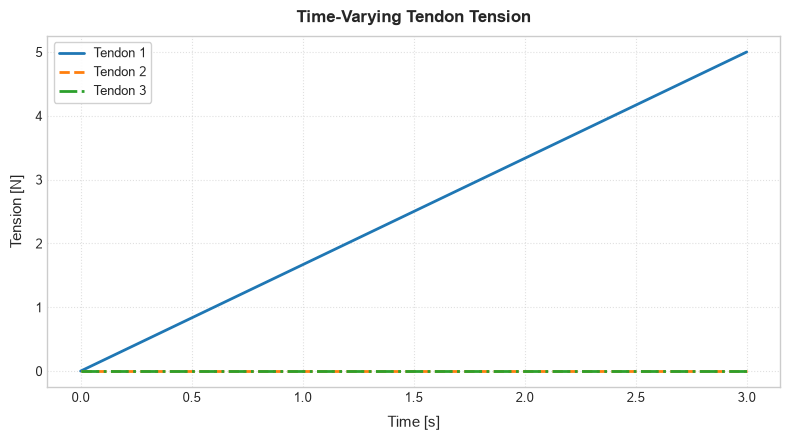

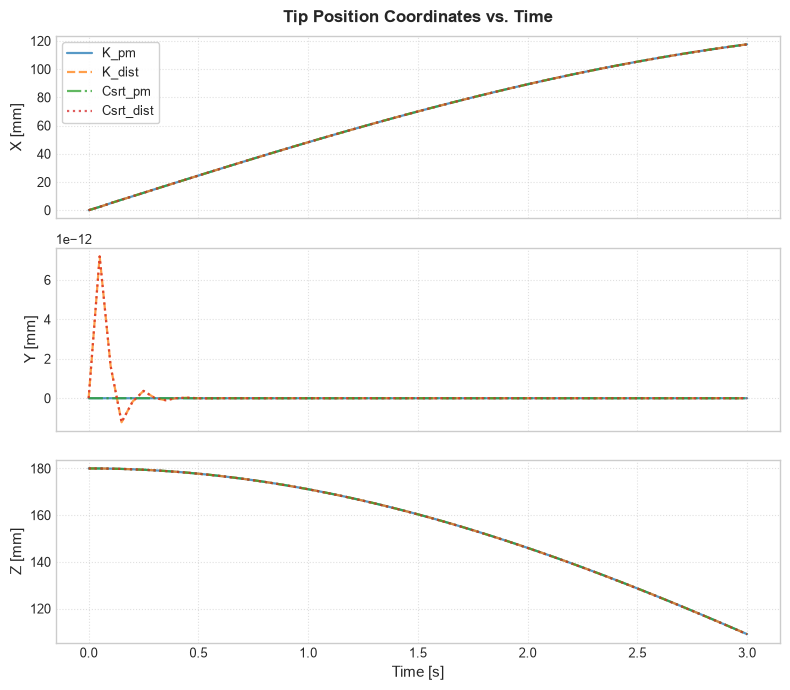

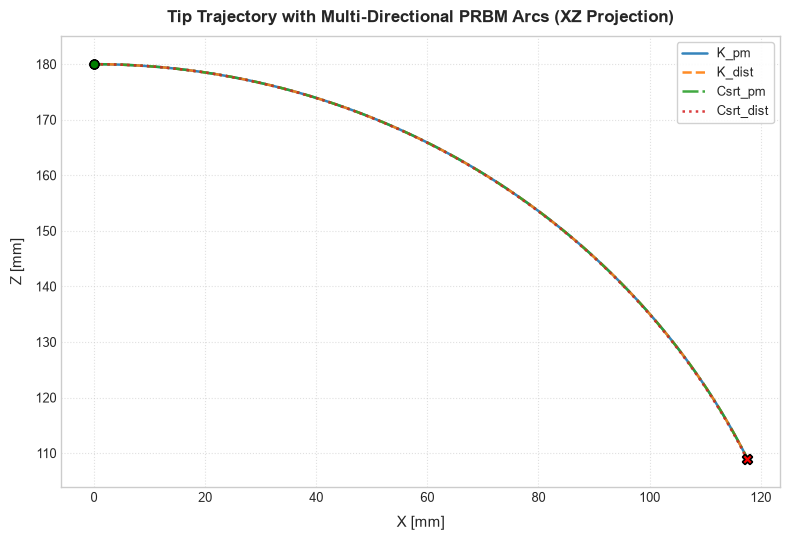

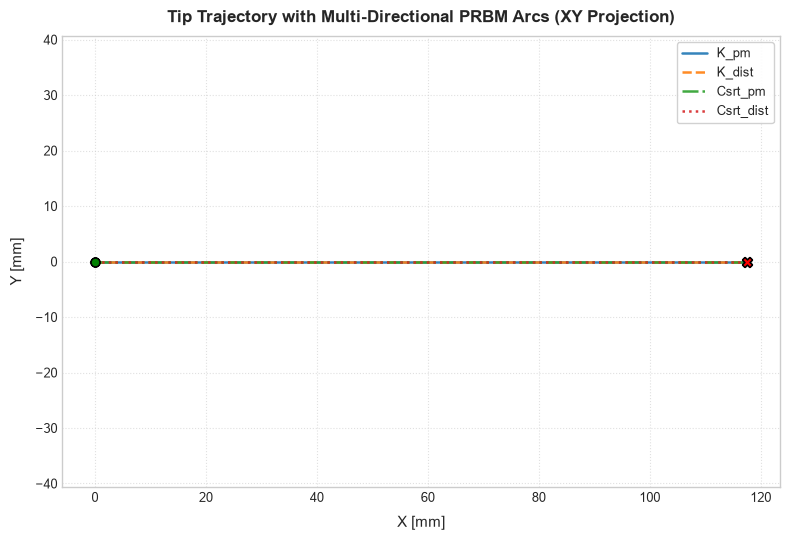

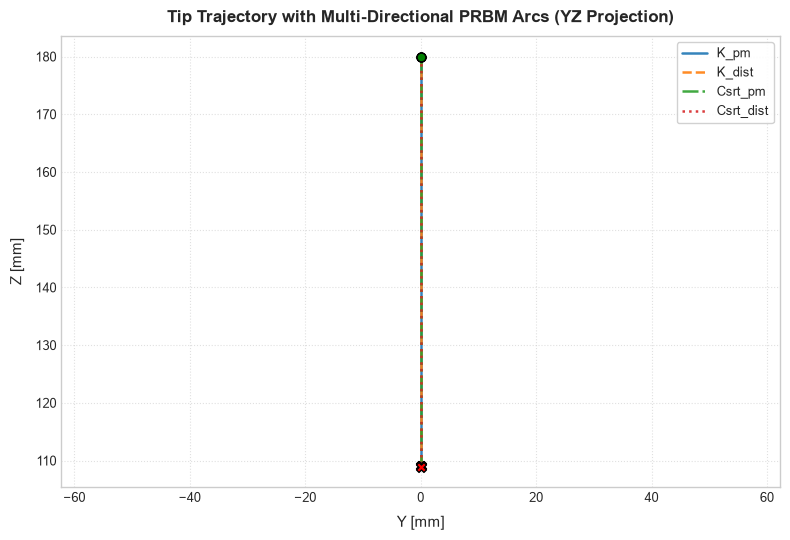


Loading condition 2: T2 Linear Ramp


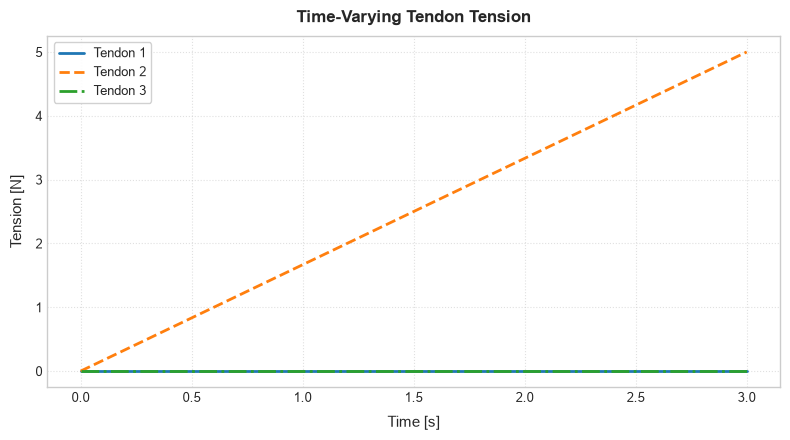

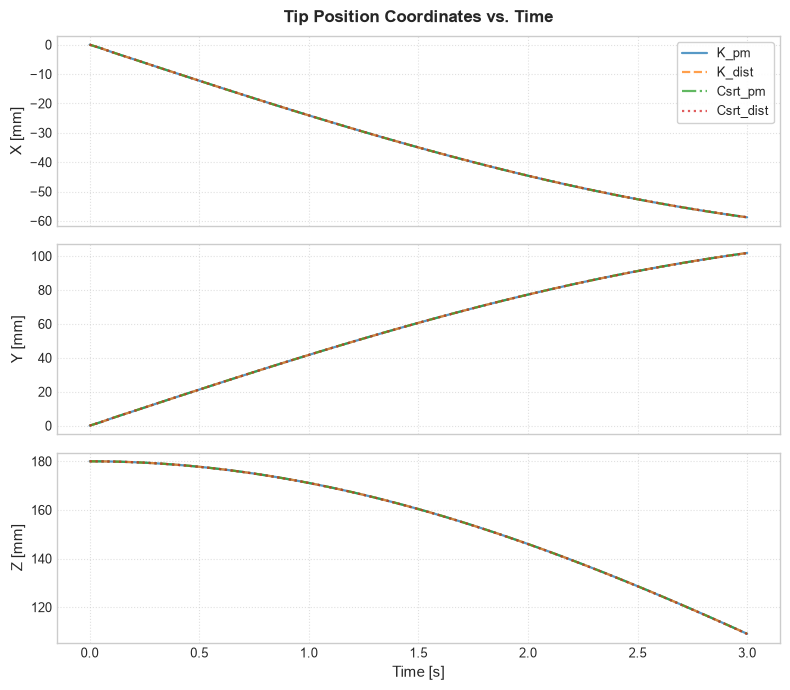

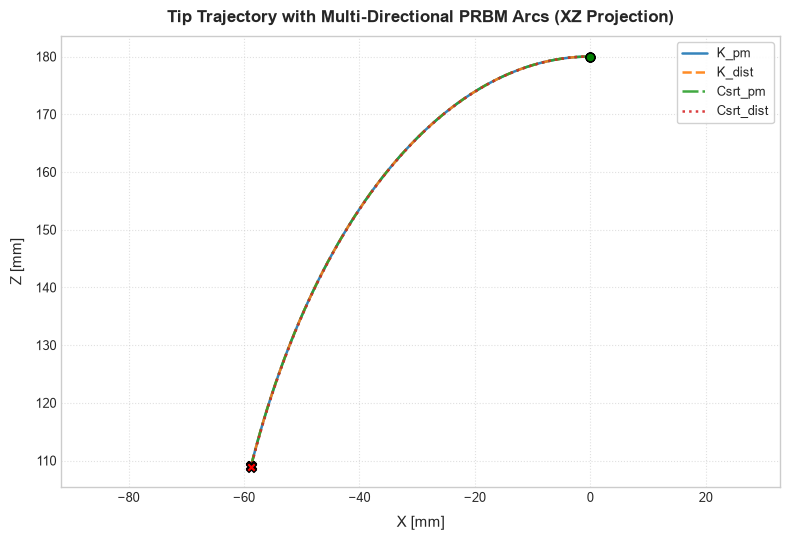

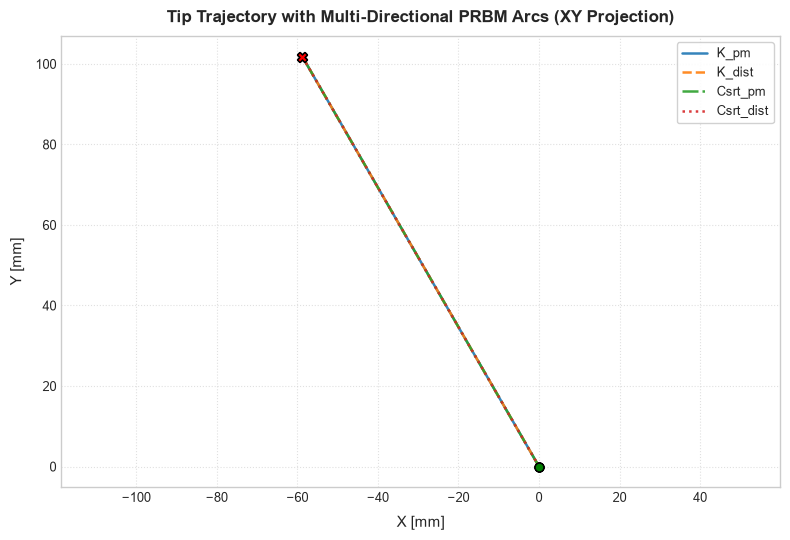

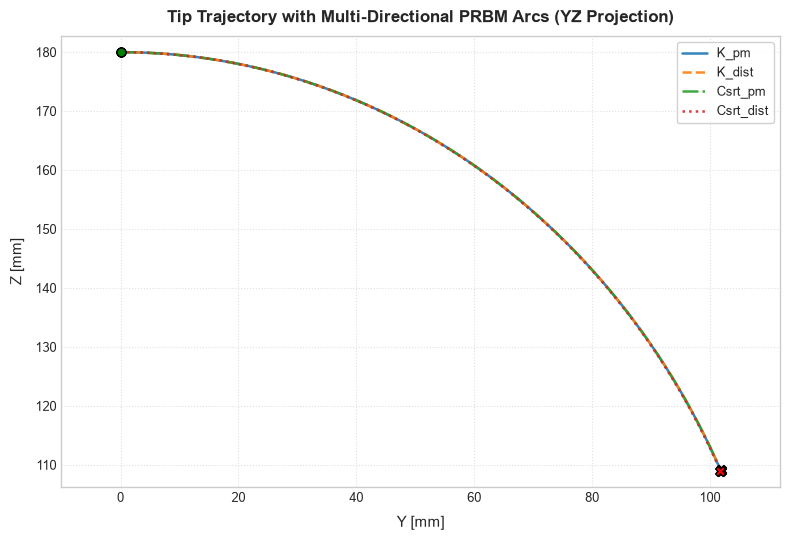


Loading condition 3: T3 Linear Ramp


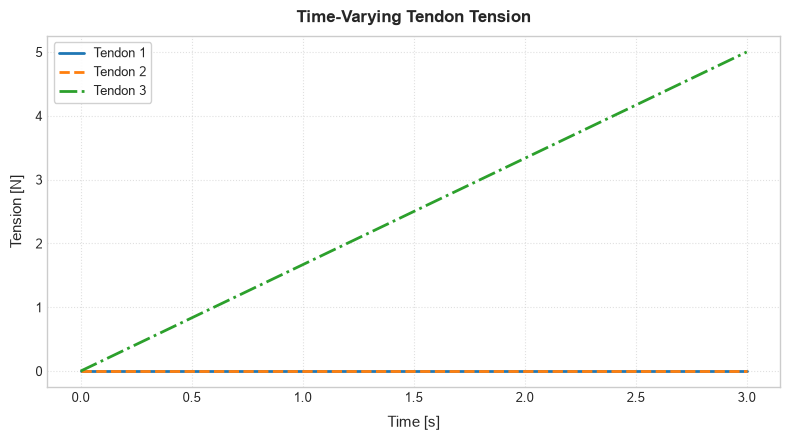

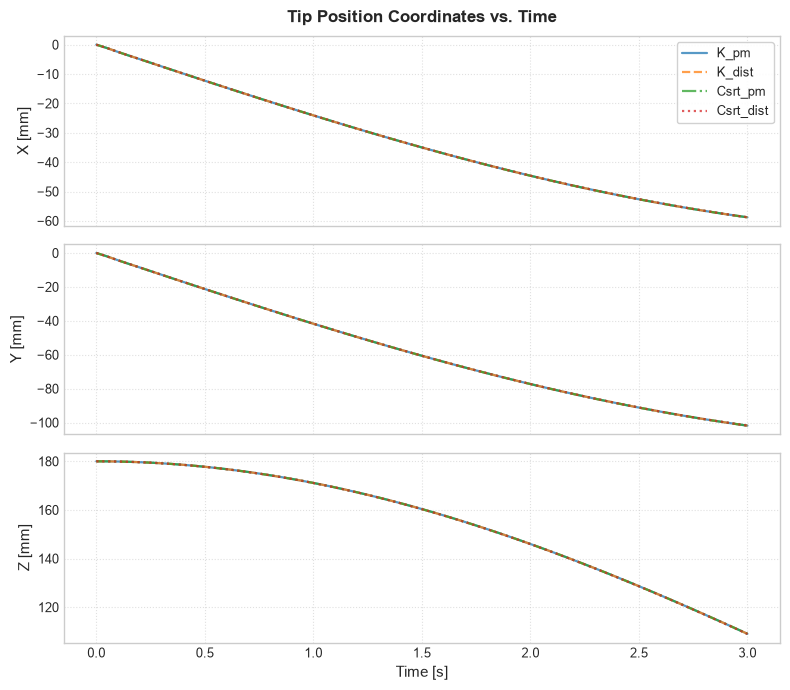

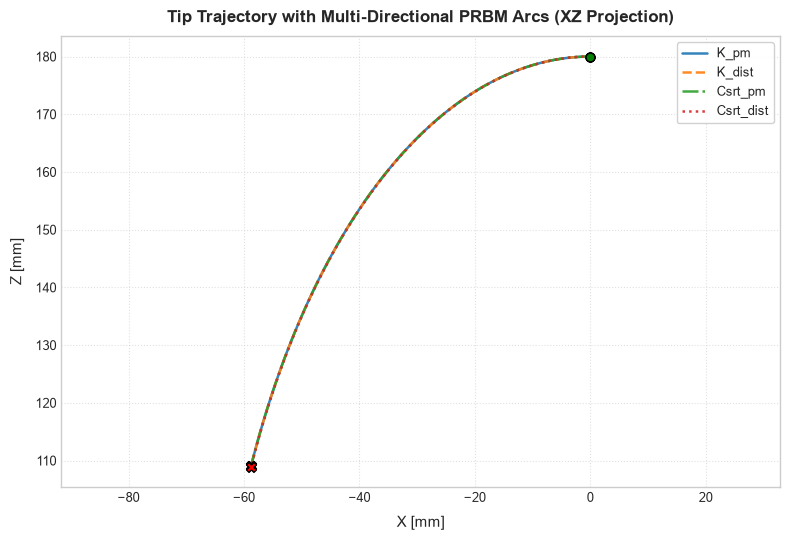

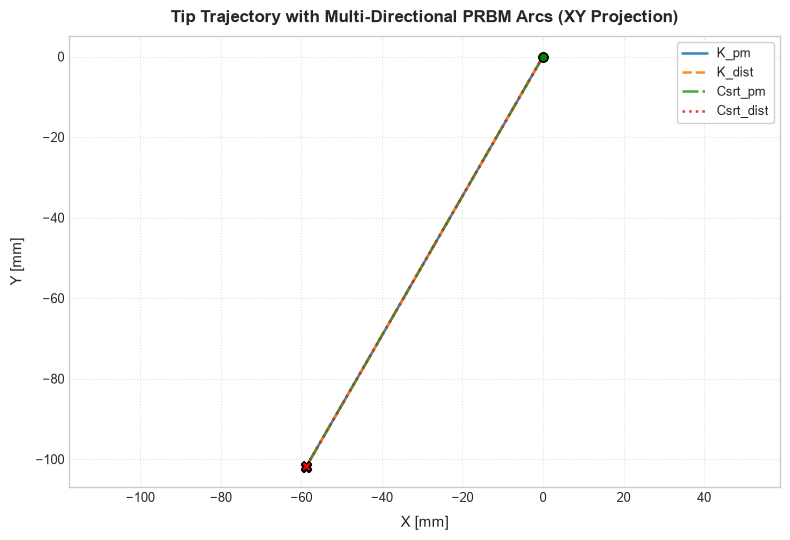

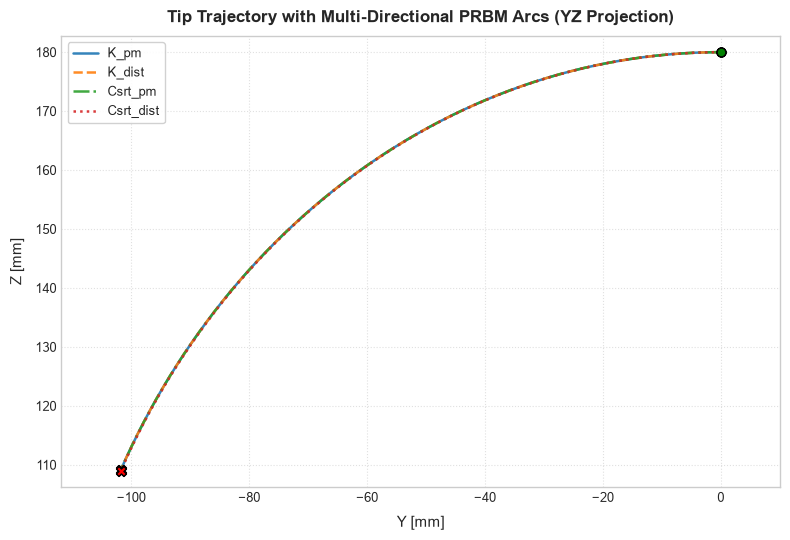

In [169]:
labels_all = ["K_pm", "K_dist", "Csrt_pm","Csrt_dist"]

for case_id in selected_cases:
    print(f"\nLoading condition {case_id}: {case_names[case_id]}")
    d = all_by_case[case_id]
    labs = [l for l in labels_all if l in d]
    res  = [d[l] for l in labs]
    Plots.plot_tensions(d["Csrt_dist"]["time"], kirchhoff_results[case_id]["tendons"])
    
    Plots.plot_tip_coordinates(res, labs)
    Plots.plot_tip_trajectory2(res, labs, plane="XZ",hinge=hinge,draw_arc_approx=False)
    Plots.plot_tip_trajectory2(res, labs, plane="XY",hinge=hinge,draw_arc_approx=False)
    Plots.plot_tip_trajectory2(res, labs, plane="YZ",hinge=hinge,draw_arc_approx=False)
    #Plots.plot_internal_wrench_snapshots(res2,labs2)
    #Plots.plot_internal_wrench_time_history(res2,labs2)
    #Plots.plot_backbone_snapshots(res,labs, snapshot="final", tip_force=tip_ext_force, load_scale=0.05)
    plt.show()


Loading condition 1: T1 Linear Ramp


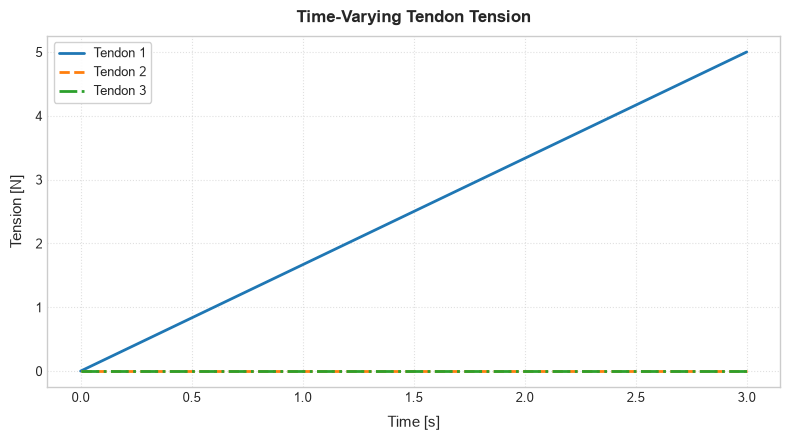

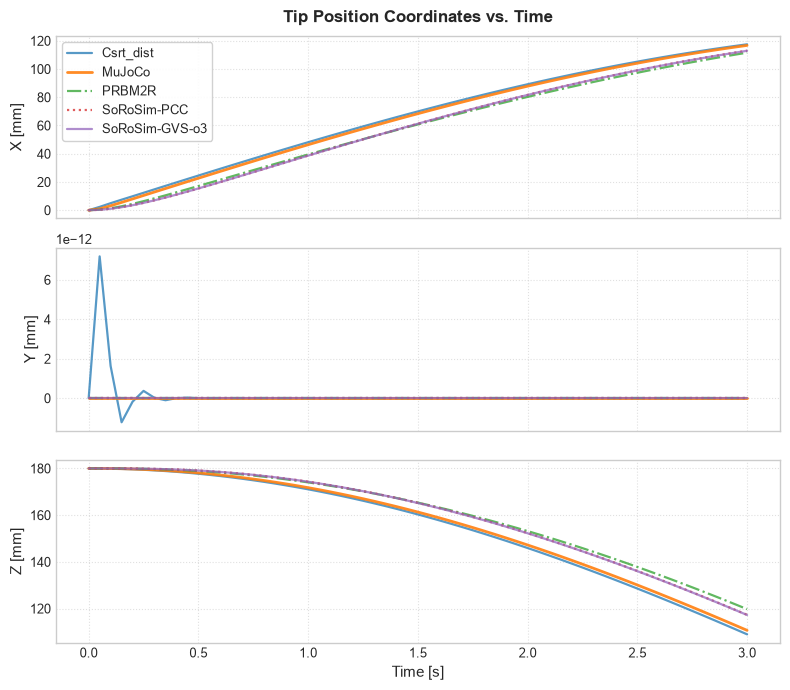

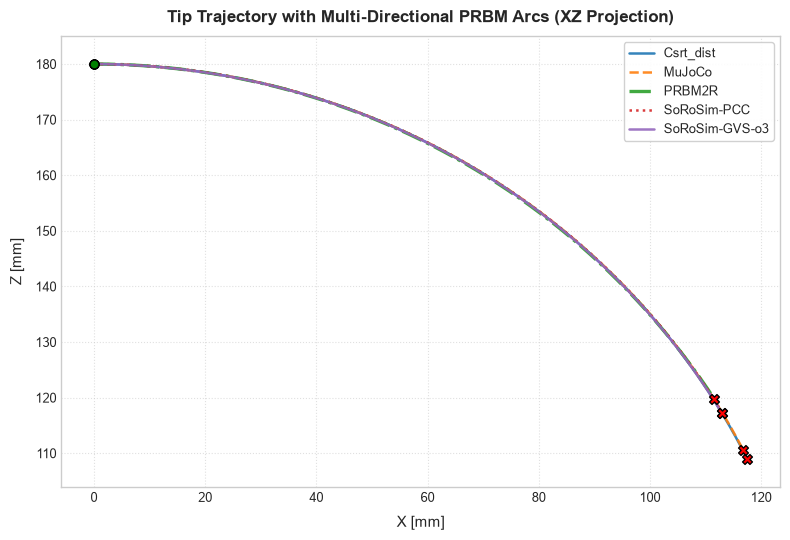

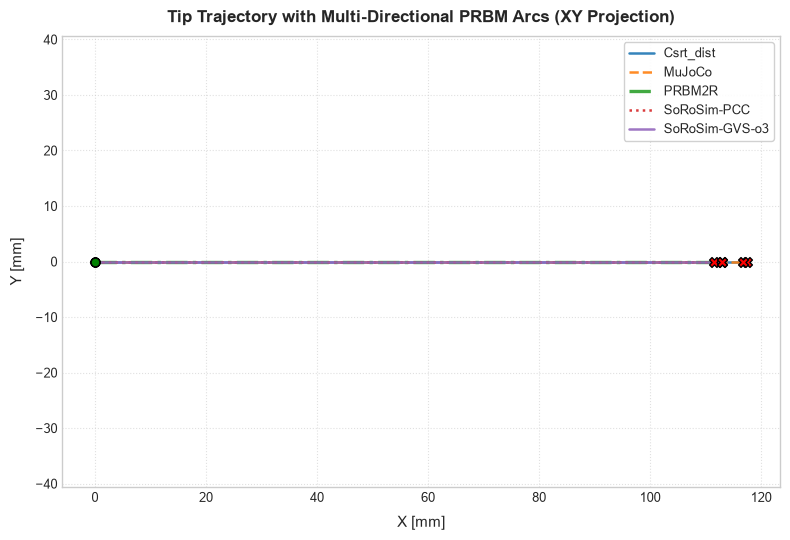

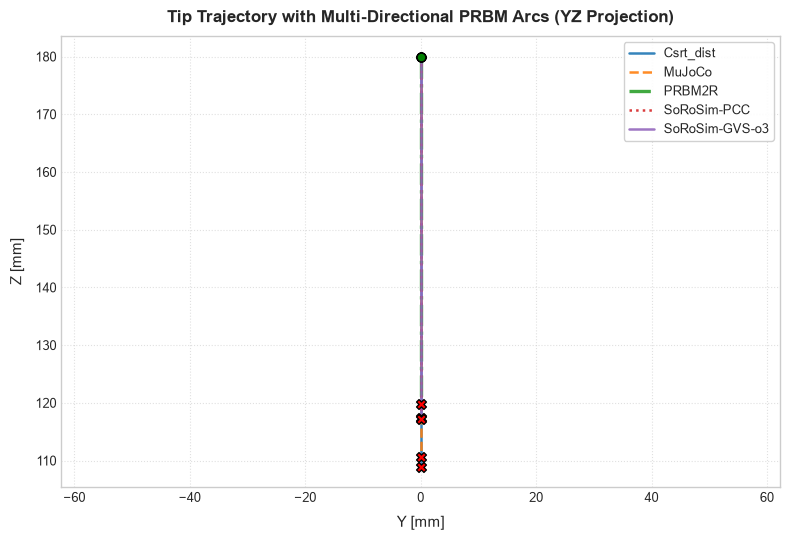


Loading condition 2: T2 Linear Ramp


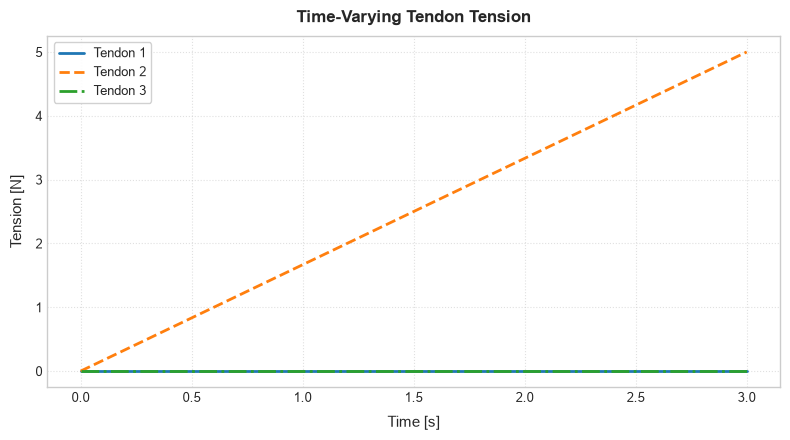

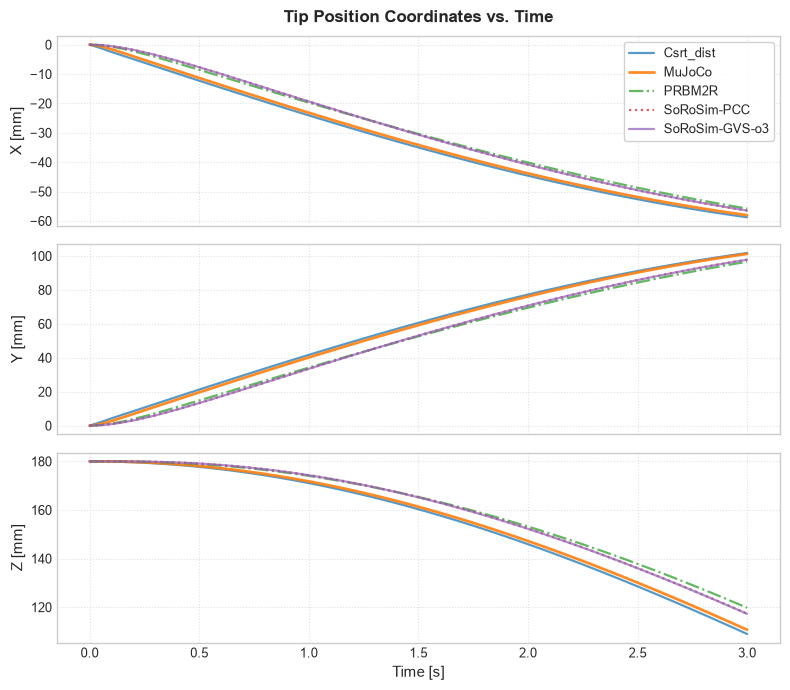

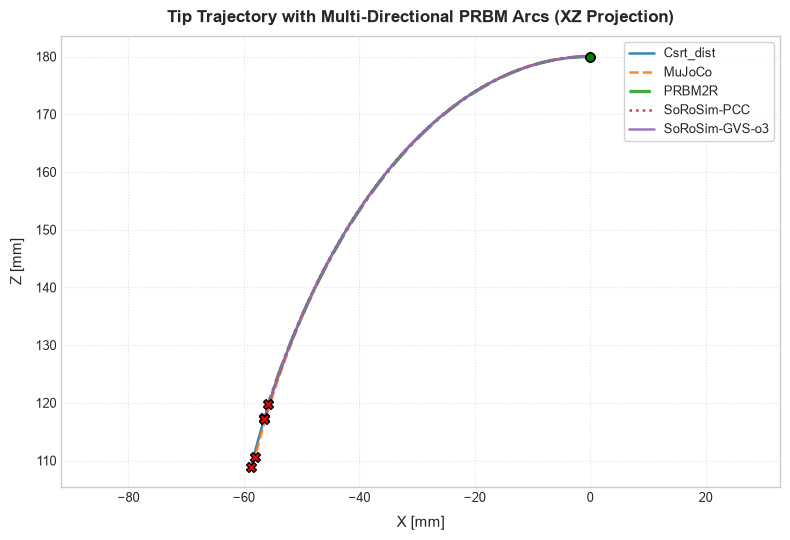

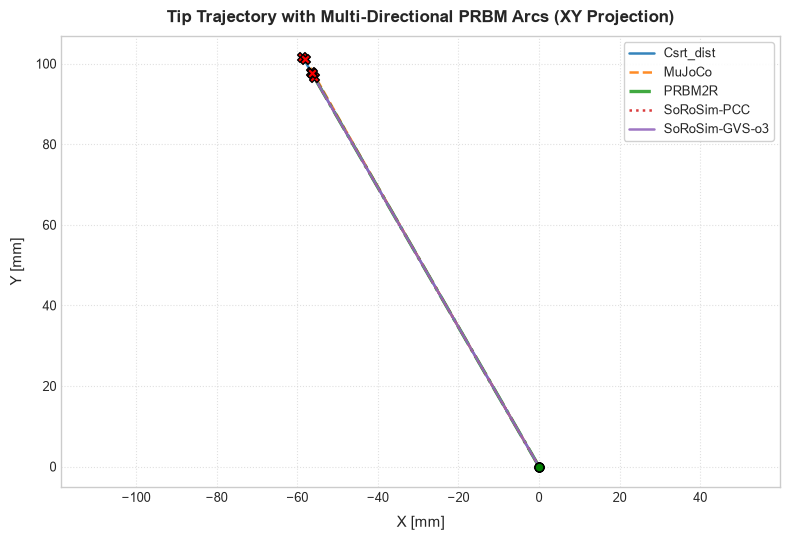

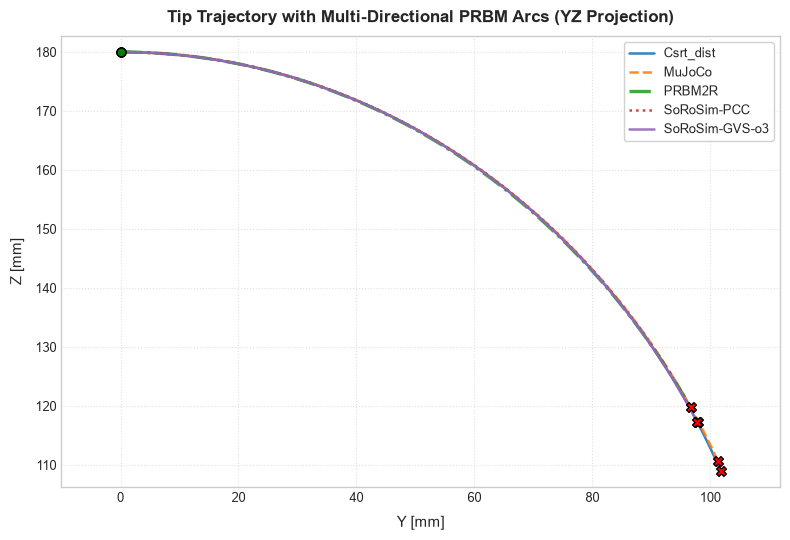


Loading condition 3: T3 Linear Ramp


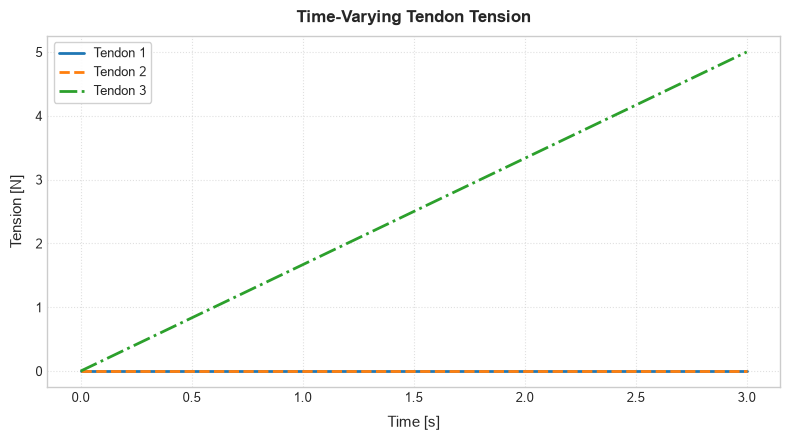

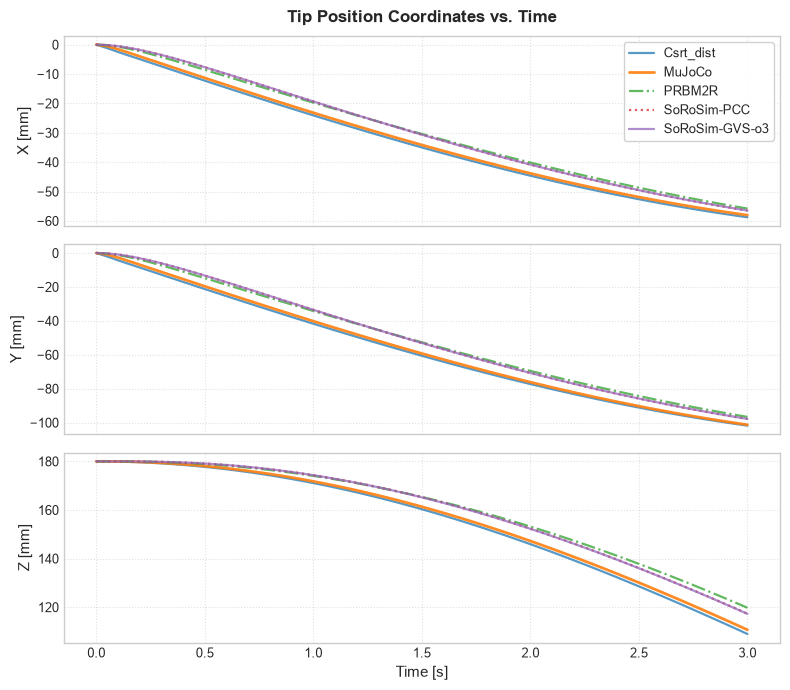

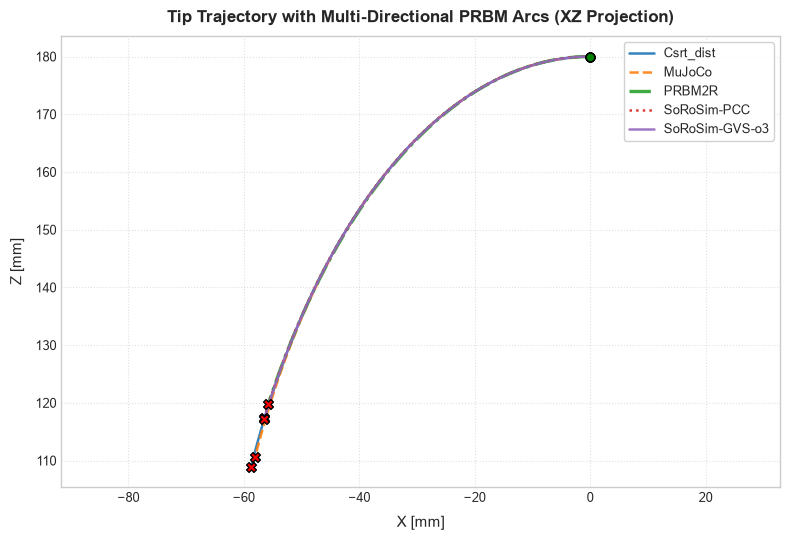

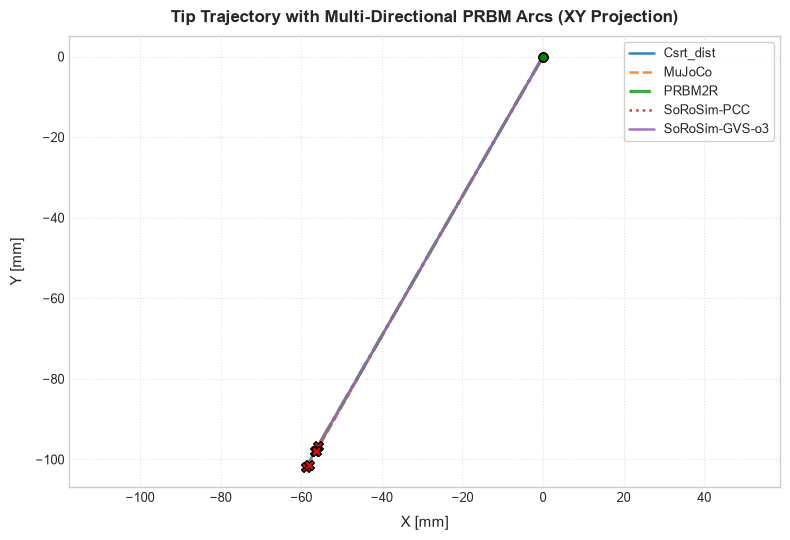

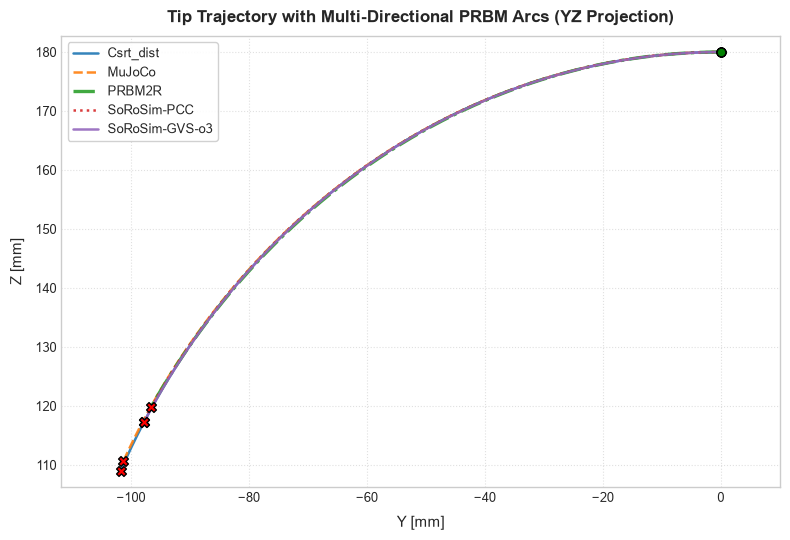

In [170]:
labels_all = ["Csrt_dist", "MuJoCo", "PRBM2R", "SoRoSim-PCC", "SoRoSim-PCS", "SoRoSim-GVS-o3"]

for case_id in selected_cases:
    print(f"\nLoading condition {case_id}: {case_names[case_id]}")
    d = all_by_case[case_id]
    labs = [l for l in labels_all if l in d]
    res  = [d[l] for l in labs]
    Plots.plot_tensions(d["Csrt_dist"]["time"], kirchhoff_results[case_id]["tendons"])
    
    Plots.plot_tip_coordinates(res, labs)
    Plots.plot_tip_trajectory2(res, labs, plane="XZ",hinge=hinge,draw_arc_approx=False)
    Plots.plot_tip_trajectory2(res, labs, plane="XY",hinge=hinge,draw_arc_approx=False)
    Plots.plot_tip_trajectory2(res, labs, plane="YZ",hinge=hinge,draw_arc_approx=False)
    #Plots.plot_internal_wrench_snapshots(res2,labs2)
    #Plots.plot_internal_wrench_time_history(res2,labs2)
    #Plots.plot_backbone_snapshots(res,labs, snapshot="final", tip_force=tip_ext_force, load_scale=0.05)
    plt.show()